# From Forecasts to Decisions: Cannibalization and Shared Capacity

Suppose that a retail chain sells $20$ products in $10$ stores, which gives $200$ store-product series. The chain plans a promotion week in which three products get a $30\%$ price cut.

The promoted products sell more, and their close substitutes sell less. This loss of demand of the substitutes is called **cannibalization**.

At the same time, every store can receive a fixed number of units per day, so the orders of the products of a store compete for the same capacity. We have to decide today how many units of each product to order for each store on each of the next $15$ days.

In the [first post](https://juanitorduz.github.io/forecast_to_decision/) we planned the orders of one product. We turned the posterior predictive draws of a demand model into demand scenarios, ran an inventory simulator on them, and minimized a loss with two prices: a holding cost per unit left over and a lost margin per unit short.

We saw that a plan built on a point forecast is the most expensive one on every metric, and that plans built on the same scenarios under different decision rules differ by tens of percent in cost. Here we apply the same steps to many series that share a promotion calendar and a capacity.

We want to answer three questions:

1. How much more does a plan cost when its forecast ignores cannibalization?
2. Which products and which days are behind that extra cost?
3. Does the shared capacity change the answer?

To answer them we fit two forecasting models to the same data. The **independent model** has no link between the products of a group. The **cross model** adds a cross-price term that moves demand between the products of a substitution group.

We build the same plans on the scenarios of each model and score them on draws from the true demand process, which we know because the data are synthetic.

Three things change with respect to the first post.

- **Many series.** We fit the $200$ series jointly. Cannibalization as the cross-item part of a promotion bump is well documented in the marketing literature, see [van Heerde, Leeflang and Wittink (2004)](https://doi.org/10.1287/mksc.1040.0061).
- **Shared capacity.** The clip at zero of the projected gradient solver becomes a projection onto the set of non-negative orders that fit the daily capacity of the store.
- **Variational inference.** With about $73K$ latent variables and two models to fit, we replace the NUTS sampler by stochastic variational inference (SVI) and replace its diagnostics by checks against the known truth.

We leave the choice of the promotion itself, margins, lead times and a rolling horizon out of scope. The real-data version of this problem, with the promotion as the decision, is the [promotion pricing example](https://github.com/juanitorduz/numpyro_forecast/pull/121) of [`numpyro_forecast`](https://juanitorduz.github.io/numpyro_forecast/) (a pull request at the time of writing). The inventory setting with its shortage and holding costs follows the VN2 challenge described by [Szabłowski (2026)](https://arxiv.org/abs/2601.18919).

We assume that you have read the first post. We do not derive the loss, the decision rules or the solver again, and we reuse the simulator and the solver with the few changes the new problem needs.

Here is the outline:

1. **Prepare Notebook.** Imports and plotting defaults.
2. **The Decision Problem.** The loss over many series, the capacity constraint and its projection.
3. **Generate Data.** The panel, the promotion calendar, the demand model with cross-price effects, the priors elicited with PreliZ, one draw of the history and the realized future, and the evaluation scenarios.
4. **Forecasting Model.** The independent model and the cross model.
5. **Prior Predictive Checks.** Draws from the priors of the cross model against the data.
6. **Model Fitting.** SVI with a mean-field guide, the parameterization of the random walk, and the fits of both models.
7. **Parameter Recovery.** The posterior against the true parameters and the true level of every series.
8. **Posterior Predictive Checks.** The fit on the history and the calibration of the forecast.
9. **Demand Scenarios.** The optimization scenarios of each model, the capacity, and where the forecasts start.
10. **Inventory Simulator.** The simulation over many series and the mean forecast plans.
11. **Decision Plans.** The expected cost plans of each model and what they order.
12. **Out of Sample Evaluation.** Scores on the evaluation scenarios, and the products and days behind the cost of ignoring cannibalization.
13. **Capacity Sensitivity.** The gap between the plans as the capacity tightens.
14. **Conclusion.** What we learned.
15. **Next Steps.** Extensions.

## Prepare Notebook

In [1]:
import warnings
from collections.abc import Callable
from enum import StrEnum
from functools import partial
from typing import NamedTuple

import arviz as az
import graphviz as gr
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import optax
import polars as pl
import preliz as pz
import seaborn as sns
import xarray as xr
from jax import random
from jaxtyping import Array, Bool, Float, Int, PRNGKeyArray, ScalarLike, Shaped
from matplotlib.ticker import PercentFormatter
from numpyro import handlers
from numpyro.handlers import do
from numpyro.infer import SVI, Predictive, Trace_ELBO
from numpyro.infer.autoguide import AutoNormal
from numpyro.infer.initialization import init_to_median
from numpyro.infer.reparam import LocScaleReparam
from numpyro.infer.svi import SVIRunResult
from numpyro.optim import optax_to_numpyro
from numpyro_forecast import (
    Horizon,
    draw_posterior,
    forecast,
    innovations,
    predict,
    predict_in_sample,
    time_reparam,
)
from numpyro_forecast.evaluate import eval_coverage
from numpyro_forecast.features import fourier_features
from numpyro_forecast.metrics import crps_empirical
from numpyro_forecast.typing import ForecastModel

# PreliZ warns that PyMC is not installed, which we do not need here
warnings.filterwarnings("ignore", category=UserWarning, module="preliz")

seed: int = 42
rng: np.random.Generator = np.random.default_rng(seed=seed)
rng_key: PRNGKeyArray = random.PRNGKey(seed)

CI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "eti"
az.rcParams["stats.ci_prob"] = CI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"
pl.Config(float_precision=3, tbl_rows=20, tbl_width_chars=160, fmt_str_lengths=80)

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

## The Decision Problem

First, we write the loss over many series and the capacity that links them.

We index the stores by $s = 1, \dots, S$ and the products by $j = 1, \dots, P$. Every product belongs to one **substitution group** $g(j)$ of $K$ products, and there are $G$ groups.

A **series** is a store and product pair $i = (s, j)$, and there are $M = S P$ of them. Let $H$ be the **number of days in the planning horizon** and let $D_{t,i}$ be the **demand of series** $i$ **on day** $t$.

Recall from the first post that at the start of a day we receive the units ordered in advance, that customers buy what is there and go elsewhere for the rest, and that a leftover unit stays on the shelf. Let $a_{t,i} \geq 0$ be the **order** of series $i$ on day $t$, $I_{t,i}$ the **stock on hand** at the end of the day, and $U_{t,i}$ the **lost sales**, the unmet demand of the day.

These quantities follow the same dynamics as before, series by series. The whole plan is the array $a = (a_{t,i})$ of $H \times M$ orders.

Two unit costs define the loss. Let $h$ be the **holding cost** of one unit that sits on the shelf at the end of a day, and let $p$ be the **lost margin** of one unit of demand that we cannot serve. The **loss** of the plan $a$ against the demand paths $D = (D_{t,i})$ adds up over the series:

$$
L(a, D) = \sum_{t=1}^{H} \sum_{i=1}^{M} \left[ h \, I_{t,i} + p \, U_{t,i} \right].
$$

Note that the loss is additive over the series. Without a constraint that links the series, the plan that minimizes the expected loss would split into $M$ copies of the single-series problem, and the only thing a joint forecast would change is the scenarios of each series.

The link comes from the **capacity**. Store $s$ can receive at most $C_s$ units per day over all its products,

$$
\sum_{j=1}^{P} a_{t,(s,j)} \leq C_s \quad \text{for every day } t \text{ and store } s.
$$

In the first post the solver kept the orders feasible by clipping them at zero after every gradient step. The clip is the Euclidean projection onto the set of non-negative orders. The feasible set of one store and one day is now

$$
A_C = \left\{ a \in \mathbb{R}^P : a \geq 0, \; \sum_{j=1}^{P} a_j \leq C \right\},
$$

and the clip becomes the **Euclidean projection** onto $A_C$, the closest point of $A_C$ to the vector of orders. The projection has two cases.

- **Slack capacity.** If the clipped vector $\max(a, 0)$ fits the capacity, it is the projection. It is the closest non-negative vector, and it is in $A_C$.
- **Full capacity.** If the clipped vector exceeds the capacity, the projection lies on the face $\sum_j a_j = C$. On the face, the projection subtracts one common **threshold** $\theta$ from every order and clips at zero, with $\theta$ chosen so that the result sums to $C$. This is the projection onto a simplex, and [Duchi et al. (2008)](https://doi.org/10.1145/1390156.1390191) give the sort-based algorithm that finds $\theta$ (their Algorithm $1$).

To see why the capacity binds in the second case, suppose that the projection had slack capacity. Then it would also be the closest point of the non-negative orthant, which is the clipped vector, and the clipped vector does not fit.

To make this concrete, we store the costs in the `InventoryConfig` tuple, write the projection, and draw it in two dimensions.

In [2]:
class InventoryConfig(NamedTuple):
    """Costs of the inventory problem."""

    holding_cost: float
    lost_sales_cost: float


config = InventoryConfig(holding_cost=0.1, lost_sales_cost=2.0)

The function `project_capacity` implements the two cases. Four checks follow the definition:

- **Feasible point.** It comes back unchanged.
- **Example by hand.** The vector $[3, -1, 2]$ with a capacity of $4$ projects to $[2.5, 0, 1.5]$.
- **Random point.** The projection subtracts the same amount from every order that stays positive.
- **No capacity.** The projection is the clip at zero, which the *Capacity Sensitivity* section relies on.

In [3]:
def project_capacity(
    a: Float[Array, " n_products"], capacity: ScalarLike
) -> Float[Array, " n_products"]:
    """Euclidean projection onto {a >= 0, sum(a) <= capacity}."""
    clipped = jnp.maximum(a, 0.0)
    # projection onto the simplex {a >= 0, sum(a) = capacity} (Duchi et al., 2008)
    u = jnp.sort(a)[::-1]
    cumulative = jnp.cumsum(u)
    k = jnp.arange(1, a.shape[0] + 1)
    rho = jnp.max(jnp.where(u - (cumulative - capacity) / k > 0.0, k, 0))
    theta = (cumulative[rho - 1] - capacity) / rho
    on_simplex = jnp.maximum(a - theta, 0.0)
    return jnp.where(clipped.sum() <= capacity, clipped, on_simplex)


# the orders of one day for every store: (n_stores, n_products), capacity: (n_stores,)
project_day = jax.vmap(project_capacity, in_axes=(0, 0))
# the orders of the whole horizon: (horizon, n_stores, n_products)
project_orders = jax.vmap(project_day, in_axes=(0, None))

feasible = jnp.array([1.0, 2.0, 0.5])
assert jnp.allclose(project_capacity(feasible, 4.0), feasible)
assert jnp.allclose(
    project_capacity(jnp.array([3.0, -1.0, 2.0]), 4.0), jnp.array([2.5, 0.0, 1.5])
)
# this draw advances `rng`, which also draws the true parameters below, so the
# data depend on it: changing it changes the panel
point = jnp.asarray(rng.normal(size=20)) * 5
projection = project_capacity(point, 10.0)
assert jnp.allclose(projection.sum(), 10.0) and bool((projection >= 0).all())
gap = (point - projection)[projection > 0]
assert jnp.allclose(gap, gap[0], atol=1e-4)
assert jnp.allclose(project_capacity(point, jnp.inf), jnp.maximum(point, 0.0))

The next figure shows the projection in two dimensions, for three points and a capacity of $10$ units.

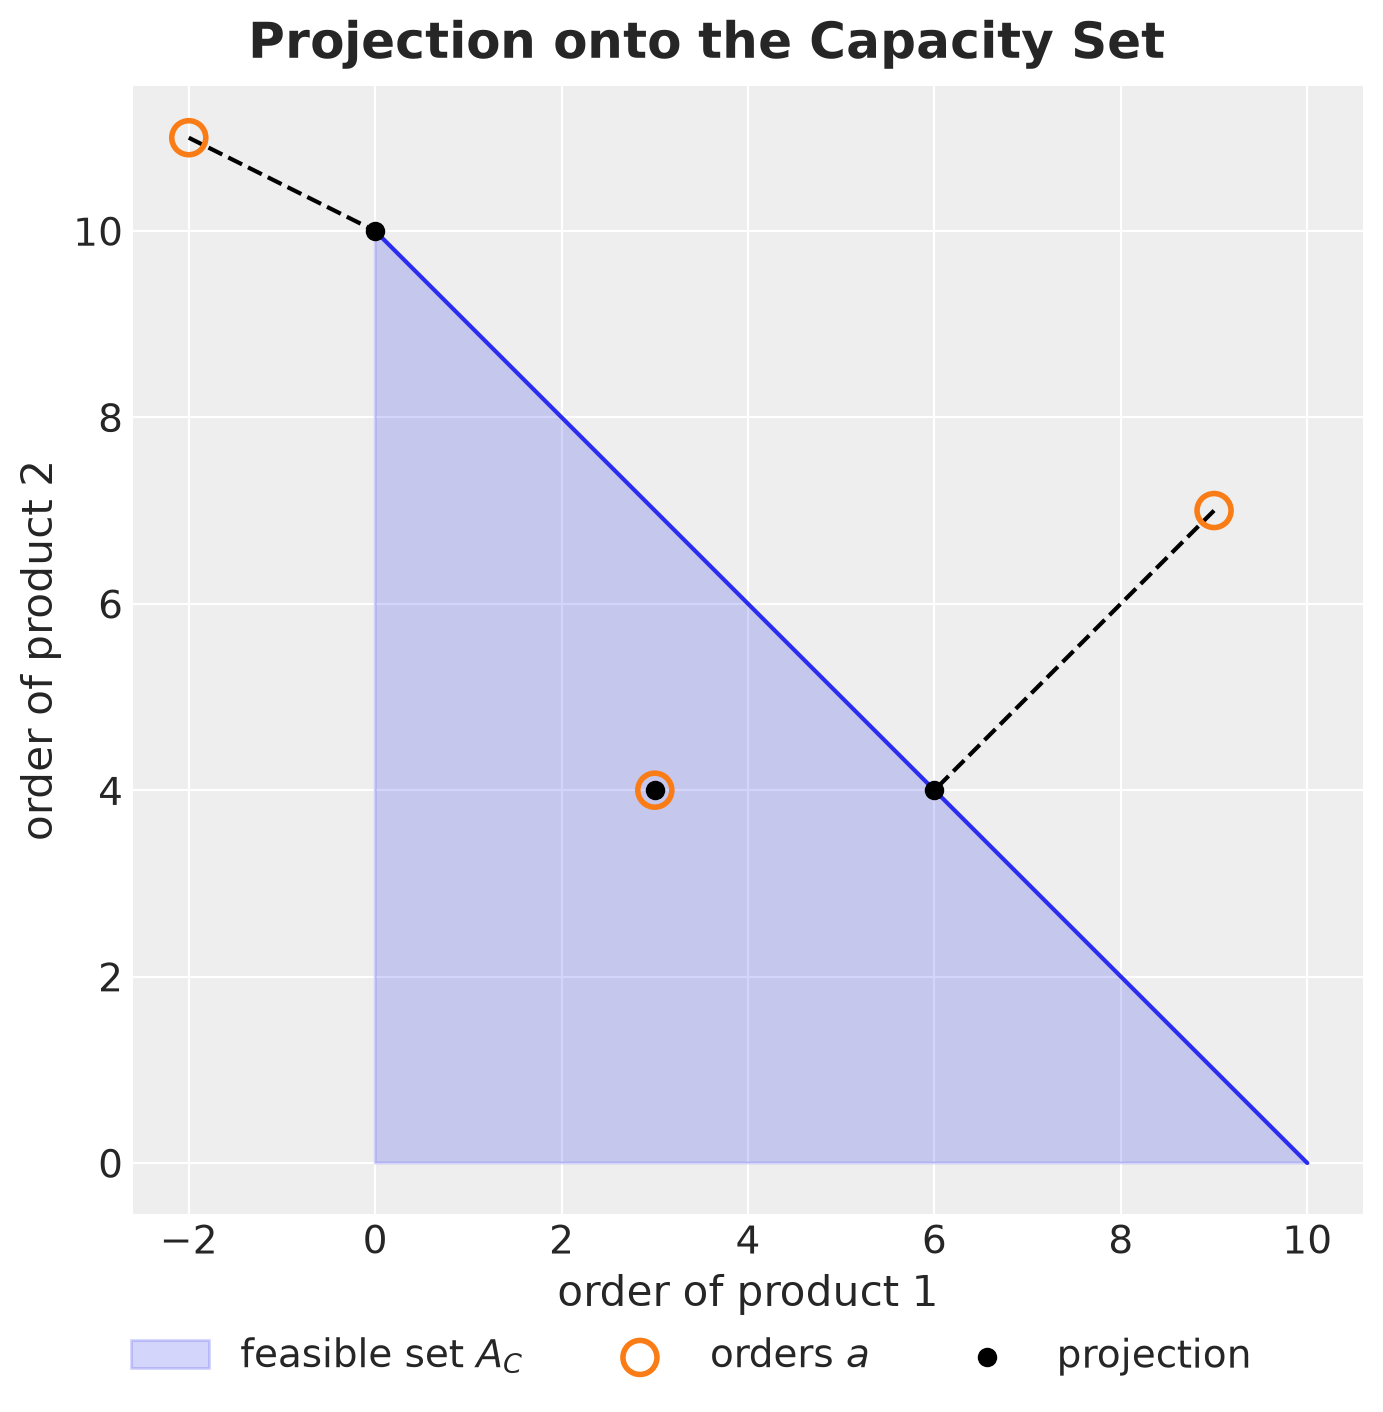

In [4]:
capacity_example = 10.0
points = jnp.array([[3.0, 4.0], [-2.0, 11.0], [9.0, 7.0]])
projected = jax.vmap(project_capacity, in_axes=(0, None))(points, capacity_example)

fig, ax = plt.subplots(figsize=(7, 7))
ax.fill(
    [0, capacity_example, 0],
    [0, 0, capacity_example],
    color="C0",
    alpha=0.2,
    label="feasible set $A_C$",
)
ax.plot([0, capacity_example], [capacity_example, 0], color="C0")
for (x, y), (px, py) in zip(points, projected, strict=True):
    ax.plot([x, px], [y, py], "--", color="black")
ax.scatter(
    points[:, 0],
    points[:, 1],
    s=150,
    facecolors="none",
    edgecolors="C1",
    linewidths=2,
    zorder=3,
    label="orders $a$",
)
ax.scatter(
    projected[:, 0], projected[:, 1], color="black", zorder=4, label="projection"
)
ax.set(xlabel="order of product 1", ylabel="order of product 2", aspect="equal")
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Projection onto the Capacity Set", fontsize=18, fontweight="bold");

The three points show the three cases.

- **Inside the triangle.** The point stays where it is.
- **Above the diagonal.** The point moves along the normal of the face, so the projection takes the same amount from both products.
- **Negative coordinate.** The point ends at the corner where the whole capacity goes to product $2$.

## Generate Data

We generate the data from a known demand process, so that we can score the plans against the truth.

### Panel and Calendar

The panel has $G = 5$ substitution groups of $K = 4$ products, so $P = 20$ products, sold in $S = 10$ stores, which gives $M = 200$ series. The history is one year of daily demand and the horizon is $15$ days.

The promotion calendar is chain-wide. A product is on promotion in all stores at once, at a $30\%$ discount, for a whole calendar week.

In every week of the history a product is on promotion with probability $0.1$, independently of the other products. In the horizon the chain plans a promotion for the first product of groups $1$, $2$ and $3$ in the second week.

The groups differ in how strong the cannibalization is. The true cross elasticity, which we define in the *Demand Model* section, is $0.6$ in group $1$, $0.3$ in groups $2$ and $4$, and zero in groups $3$ and $5$.

We give the products four **roles** for the horizon:

- `promoted`: the three promoted products.
- `sibling`: the nine other products of the promoted groups.
- `control (cross)`: group $4$, which has cannibalization in its history but no promotion in the horizon.
- `control (no cross)`: group $5$, which has neither.

We call two products of the same group **siblings**, so the `sibling` role is the siblings of the promoted products.

Groups $3$, $4$ and $5$ serve as checks. Group $3$ is promoted but has no cannibalization, so the cross model must learn not to move demand there. Group $4$ tells us what the sibling promotions of the past do to a model that cannot explain them.

Nothing in the demand of group $5$ depends on cannibalization, so the two models should give it the same forecast. Its orders can still differ between the two plans, because it shares the capacity with the other groups.

We store the sizes and the design of the experiment in a `Setup` tuple and the index arrays of the panel in a `Panel` tuple. The series are store-major, that is, series $i = s P + j$ with the store and the product indexed from zero. The `pair_rows` and `pair_cols` arrays list the within-group pairs of distinct products.

In the code and in the figures the products are numbered from zero, and the groups and the stores from one.

In [5]:
class Setup(NamedTuple):
    """Sizes of the panel and the horizon, and the design of the experiment."""

    t_obs: int = 364  # one year of daily history
    horizon: int = 15  # days to plan
    discount: float = 0.3  # price cut in a promotion week
    promo_prob: float = 0.1  # chance that a product is on promotion in a given week
    n_groups: int = 5  # substitution groups
    n_per_group: int = 4  # products per group
    n_stores: int = 10
    n_fourier_terms: int = 3  # harmonics of the weekly cycle
    # true cross elasticity of every group
    group_cross: tuple[float, ...] = (0.6, 0.3, 0.0, 0.3, 0.0)
    n_promoted_groups: int = 3  # the first product of these groups is promoted
    promo_start: int = 7  # first day of the planned promotion, counted in the horizon
    promo_end: int = 14  # the day after the last day of the planned promotion
    n_eval_scenarios: int = 3_000  # draws of the true process that score the plans
    capacity_multiple: float = 1.05  # capacity over the regular throughput of a store
    capacity_window: int = 56  # days of history behind the regular throughput
    stock_window: int = 28  # days of history behind the initial stock

    @property
    def n_products(self) -> int:
        return self.n_groups * self.n_per_group

    @property
    def n_series(self) -> int:
        return self.n_stores * self.n_products

    @property
    def n_fourier(self) -> int:
        return 2 * self.n_fourier_terms

    @property
    def n_weeks(self) -> int:
        return self.t_obs // 7

    @property
    def duration(self) -> int:
        return self.t_obs + self.horizon


class Panel(NamedTuple):
    """Index arrays of the panel. Series are store-major: series = store * P + j."""

    series_to_product: Int[np.ndarray, " n_series"]
    series_to_store: Int[np.ndarray, " n_series"]
    product_to_group: Int[np.ndarray, " n_products"]
    pair_rows: Int[np.ndarray, " n_pairs"]
    pair_cols: Int[np.ndarray, " n_pairs"]


class Role(StrEnum):
    """Role of a product in the horizon."""

    PROMOTED = "promoted"
    SIBLING = "sibling"
    CONTROL_CROSS = "control (cross)"
    CONTROL_NO_CROSS = "control (no cross)"


def make_panel(setup: Setup) -> Panel:
    """Build the index arrays and the within-group pairs of distinct products."""
    product_to_group = np.repeat(np.arange(setup.n_groups), setup.n_per_group)
    same_group = product_to_group[:, None] == product_to_group[None, :]
    off_diagonal = ~np.eye(setup.n_products, dtype=bool)
    pair_rows, pair_cols = np.where(same_group & off_diagonal)
    return Panel(
        series_to_product=np.tile(np.arange(setup.n_products), setup.n_stores),
        series_to_store=np.repeat(np.arange(setup.n_stores), setup.n_products),
        product_to_group=product_to_group,
        pair_rows=pair_rows,
        pair_cols=pair_cols,
    )


def assign_roles(setup: Setup, panel: Panel) -> Shaped[np.ndarray, " n_products"]:
    """Role of every product: promoted, sibling of a promoted product, or control."""
    in_promoted_group = panel.product_to_group < setup.n_promoted_groups
    first_of_group = np.arange(setup.n_products) % setup.n_per_group == 0
    has_cross = np.array(setup.group_cross)[panel.product_to_group] > 0
    return np.select(
        [in_promoted_group & first_of_group, in_promoted_group, has_cross],
        [Role.PROMOTED, Role.SIBLING, Role.CONTROL_CROSS],
        default=Role.CONTROL_NO_CROSS,
    )


setup = Setup()
panel = make_panel(setup)
assert (setup.n_products, setup.n_series, panel.pair_rows.size) == (20, 200, 60)

product_role = assign_roles(setup, panel)
series_role = product_role[panel.series_to_product]
promoted_products = np.flatnonzero(product_role == Role.PROMOTED)

days = np.arange(setup.duration)
days_future = days[setup.t_obs :]
fourier = fourier_features(setup.duration, period=7.0, num_terms=setup.n_fourier_terms)
# the planned promotion of the horizon
promo_future = (
    jnp.zeros((setup.horizon, setup.n_products))
    .at[setup.promo_start : setup.promo_end, promoted_products]
    .set(1.0)
)

products = pl.DataFrame(
    {
        "product": np.arange(setup.n_products),
        "group": panel.product_to_group + 1,
        "role": product_role,
    }
)
products.group_by("role").len().sort("role")

role,len
str,u32
"""control (cross)""",4
"""control (no cross)""",4
"""promoted""",3
"""sibling""",9


The four roles cover the $20$ products.

Besides the true parameters and the demand, the calendar is the only random input. We draw it from a small generative model, one Bernoulli per product and week, and append the planned horizon. The deterministic `log_price` site is the log of the price relative to the list price, $\log(1 - 0.3)$ in a promotion week and zero otherwise.

In [6]:
def calendar_generator(
    setup: Setup, promo_future: Float[Array, "horizon n_products"]
) -> None:
    """Chain-wide promotion weeks of the history, followed by the planned horizon."""
    with (
        numpyro.plate("product", setup.n_products, dim=-1),
        numpyro.plate("week", setup.n_weeks, dim=-2),
    ):
        promo_week = numpyro.sample("promo_week", dist.Bernoulli(setup.promo_prob))
    promo_history = jnp.repeat(promo_week, 7, axis=0)
    promo = jnp.concatenate([promo_history, promo_future], axis=0)
    numpyro.deterministic("promo", promo)
    numpyro.deterministic("log_price", promo * jnp.log(1.0 - setup.discount))


rng_key, key_calendar = random.split(rng_key)
calendar = Predictive(calendar_generator, num_samples=1)(
    key_calendar, setup, promo_future
)
log_price = calendar["log_price"][0]  # (duration, n_products)
promo_week_true = calendar["promo_week"][0]  # (n_weeks, n_products)
promo_full = calendar["promo"][0]  # (duration, n_products)

# one array of covariates: the Fourier columns, then one log price column per product
covariates = jnp.concatenate([fourier, log_price], axis=1)
covariates_train = covariates[: setup.t_obs]
assert covariates.shape == (setup.duration, setup.n_fourier + setup.n_products)

The following figure shows the calendar, one row per product, and the number of promotion weeks of every product and of its siblings.

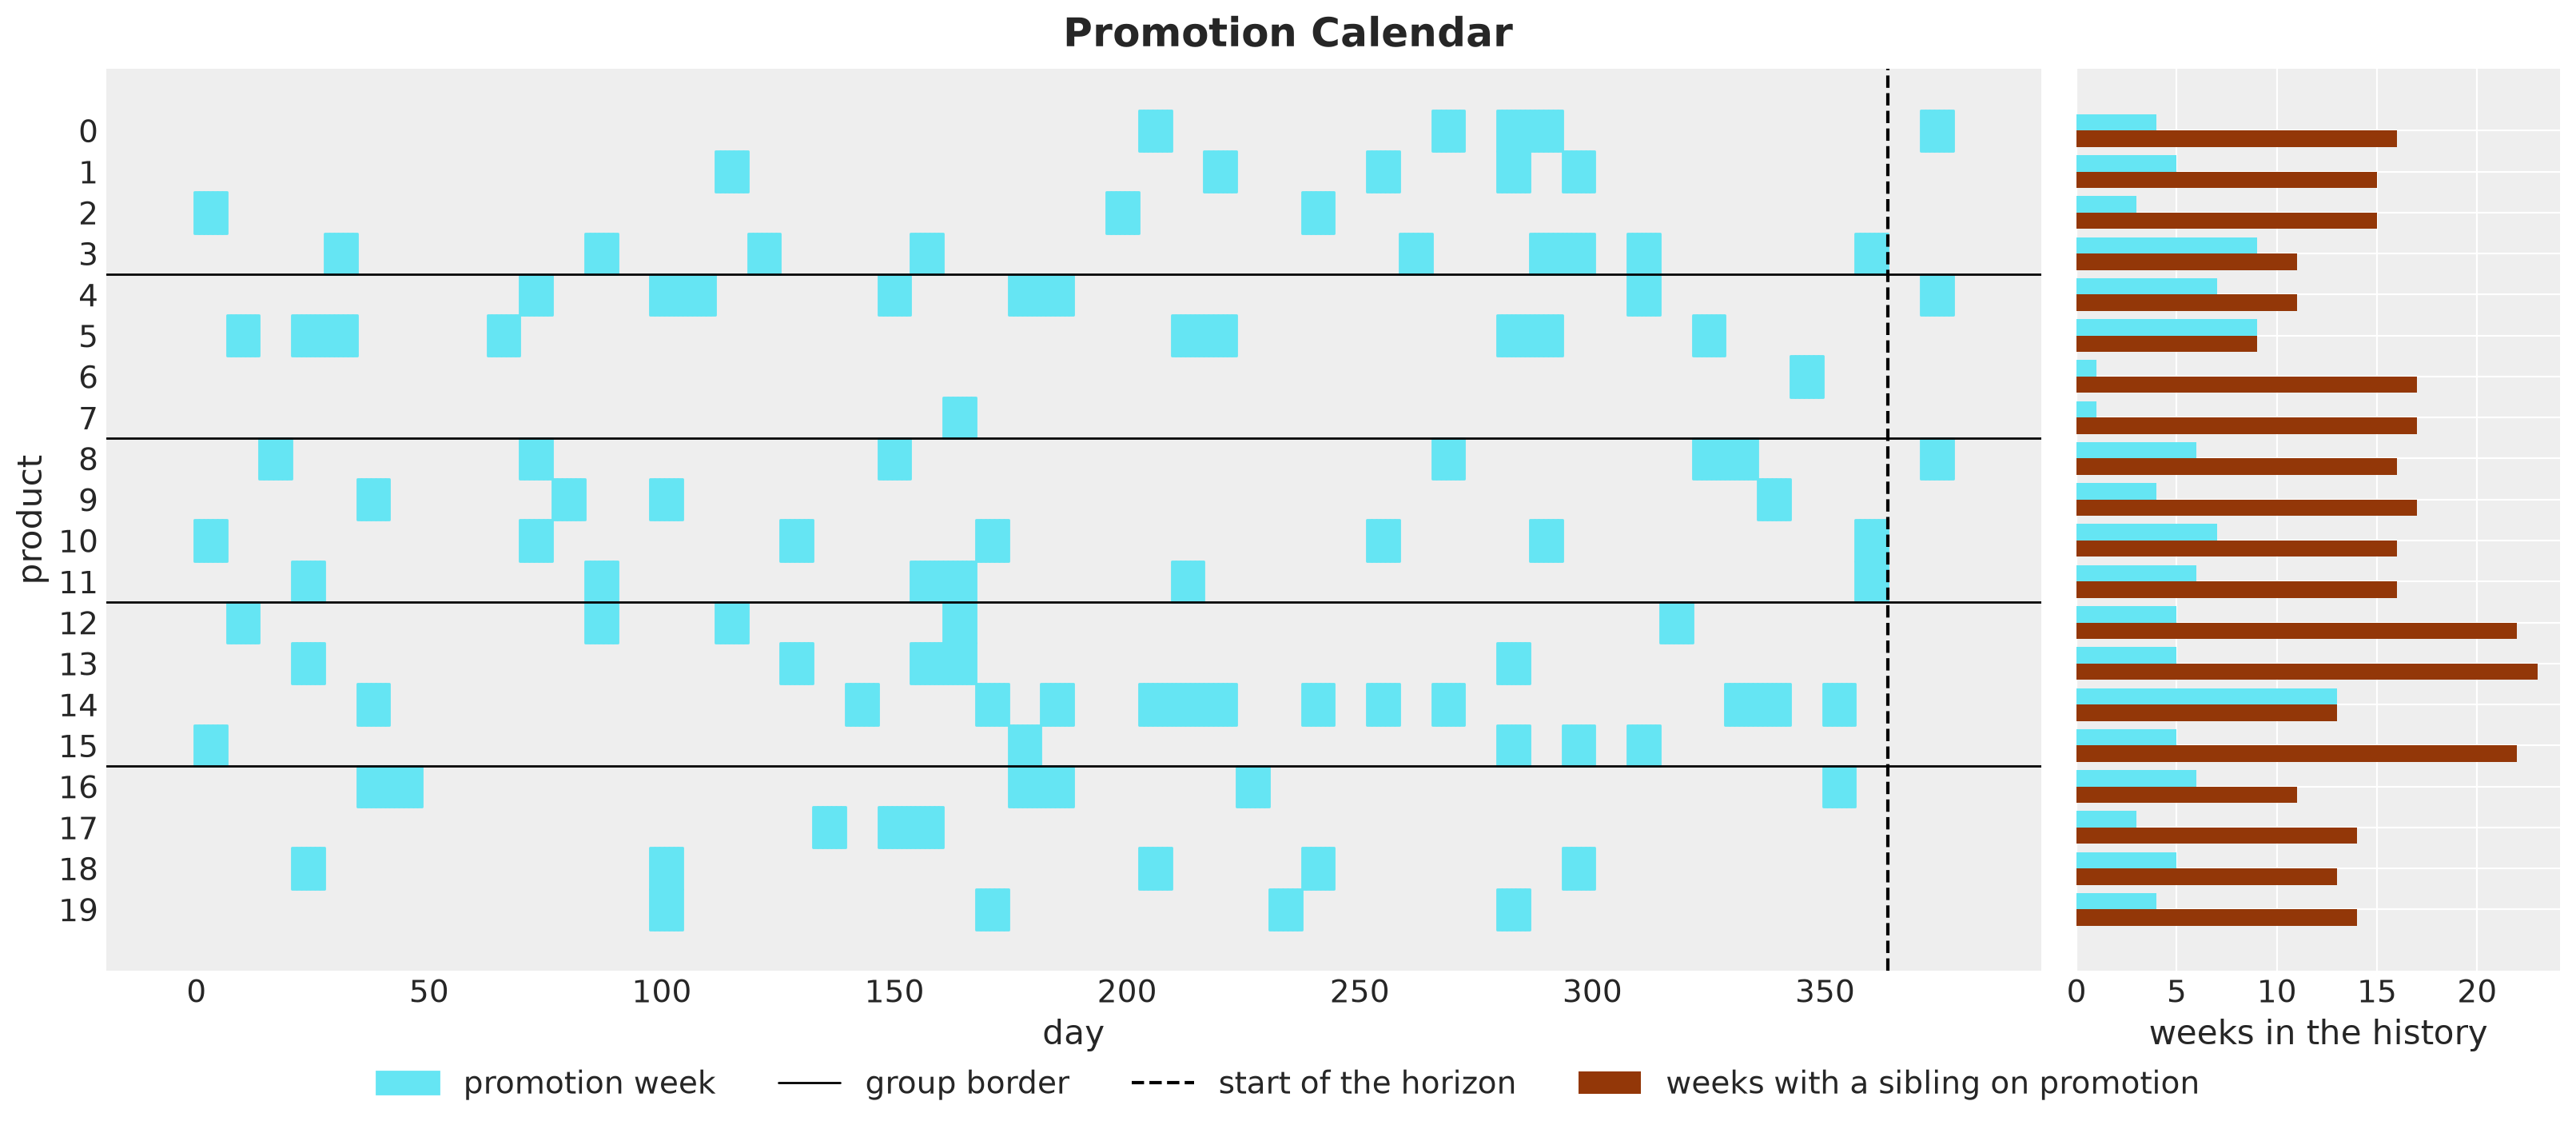

In [7]:
same_group = panel.product_to_group[:, None] == panel.product_to_group[None, :]
is_sibling = same_group & ~np.eye(setup.n_products, dtype=bool)
own_promo_weeks = promo_week_true.sum(axis=0)
sibling_promo_weeks = ((promo_week_true @ is_sibling) > 0).sum(axis=0)

fig, axes = plt.subplots(
    ncols=2, figsize=(16, 7), sharey=True, width_ratios=[4, 1], layout="constrained"
)
ax = axes[0]
for product in range(setup.n_products):
    ax.broken_barh(
        [(day - 0.5, 1.0) for day in np.flatnonzero(promo_full[:, product])],
        (product - 0.5, 1.0),
        color="C5",
        label="promotion week" if product == 0 else None,
    )
for group in range(1, setup.n_groups):
    ax.axhline(
        group * setup.n_per_group - 0.5,
        color="black",
        linewidth=1,
        label="group border" if group == 1 else None,
    )
ax.axvline(
    setup.t_obs - 0.5, color="black", linestyle="--", label="start of the horizon"
)
ax.grid(visible=False)
ax.invert_yaxis()
ax.set(xlabel="day", ylabel="product", yticks=range(setup.n_products))
ax = axes[1]
product_ids = np.arange(setup.n_products)
ax.barh(product_ids - 0.2, own_promo_weeks, height=0.4, color="C5")
ax.barh(
    product_ids + 0.2,
    sibling_promo_weeks,
    height=0.4,
    color="C4",
    label="weeks with a sibling on promotion",
)
ax.set(xlabel="weeks in the history")
fig.legend(loc="outside lower center", ncol=5)
fig.suptitle("Promotion Calendar", fontsize=18, fontweight="bold");

The products have between $1$ and $13$ own promotion weeks in the history. Products $6$ and $7$ have a single one, so the data say little about the response of their siblings to their price. Every product sees a sibling on promotion in $9$ to $23$ of the $52$ weeks, and those weeks are where the data say how much a product loses to its siblings.

Three details of the last weeks of the history matter later.

- **Group $1$.** Product $3$ is on promotion in the last week, which is a sibling promotion week for products $0$, $1$ and $2$.
- **Group $3$.** Products $10$ and $11$ are on promotion in the same week. This group has no cannibalization.
- **Group $4$.** Product $14$ is on promotion in two of the last four weeks, which are sibling promotion weeks for the rest of the group.

### Demand Model

Let $\mu_{t,i}$ be the **expected demand** of series $i = (s, j)$ on day $t$. Let $\ell_{t,i}$ be its **latent level**, a random walk with **initial level** $\ell_{0,i}$ and **daily increments** $\delta_{t,i}$ whose scale $\sigma_i$ we call the **drift scale**.

Let $f_t$ be the **vector of Fourier features** of the weekly cycle and $\beta_j$ the **Fourier coefficients** of product $j$, shared by its stores. Let $x_{t,k} = \log r_{t,k} \leq 0$ be the **log relative price** of product $k$ on day $t$, where $r_{t,k}$ is the price relative to the list price. The log of the expected demand is

$$
\log \mu_{t,i} = \ell_{t,i} + f_t^\top \beta_j + \sum_{k \in g(j)} \gamma_{kj} \, x_{t,k},
\qquad
\ell_{t,i} = \ell_{0,i} + \sum_{u \leq t} \delta_{u,i},
\qquad
\delta_{u,i} \sim \text{Normal}(0, \sigma_i).
$$

The sum runs over the products $k$ of the group of $j$, including $j$ itself. The coefficient $\gamma_{kj}$ is the response of the demand of product $j$ to the price of product $k$, and the matrix $\Gamma = (\gamma_{kj})$ is the **elasticity matrix** of the group.

Its diagonal entry $\gamma_{jj}$ is the **own elasticity** of product $j$, the response of its demand to its own price. We expect it to be negative. An off-diagonal entry $\gamma_{kj}$ with $k \neq j$ is a **cross elasticity**.

A promotion of a sibling $k$ makes $x_{t,k}$ negative, so a positive $\gamma_{kj}$ lowers the demand of $j$. In other words, positive cross elasticities are cannibalization. Taking exponentials, a $30\%$ cut on product $k$ multiplies the demand of a sibling $j$ by $0.7^{\gamma_{kj}}$, so a cross elasticity of $0.6$ is a loss of $1 - 0.7^{0.6} \approx 19\%$.

The likelihood is a negative binomial with a **concentration** $\phi_j$ per product:

$$
D_{t,i} \sim \text{NegativeBinomial}(\mu_{t,i}, \phi_j).
$$

We write each term of the log mean as a function that samples its own sites and returns its contribution with shape `(duration, n_series)`, the pattern of the NumPyro [Hilbert space Gaussian process example](https://num.pyro.ai/en/stable/examples/hsgp.html). The function `make_demand_model` builds the generator (with the true parameters fixed through `do`) and the two fitted models, so the true parameters are in the support of the cross model.

The `cross` flag adds or removes the cross-price term. The `reparam` flag switches on the non-centered parameterization of the level increments and of the cross elasticities, which only the guide needs.

The prices are chain-wide, so the cross-price term of a series depends on its product only. We compute it as the matrix product of the log prices with the elasticity matrix $\Gamma$. The own elasticities form the diagonal of $\Gamma$, and the `cross_elasticity` site over the within-group pairs fills the off-diagonal cells, shrunk toward zero by the common scale `cross_scale`.

In [8]:
class Priors(NamedTuple):
    """Prior hyperparameters of the demand model."""

    intercept_mu: float
    intercept_sigma: float
    drift_mu: float
    drift_sigma: float
    concentration_alpha: float
    concentration_beta: float
    cross_scale_sigma: float
    seasonal_sigma: float = 0.3
    elasticity_mu: float = -1.0
    elasticity_sigma: float = 1.0


def local_level(
    h: Horizon, series_plate: numpyro.plate, priors: Priors, *, reparam: bool
) -> Float[Array, "duration n_series"]:
    """Random-walk level per series: the initial level plus the summed increments."""
    with series_plate:
        intercept = numpyro.sample(
            "intercept", dist.Normal(priors.intercept_mu, priors.intercept_sigma)
        )
        drift_scale = numpyro.sample(
            "drift_scale", dist.LogNormal(priors.drift_mu, priors.drift_sigma)
        )
        drift = innovations(
            h,
            "drift",
            dist.Normal(0.0, drift_scale),
            reparam=LocScaleReparam(0) if reparam else None,
        )
    return intercept + jnp.cumsum(drift, axis=-2)


def weekly_seasonality(
    fourier: Float[Array, "duration n_fourier"],
    product_plate: numpyro.plate,
    fourier_plate: numpyro.plate,
    panel: Panel,
    priors: Priors,
) -> Float[Array, "duration n_series"]:
    """Weekly Fourier seasonality with one coefficient vector per product."""
    with fourier_plate, product_plate:
        beta = numpyro.sample("beta", dist.Normal(0.0, priors.seasonal_sigma))
    return (fourier @ beta)[:, panel.series_to_product]


def price_effects(
    log_price: Float[Array, "duration n_products"],
    product_plate: numpyro.plate,
    pair_plate: numpyro.plate,
    panel: Panel,
    priors: Priors,
    *,
    cross: bool,
    reparam: bool,
) -> Float[Array, "duration n_series"]:
    """Own price elasticities, plus the cross elasticities of the within-group pairs."""
    with product_plate:
        elasticity = numpyro.sample(
            "elasticity", dist.Normal(priors.elasticity_mu, priors.elasticity_sigma)
        )
    matrix = jnp.diag(elasticity)
    if cross:
        cross_scale = numpyro.sample(
            "cross_scale", dist.HalfNormal(priors.cross_scale_sigma)
        )
        # non-centered: the guide sees standardized cross elasticities
        reparam_config = {"cross_elasticity": LocScaleReparam(0)} if reparam else {}
        with pair_plate, handlers.reparam(config=reparam_config):
            cross_elasticity = numpyro.sample(
                "cross_elasticity", dist.Normal(0.0, cross_scale)
            )
        matrix = matrix.at[panel.pair_rows, panel.pair_cols].set(cross_elasticity)
    # effect[t, i] = sum_k matrix[k, j(i)] * log_price[t, k]
    return (log_price @ matrix)[:, panel.series_to_product]


def dispersion(
    product_plate: numpyro.plate, panel: Panel, priors: Priors
) -> Float[Array, " n_series"]:
    """Negative binomial concentration per product, gathered to the series axis."""
    with product_plate:
        concentration = numpyro.sample(
            "concentration",
            dist.Gamma(priors.concentration_alpha, priors.concentration_beta),
        )
    return concentration[panel.series_to_product]


def make_demand_model(
    panel: Panel, setup: Setup, priors: Priors, *, cross: bool, reparam: bool = True
) -> ForecastModel:
    """Build the demand model as a plain `(covariates, data=None)` function."""
    n_products, n_series, n_fourier = setup.n_products, setup.n_series, setup.n_fourier
    n_pairs = panel.pair_rows.size

    def demand_model(
        covariates: Float[Array, "duration inputs"],
        data: Int[Array, "t_obs n_series"] | None = None,
    ) -> None:
        h = Horizon.from_data(covariates, data)
        fourier, log_price = covariates[:, :n_fourier], covariates[:, n_fourier:]
        series_plate = numpyro.plate("series", n_series, dim=-1)
        product_plate = numpyro.plate("product", n_products, dim=-1)
        fourier_plate = numpyro.plate("fourier", n_fourier, dim=-2)
        pair_plate = numpyro.plate("pair", n_pairs, dim=-1)

        log_rate = local_level(h, series_plate, priors, reparam=reparam)
        log_rate = log_rate + weekly_seasonality(
            fourier, product_plate, fourier_plate, panel, priors
        )
        log_rate = log_rate + price_effects(
            log_price,
            product_plate,
            pair_plate,
            panel,
            priors,
            cross=cross,
            reparam=reparam,
        )
        concentration = dispersion(product_plate, panel, priors)
        predict(
            h, lambda eta: dist.NegativeBinomial2(jnp.exp(eta), concentration), log_rate
        )

    return demand_model

### Prior Elicitation

We elicit the priors here, before the forecasting model, because the generator of the next section needs a `Priors` tuple, and because the two forecasting models share them.

The model has six families of global parameters. For four of them we state what we believe on the scale of the data and use [PreliZ](https://preliz.readthedocs.io/) to turn the statement into a distribution.

The function `pz.maxent` returns the member of a family that puts a given mass between two bounds (the one with maximum entropy, so it adds nothing beyond our constraints). Here is the reasoning for each of them.

- **`intercept`**: $\exp(\ell_{0,i})$ is the demand per day of series $i$ at the start of the history at the list price, with the weekly pattern averaged out on the log scale (the Fourier terms sum to zero over a week). We believe it lies between $10$ and $300$ units for every series of the chain, a wide range for products that sell tens of units per day. So we ask for a Normal on $\ell_{0,i}$ with $94\%$ of its mass between $\log 10$ and $\log 300$.

- **`drift_scale`**: the level of a series is a random walk, so after $T$ days the standard deviation of the log level is $\sigma_i \sqrt{T}$, and $\exp(\sigma_i \sqrt{T})$ is the typical factor by which the level has moved. Over the $364$ days of history we believe that factor lies between $1.04$ and $2$, that is, from a $4\%$ move to a doubling. So we ask for a LogNormal on $\sigma_i$ with $94\%$ of its mass between $\log(1.04) / \sqrt{T}$ and $\log(2) / \sqrt{T}$.

- **`concentration`**: the negative binomial adds $\mu_{t,i}^2 / \phi_j$ to the Poisson variance, so the extra day-to-day noise is a fraction $1 / \sqrt{\phi_j}$ of the level. We believe that fraction lies between $0.1$ and $0.5$, which is $\phi_j$ between $4$ and $100$. So we ask for a Gamma with $94\%$ of its mass in that range.

- **`cross_scale`**: the cross elasticities share the prior $\gamma_{kj} \sim \text{Normal}(0, \sigma_\gamma)$ for $k \neq j$, centered at zero and shrunk by the common scale $\sigma_\gamma$, so the data can also say that a group has no cannibalization. Consider a sibling whose cross elasticity is one prior standard deviation, $\gamma_{kj} = \sigma_\gamma$. Under a $30\%$ cut on product $k$, this sibling loses a share $1 - 0.7^{\sigma_\gamma}$ of its demand. We believe that this typical loss lies below $15\%$, which is a cross elasticity of $\log(0.85) / \log(0.7) \approx 0.46$. So we ask for a HalfNormal on $\sigma_\gamma$ with $94\%$ of its mass between $0$ and $0.46$.

The other two priors we state directly.

- **`beta`**: each Fourier coefficient gets a $\text{Normal}(0, 0.3)$, so two standard deviations multiply the demand by $e^{\pm 0.6}$, between $0.55$ and $1.8$.

- **`elasticity`**: the own elasticity of every product gets a $\text{Normal}(-1, 1)$. A higher price should lower the demand, so we center the prior on a negative value, and the standard deviation of $1$ leaves a positive value possible if the data ask for it.

We run the four elicitations and store the results in the `Priors` tuple that the model functions read.

In [9]:
intercept_bounds = (float(np.log(10)), float(np.log(300)))
drift_bounds = (
    float(np.log(1.04) / np.sqrt(setup.t_obs)),
    float(np.log(2) / np.sqrt(setup.t_obs)),
)
concentration_bounds = (4.0, 100.0)
cross_bounds = (0.0, float(np.log(0.85) / np.log(1 - setup.discount)))


def elicit(
    family: pz.distributions.distributions.Continuous,
    bounds: tuple[float, float],
    mass: float = 0.94,
) -> pz.distributions.distributions.Continuous:
    """Maximum entropy member of `family` with `mass` between the bounds."""
    return pz.maxent(family, *bounds, mass=mass, plot=False)


intercept_prior = elicit(pz.Normal(), intercept_bounds)
drift_prior = elicit(pz.LogNormal(), drift_bounds)
concentration_prior = elicit(pz.Gamma(), concentration_bounds)
cross_prior = elicit(pz.HalfNormal(), cross_bounds)

priors = Priors(
    intercept_mu=float(intercept_prior.mu),
    intercept_sigma=float(intercept_prior.sigma),
    drift_mu=float(drift_prior.mu),
    drift_sigma=float(drift_prior.sigma),
    concentration_alpha=float(concentration_prior.alpha),
    concentration_beta=float(concentration_prior.beta),
    cross_scale_sigma=float(cross_prior.sigma),
)
pl.DataFrame({"hyperparameter": priors._fields, "value": list(priors)})

hyperparameter,value
str,f64
"""intercept_mu""",4.003
"""intercept_sigma""",0.904
"""drift_mu""",-4.256
"""drift_sigma""",0.603
"""concentration_alpha""",2.770
"""concentration_beta""",0.058
"""cross_scale_sigma""",0.242
"""seasonal_sigma""",0.300
"""elasticity_mu""",-1.000


Next, we plot the four elicited densities in two rows. The top row is the parameter scale, with the two bounds we asked for. The bottom row is the data scale, the density of the quantity we reasoned about, with the bounds mapped through the same transform.

For the bottom row we use the change of variables formula. If $\psi = u(\eta)$ is a monotone transform of the parameter $\eta$ with density $q$, the density of $\psi$ is $q(u^{-1}(\psi)) \, |du^{-1} / d\psi|$.

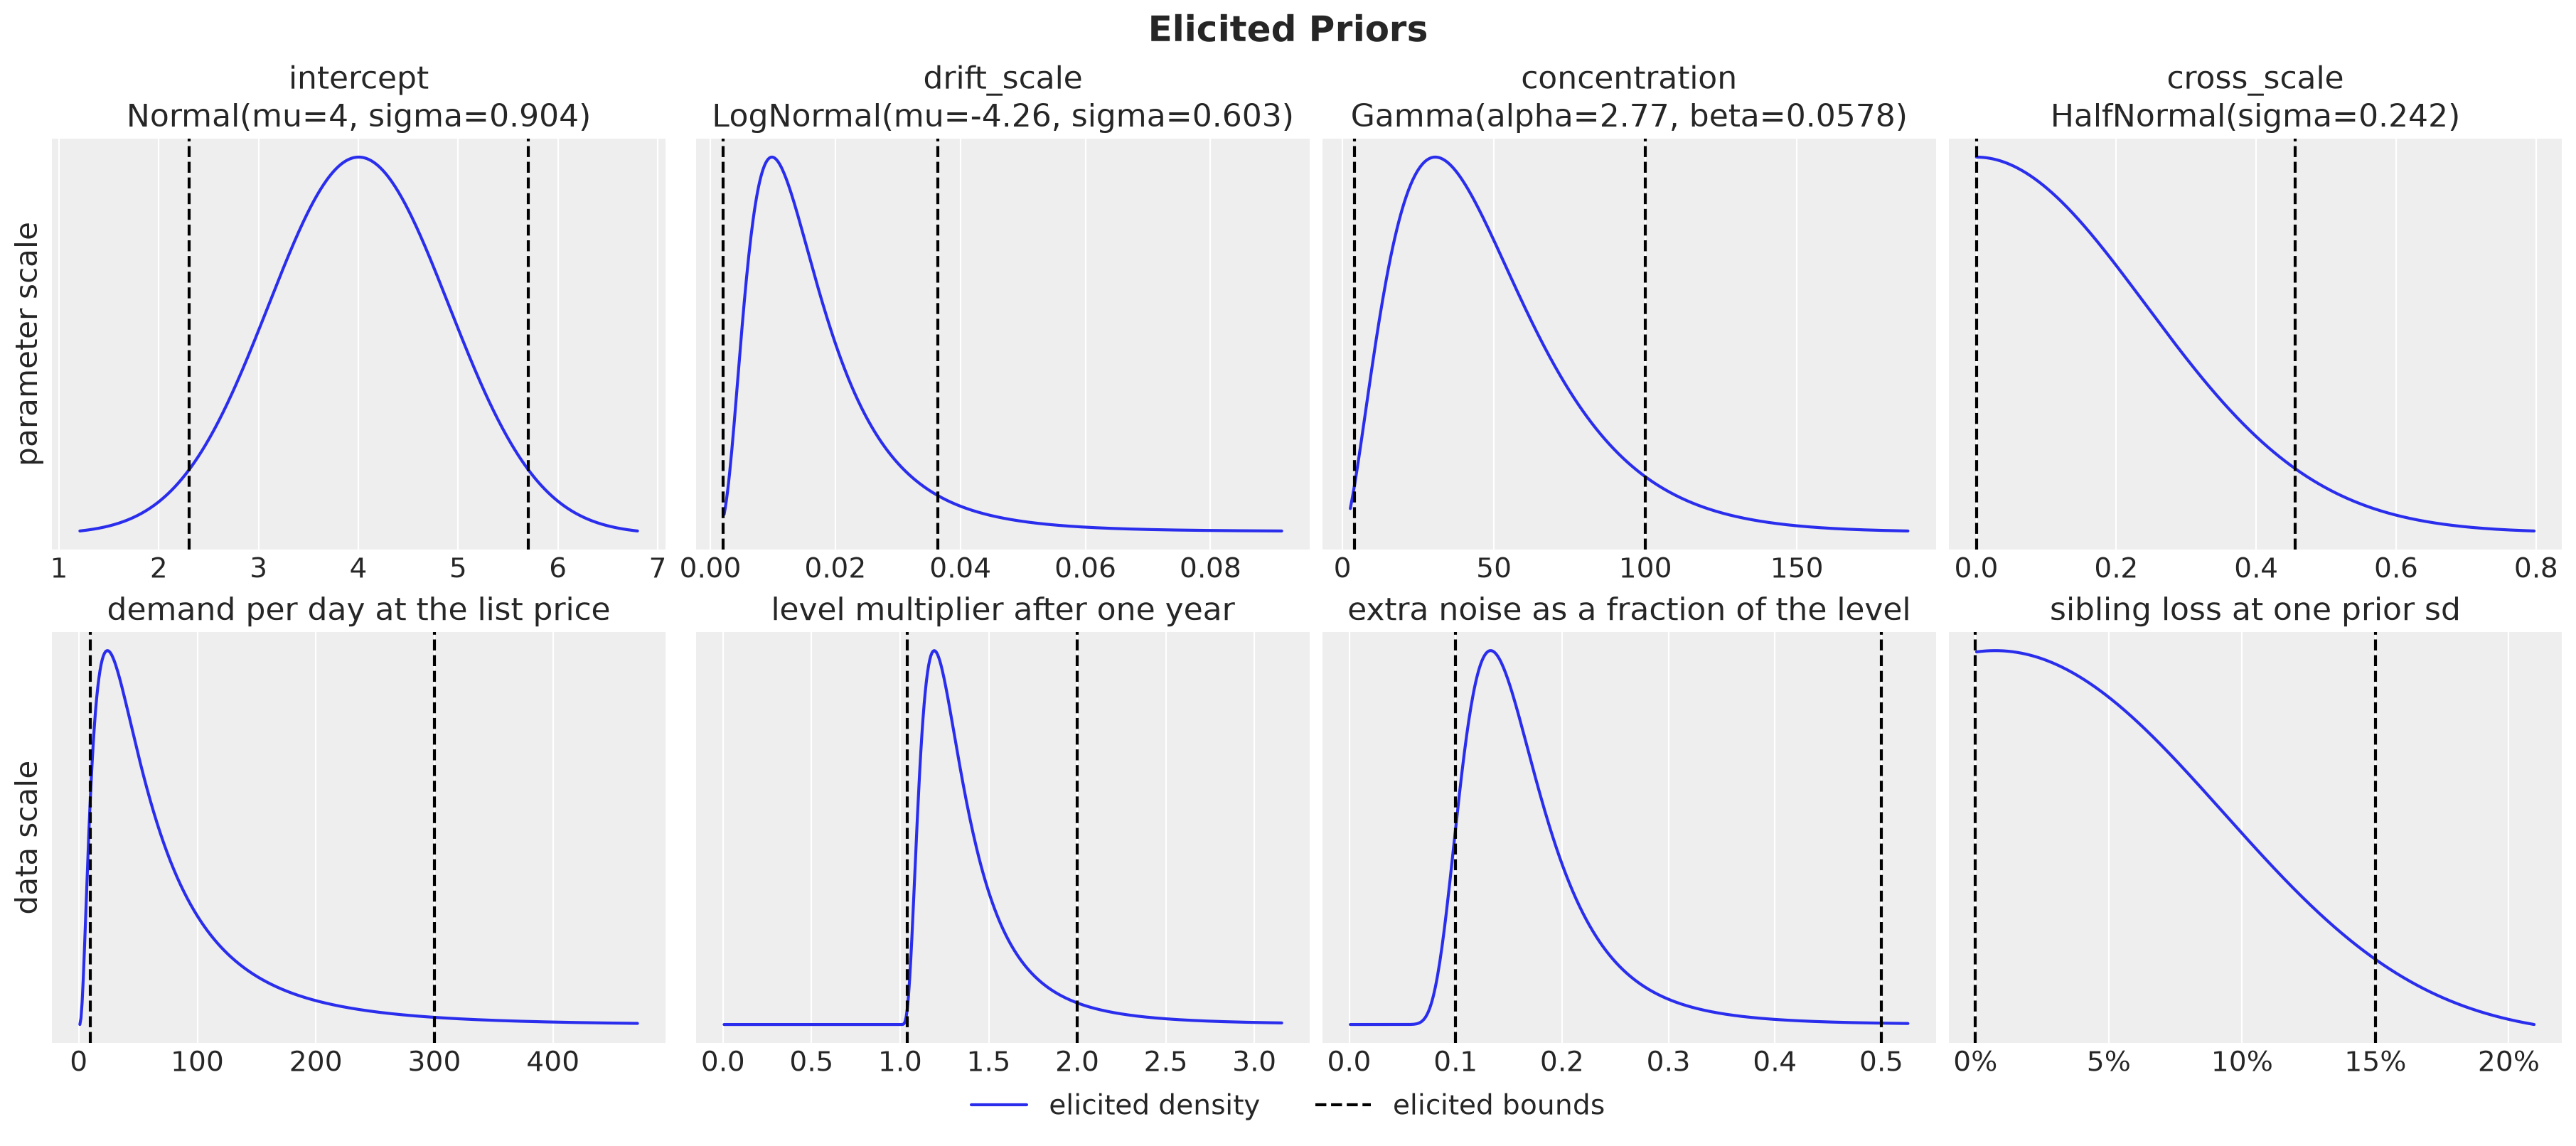

In [10]:
priors_elicited = {
    "intercept": (intercept_prior, intercept_bounds),
    "drift_scale": (drift_prior, drift_bounds),
    "concentration": (concentration_prior, concentration_bounds),
    "cross_scale": (cross_prior, cross_bounds),
}
# the quantity on the data scale that each prior is about, with the inverse transform
log_discount = np.log(1 - setup.discount)
data_scale = {
    "intercept": ("demand per day at the list price", jnp.exp, jnp.log),
    "drift_scale": (
        "level multiplier after one year",
        lambda x: jnp.exp(x * jnp.sqrt(setup.t_obs)),
        lambda y: jnp.log(y) / jnp.sqrt(setup.t_obs),
    ),
    "concentration": (
        "extra noise as a fraction of the level",
        lambda x: 1 / jnp.sqrt(x),
        lambda y: 1 / y**2,
    ),
    "cross_scale": (
        "sibling loss at one prior sd",
        lambda x: 1 - jnp.exp(x * log_discount),
        lambda y: jnp.log(1 - y) / log_discount,
    ),
}


def density_on_data_scale(
    prior: pz.distributions.distributions.Continuous,
    inverse: Callable[[Float[Array, " grid"]], Float[Array, " grid"]],
    grid: Float[Array, " grid"],
) -> Float[Array, " grid"]:
    """Density of a monotone transform of the prior, by change of variables."""
    jacobian = jnp.abs(jax.vmap(jax.grad(inverse))(grid))
    return prior.pdf(inverse(grid)) * jacobian


fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 8), layout="constrained")

for j, (name, (prior, bounds)) in enumerate(priors_elicited.items()):
    label, transform, inverse = data_scale[name]
    # parameter scale: the elicited density and the bounds
    ax = axes[0, j]
    x = np.linspace(*prior.ppf([0.001, 0.999]), 500)
    ax.plot(x, prior.pdf(x), color="C0", label="elicited density")
    ax.axvline(bounds[0], color="black", linestyle="--", label="elicited bounds")
    ax.axvline(bounds[1], color="black", linestyle="--")
    ax.set(title=f"{name}\n{prior}", yticks=[])
    # data scale: the same density after the transform, from near zero to the
    # larger of the 99th percentile and the upper bound
    ax = axes[1, j]
    bounds_data = transform(jnp.asarray(bounds))
    upper = 1.05 * max(
        float(transform(prior.ppf([0.01, 0.99])).max()), float(bounds_data.max())
    )
    grid = jnp.linspace(upper / 500, upper, 500)
    ax.plot(grid, density_on_data_scale(prior, inverse, grid), color="C0")
    for bound in bounds_data:
        ax.axvline(bound, color="black", linestyle="--")
    ax.set(title=label, yticks=[])

axes[1, 3].xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
axes[0, 0].set(ylabel="parameter scale")
axes[1, 0].set(ylabel="data scale")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
fig.suptitle("Elicited Priors", fontsize=18, fontweight="bold");

The elicited priors are a $\text{Normal}(4.0, 0.9)$ for the `intercept`, a $\text{LogNormal}(-4.3, 0.6)$ for the drift scale, a $\text{Gamma}$ with shape $2.8$ and rate $0.06$ for the concentration, and a $\text{HalfNormal}(0.24)$ for the scale of the cross elasticities.

The bottom row shows what these priors say on the data scale.

- **Demand per day.** The mass spreads between a few units and a few hundred, most of it below $100$ units.
- **Level multiplier.** After one year the level lies between no move and a doubling, with a tail beyond.
- **Noise fraction.** Most of the mass lies between $0.1$ and $0.3$.
- **Sibling loss.** Most of the mass lies below $10\%$, so the prior favors small cross effects and leaves room for large ones.

Note that `pz.maxent` fixes the total mass between the bounds and not the two tails. The Gamma puts almost all of its remaining $6\%$ above $100$, which is the tail below $0.1$ in the noise panel. The HalfNormal starts at zero, so all of its remaining $6\%$ lies above a loss of $15\%$.

### True Parameters and Data

We set the cross elasticities by hand and draw the other values with the numpy generator.

- **Initial levels.** The product baselines range from $20$ to $150$ units per day and the store multipliers from $0.6$ to $1.5$. The initial level of a series is the log of their product, between $\log 12$ and $\log 225$.
- **Own elasticities, concentrations and drift scales.** The own elasticities lie between $-2$ and $-1$, the concentrations between $20$ and $40$, and the drift scales between $0.005$ and $0.02$.
- **Cross elasticities.** They are constant within a group, at the values of the *Panel and Calendar* section. Their root mean square over the $60$ pairs is $0.33$.

All of these values lie inside the elicited priors.

In [11]:
base_product = np.exp(rng.uniform(np.log(20), np.log(150), size=setup.n_products))
store_multiplier = rng.uniform(0.6, 1.5, size=setup.n_stores)
group_cross = np.array(setup.group_cross)

true_params: dict[str, Array] = {
    "intercept": jnp.asarray(
        np.log(
            base_product[panel.series_to_product]
            * store_multiplier[panel.series_to_store]
        )
    ),
    "drift_scale": jnp.asarray(rng.uniform(0.005, 0.02, size=setup.n_series)),
    "beta": jnp.asarray(
        rng.normal(0.0, 0.05, size=(setup.n_fourier, setup.n_products))
    ),
    "elasticity": jnp.asarray(rng.uniform(-2.0, -1.0, size=setup.n_products)),
    # fixed for completeness: the pairs below are fixed too, so it has no effect
    "cross_scale": jnp.asarray(0.3),
    "cross_elasticity": jnp.asarray(
        group_cross[panel.product_to_group[panel.pair_rows]]
    ),
    "concentration": jnp.asarray(rng.uniform(20.0, 40.0, size=setup.n_products)),
}

products = products.with_columns(
    baseline=base_product,
    elasticity=pl.Series(true_params["elasticity"].tolist()),
    concentration=pl.Series(true_params["concentration"].tolist()),
    cross_elasticity=group_cross[panel.product_to_group],
)
products

product,group,role,baseline,elasticity,concentration,cross_elasticity
i64,i64,str,f64,f64,f64,f64
0,1,"""promoted""",92.130,-1.852,29.086,0.600
1,1,"""sibling""",40.857,-1.064,36.508,0.600
2,1,"""sibling""",141.400,-1.562,25.907,0.600
3,1,"""sibling""",120.939,-1.617,29.171,0.600
4,2,"""promoted""",95.976,-1.270,28.846,0.300
5,2,"""sibling""",29.604,-1.447,26.039,0.300
6,2,"""sibling""",51.220,-1.064,38.369,0.300
7,2,"""sibling""",21.845,-1.220,35.626,0.300
8,3,"""promoted""",27.292,-1.521,22.212,0.000


We draw the demand of the whole duration once, from the model with the true parameters fixed. We keep the realized level increments of the history, because the distribution of the true future conditions on them. The observed data are the first $364$ days and the **realized future** the last $15$.

In [12]:
generator = make_demand_model(panel, setup, priors, cross=True, reparam=False)
rng_key, key_data = random.split(rng_key)
draw = Predictive(
    do(generator, data=true_params), num_samples=1, return_sites=["obs", "drift"]
)(key_data, covariates)
demand_full = draw["obs"][0]  # (duration, n_series)
drift_true = draw["drift"][0][: setup.t_obs]  # (t_obs, n_series)
data = demand_full[: setup.t_obs].astype(jnp.int32)
demand_future_true = demand_full[setup.t_obs :].astype(jnp.float32)
assert data.shape == (setup.t_obs, setup.n_series)
assert demand_future_true.shape == (setup.horizon, setup.n_series)

The next figure shows the four products of group $1$ in store $1$ over the last eight weeks of the history and the horizon. The strips at the bottom of each panel mark the promotion days of the product and of its siblings.

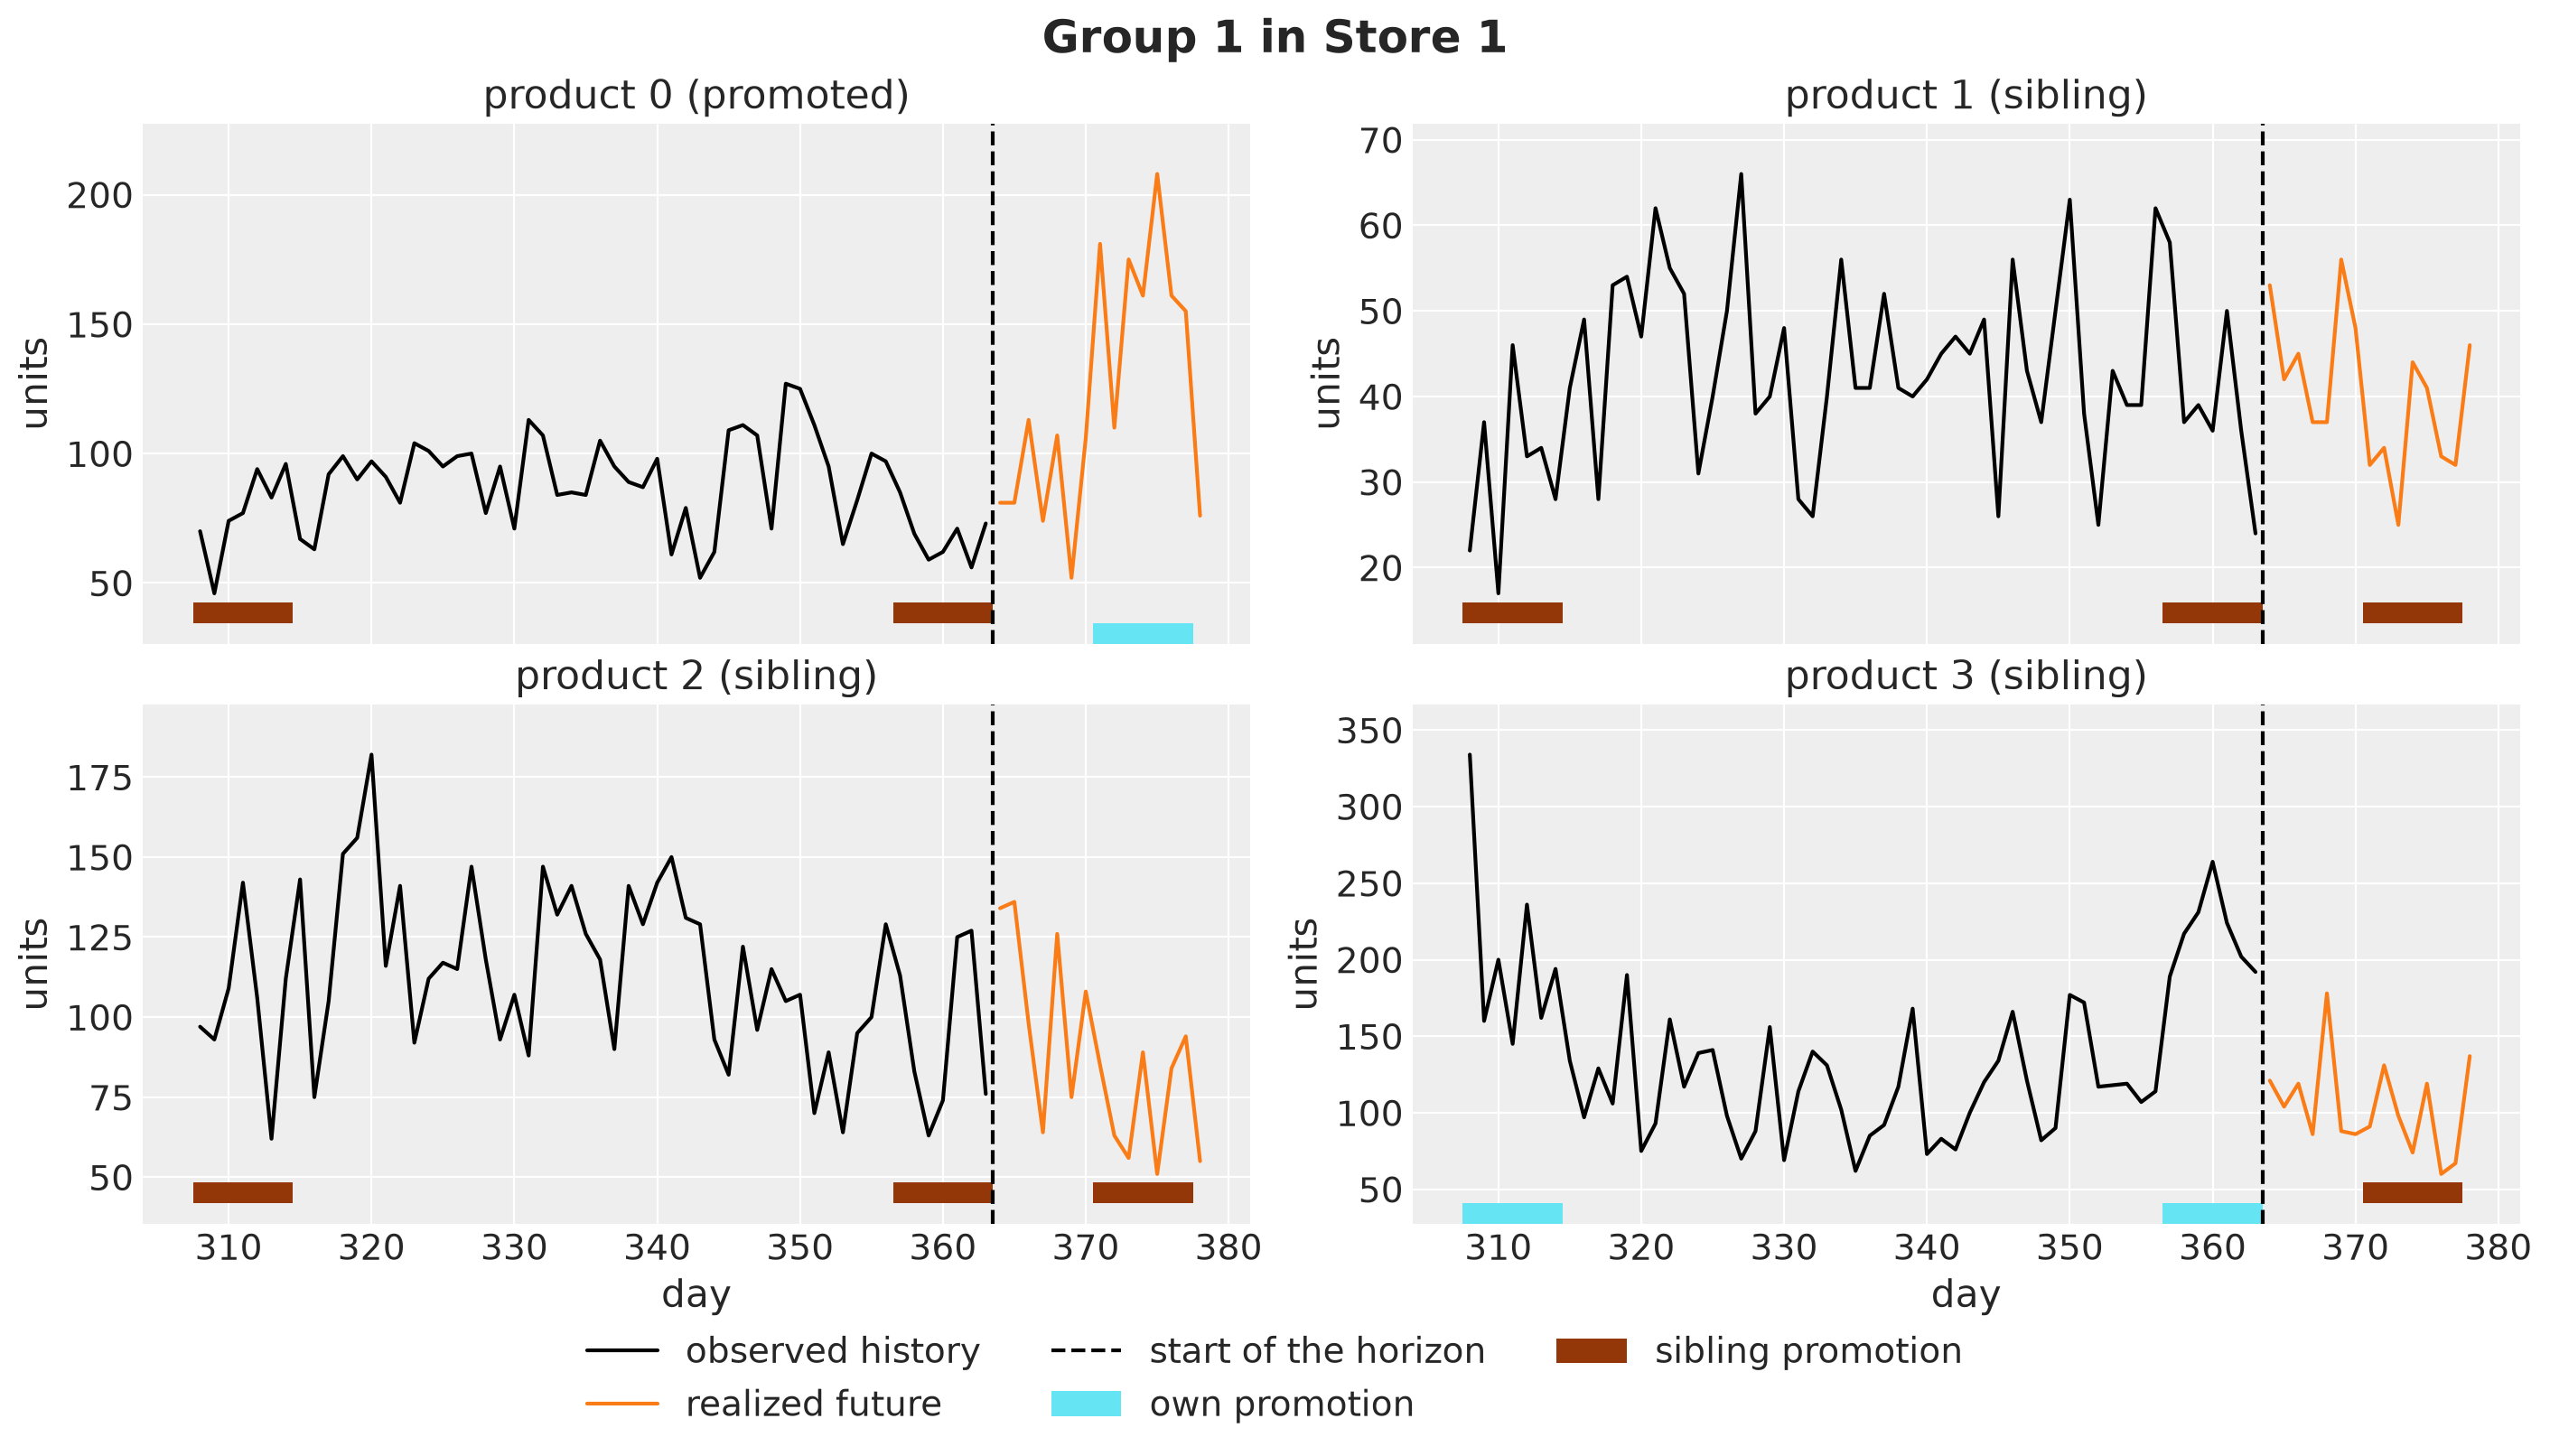

In [13]:
def mark_promotions(ax: plt.Axes, product: int, start: int) -> None:
    """Mark the own and the sibling promotion days of a product from `start` on."""
    own = promo_full[start:, product] > 0
    sibling = (promo_full[start:] @ is_sibling[:, product]) > 0
    # two strips along the bottom of the axes, in axes coordinates, clear of the data
    for mask, color, bottom, label in [
        (own, "C5", 0.0, "own promotion"),
        (sibling, "C4", 0.04, "sibling promotion"),
    ]:
        ax.broken_barh(
            [(start + day - 0.5, 1.0) for day in np.flatnonzero(mask)],
            (bottom, 0.04),
            transform=ax.get_xaxis_transform(),
            color=color,
            linewidth=0,
            label=label,
        )
    ax.margins(y=0.12)


def plot_demand(ax: plt.Axes, series: int, start: int) -> None:
    """History from `start`, realized future and promotion days of one series."""
    ax.plot(
        days[start : setup.t_obs],
        demand_full[start : setup.t_obs, series],
        color="black",
        label="observed history",
    )
    ax.plot(
        days_future, demand_future_true[:, series], color="C1", label="realized future"
    )
    ax.axvline(
        setup.t_obs - 0.5, color="black", linestyle="--", label="start of the horizon"
    )
    mark_promotions(ax, int(panel.series_to_product[series]), start)


fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(14, 8), sharex=True, layout="constrained"
)
# the four products of group 1 in store 1 are the first four series
for series, ax in enumerate(axes.flat):
    plot_demand(ax, series, start=setup.t_obs - 56)
    ax.set(title=f"product {series} ({product_role[series]})", ylabel="units")
for ax in axes[-1]:
    ax.set(xlabel="day")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle("Group 1 in Store 1", fontsize=18, fontweight="bold");

The promoted product jumps in the second week of the horizon, to about twice its level, and the three siblings dip in the same week, which is the cannibalization.

The history shows the same pattern. Product $3$ was on promotion in the last week of the history, so that week is a sibling promotion week for products $0$, $1$ and $2$, and their demand was lower in that week. Keep this in mind, because the forecast of these three products starts right after a dip.

### Evaluation Scenarios

In the first post we scored the plans on held-out draws of the posterior that built them, which cannot tell us what happens when the forecast is wrong.

Here we know the true process, so we can do better. We draw $3{,}000$ scenarios from the generator with the true parameters and the realized level increments of the history fixed. Only the future increments and the observation noise are fresh, so these scenarios are draws from the distribution of the true future given the history.

We call them the **evaluation scenarios** and score every plan on them. This tests every plan against the misspecification of its model.

In [14]:
rng_key, key_eval = random.split(rng_key)
true_future_generator = do(generator, data={**true_params, "drift": drift_true})
demand_eval = Predictive(
    true_future_generator,
    num_samples=setup.n_eval_scenarios,
    return_sites=["forecast"],
)(key_eval, covariates, data)["forecast"].astype(jnp.float32)
assert demand_eval.shape == (setup.n_eval_scenarios, setup.horizon, setup.n_series)

## Forecasting Model

We fit two models to the same history. The **cross model** is the demand model of the previous section.

The **independent model** is the same model without the cross-price term, so it has no link between the products of a group.

The following graph shows the two paths from a promotion to the demand of a group of two products. The price of product A moves its own demand through the own elasticity and the demand of product B through the cross elasticity. The red arrows are what the independent model drops.

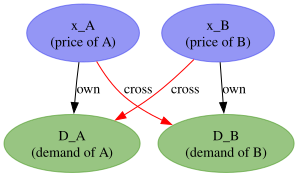

In [15]:
dag = gr.Digraph()
dag.node("xA", label="x_A\n(price of A)", color="#2a2eec80", style="filled")
dag.node("xB", label="x_B\n(price of B)", color="#2a2eec80", style="filled")
dag.node("DA", label="D_A\n(demand of A)", color="#328c0680", style="filled")
dag.node("DB", label="D_B\n(demand of B)", color="#328c0680", style="filled")
dag.edge("xA", "DA", label="own")
dag.edge("xB", "DB", label="own")
dag.edge("xA", "DB", label="cross", color="red")
dag.edge("xB", "DA", label="cross", color="red")
dag

Here is an important observation: the independent model is misspecified on the history as well as on the horizon. In the history, the demand of a product with cannibalization dips by $10\%$ to $19\%$ in every week in which a sibling is on promotion.

The independent model has no term for these dips, so it has to explain them with the two things it has, the level of the series and the noise of the likelihood. We check in the *Parameter Recovery* section what this does to its estimates.

Both models take the same covariates and data. Let's build them and render the cross model on the history.

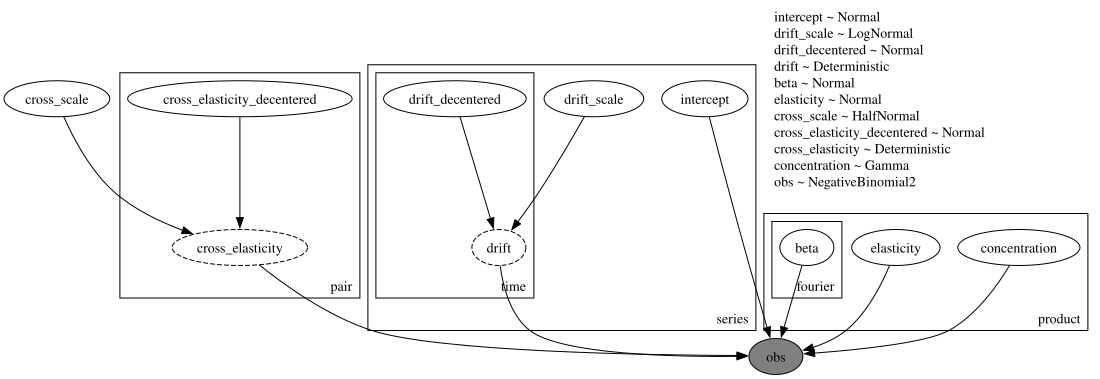

In [16]:
model_independent = make_demand_model(panel, setup, priors, cross=False)
model_cross = make_demand_model(panel, setup, priors, cross=True)

numpyro.render_model(
    model_cross,
    model_args=(covariates_train, data),
    render_distributions=True,
    render_params=False,
)

The `series` plate holds the level, the `product` plate the seasonality, the own elasticity and the concentration, and the `pair` plate the $60$ cross elasticities under their common scale. Inside the `time` plate we see `drift_decentered`, the standardized increments that the `LocScaleReparam` samples.

## Prior Predictive Checks

Before we fit the models, we draw demand paths from the priors of the cross model and compare them with the history. We plot the $50\%$ and $94\%$ equal-tailed intervals (ETI) of $300$ draws for the first product of groups $1$ to $4$ in store $1$.

The axis is logarithmic because the log link gives the prior a long upper tail. Every band of this notebook is an equal-tailed interval, which runs between two percentiles.

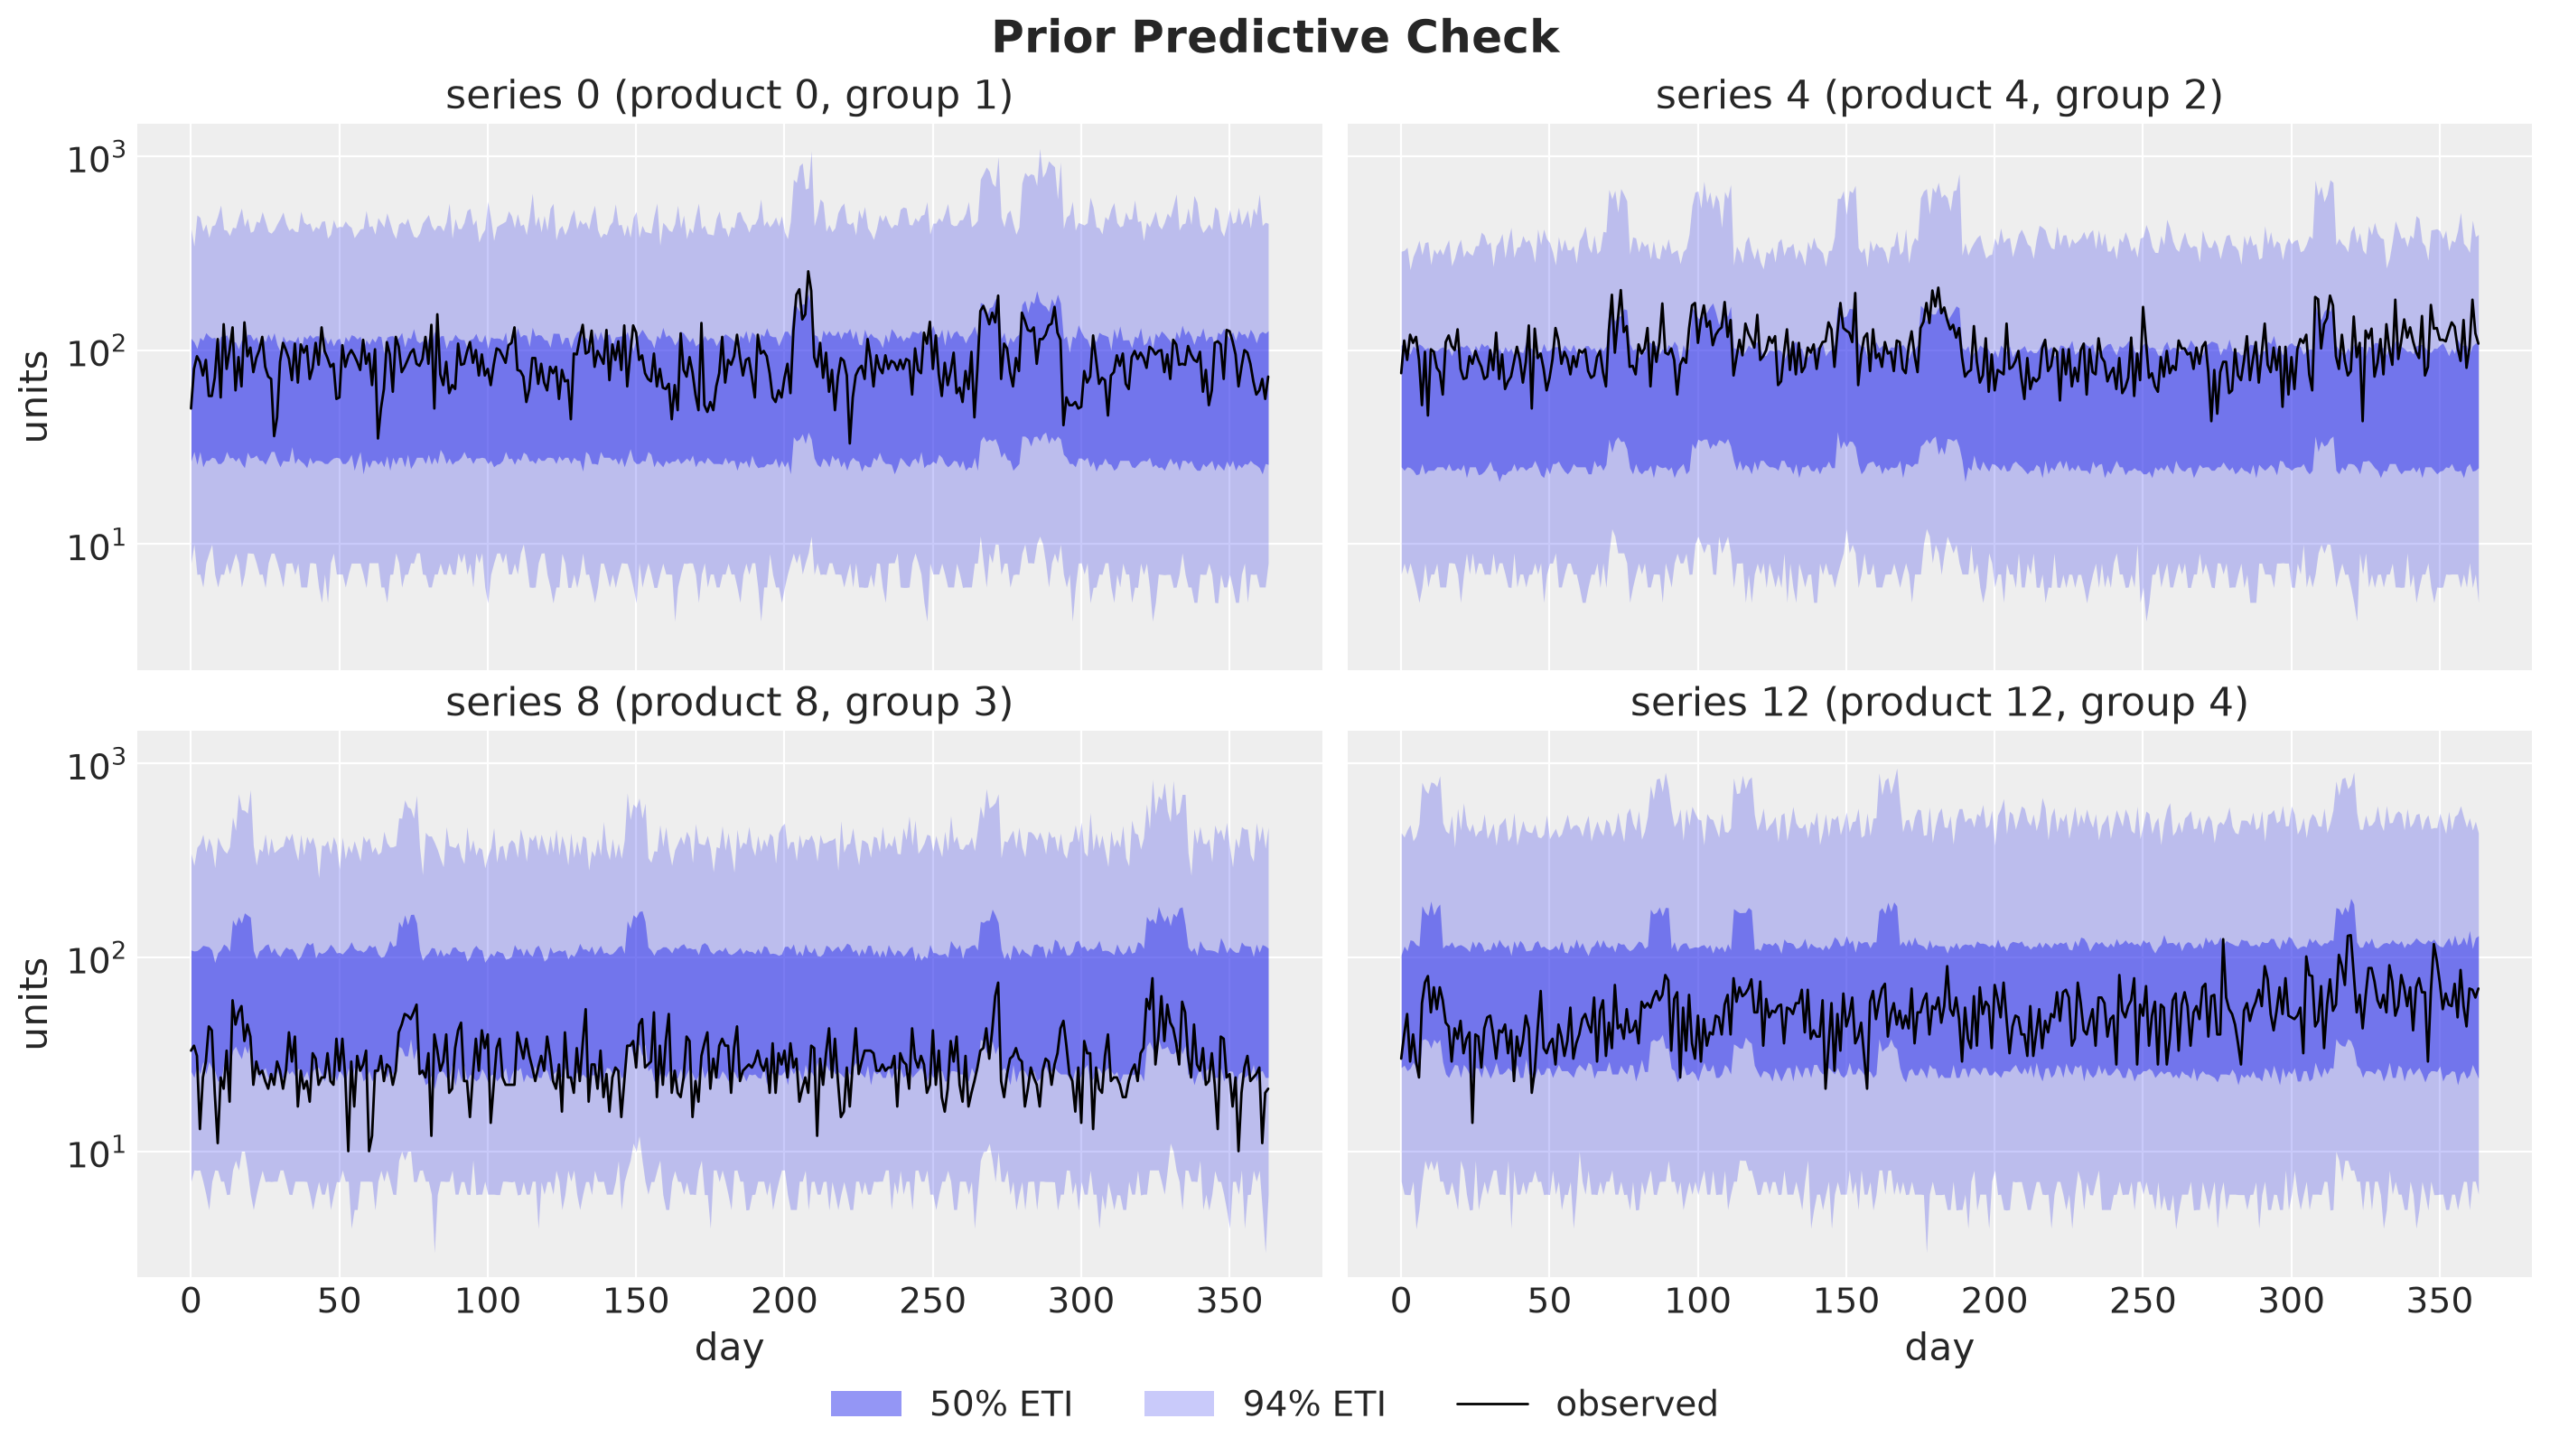

In [17]:
def lighten_bands(
    pc: az.PlotCollection,
    x: str,
    prob_alpha: tuple[tuple[float, float], ...] = ((0.5, 0.5), (CI_PROB, 0.25)),
) -> None:
    """Set the alpha of the credible bands of a `plot_lm` collection."""
    bands = pc.viz["ci_band"][x]
    for prob, alpha in prob_alpha:
        for band in bands.sel(prob=prob).values.flat:
            band.set_alpha(alpha)


check_series = np.arange(4) * setup.n_per_group  # the first product of groups 1 to 4
check_labels = [
    f"series {i} (product {i}, group {g + 1})" for g, i in enumerate(check_series)
]


def plot_predictive_check(
    obs_draws: Shaped[Array, "sample t_obs n_check"], title: str, yscale: str = "linear"
) -> None:
    """Bands of predictive draws of the check series against the history."""
    tree = az.from_dict(
        {
            # the group name is the one `plot_lm` reads by default
            "posterior_predictive": {"obs": obs_draws[None].transpose(0, 1, 3, 2)},
            "observed_data": {"obs": data[:, check_series].T},
            "constant_data": {
                "day": np.tile(days[: setup.t_obs].astype(float), (4, 1))
            },
        },
        coords={"series": check_labels, "time": days[: setup.t_obs]},
        dims={"obs": ["series", "time"], "day": ["series", "time"]},
    )
    pc = az.plot_lm(
        tree,
        x="day",
        y="obs",
        y_obs="obs",
        plot_dim="time",
        smooth=False,
        ci_prob=(0.5, CI_PROB),
        visuals={
            "ci_band": {"color": "C0"},
            "observed_scatter": False,
            "pe_line": False,
            "xlabel": False,
            "ylabel": False,
        },
        col_wrap=2,
        figure_kwargs={"figsize": (14, 8), "sharex": True, "sharey": True},
    )
    lighten_bands(pc, "day")
    for k, label in enumerate(check_labels):
        ax = pc.get_target("day", {"series": label})
        bands = pc.viz["ci_band"]["day"].sel(series=label)
        bands.sel(prob=0.5).item().set_label("50% ETI")
        bands.sel(prob=CI_PROB).item().set_label(f"{CI_PROB:.0%} ETI")
        ax.plot(
            days[: setup.t_obs],
            data[:, check_series[k]],
            color="black",
            linewidth=1,
            label="observed",
        )
        ax.set(
            title=label,
            yscale=yscale,
            xlabel="day" if k >= 2 else "",
            ylabel="units" if k % 2 == 0 else "",
        )
    fig = pc.viz["figure"].item()
    fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=3)
    fig.suptitle(title, fontsize=18, fontweight="bold")


rng_key, key_prior = random.split(rng_key)
prior_obs = Predictive(model_cross, num_samples=300, return_sites=["obs"])(
    key_prior, covariates_train
)["obs"]
plot_predictive_check(
    prior_obs[..., check_series], "Prior Predictive Check", yscale="log"
);

The priors put the demand on the right order of magnitude. The $50\%$ band runs from about $25$ to about $110$ units on a typical day, and the $94\%$ band from about $7$ units to several hundred. The four observed series stay inside the wide band on every day.

The bumps of the bands are the own promotion weeks of each product. Nothing here is implausible for products that sell tens of units per day, so we move on to the fit.

## Model Fitting

### Variational Inference

Each model has about $73K$ latent variables, $72{,}800$ of them the level increments of the $200$ series. That puts NUTS out of reach for a notebook, so we use stochastic variational inference (SVI), which also makes it cheap to fit two models.

We use a mean-field Normal guide, `AutoNormal`, which gives every latent variable its own Normal and ignores the posterior correlations. A guide of this form tends to underestimate the posterior variance, see [Blei, Kucukelbir and McAuliffe (2017)](https://doi.org/10.1080/01621459.2017.1285773). The level increments of a random walk and their scale are correlated a posteriori, so we expect the guide to be too narrow somewhere.

Instead of the convergence diagnostics of NUTS we run four checks. The second and the fourth need the known truth, which the synthetic data give us.

1. **The loss trace.** The negative evidence lower bound (ELBO) has to settle.
2. **Parameter recovery.** The posterior has to cover the true parameters, including the level at the end of the history that the forecast starts from.
3. **Posterior predictive check.** The predictive distribution has to follow the history.
4. **Forecast width.** We compare the width of the predictive distribution with the width of the evaluation scenarios.

The function `fit_svi` runs Adam on the ELBO for a fixed number of steps. The step size follows a cosine decay from $0.01$ to $0.0005$, so that the noise of the gradient moves the last iterates less. We initialize at the median of a few prior draws.

The `FitConfig` tuple holds these settings and the number of posterior draws, which is also the number of scenarios that we solve every plan on.

In [18]:
class FitConfig(NamedTuple):
    """Settings of the variational fit."""

    n_svi_steps: int = 10_000
    step_size: float = 0.01  # initial step size of Adam
    step_size_final_ratio: float = 0.05  # final step size over the initial one
    n_scenarios: int = 1_000  # posterior draws, the optimization scenarios of a plan


def fit_svi(
    model: ForecastModel, rng_key: PRNGKeyArray, fit: FitConfig
) -> tuple[AutoNormal, SVIRunResult]:
    """Fit a mean-field Normal guide to `model` on the history."""
    guide = AutoNormal(model, init_loc_fn=init_to_median(num_samples=15))
    schedule = optax.cosine_decay_schedule(
        fit.step_size, fit.n_svi_steps, alpha=fit.step_size_final_ratio
    )
    svi = SVI(model, guide, optax_to_numpyro(optax.adam(schedule)), Trace_ELBO())
    result = svi.run(
        rng_key, fit.n_svi_steps, covariates_train, data, progress_bar=False
    )
    return guide, result


fit_config = FitConfig()

### Random Walk Parameterization

We can write the random walk of every series in two bases. The plain one samples the $364$ standardized increments of the series one by one. The `time_reparam` wrapper of `numpyro_forecast`, a port of the `time_reparam` option of Pyro's [forecasting module](https://docs.pyro.ai/en/stable/contrib.forecast.html), samples their discrete cosine transform (DCT) instead.

The transform is orthonormal, so the model is the same, and the guide now factorizes over the cosine coefficients.

The increments of a random walk are correlated a posteriori, because the data pin down their partial sums. In the cosine basis they are less correlated, so a mean-field guide loses less.

We fit the cross model both ways, with the same key and the same number of steps.

In [19]:
%%time

basis_models = {"plain": model_cross, "dct": time_reparam(model_cross, "dct")}
rng_key, key_svi = random.split(rng_key)
basis_fits = {
    name: fit_svi(model, key_svi, fit_config) for name, model in basis_models.items()
}

CPU times: user 1min 43s, sys: 29.8 s, total: 2min 13s
Wall time: 32.4 s


For each fit we draw $1{,}000$ posterior samples with `draw_posterior` and forecast the horizon with `forecast`. We keep the parameters, the level of every series at the end of the history and the forecast scenarios of each fit in a `FitDraws` tuple.

The following table compares the two bases on the loss, on the recovery of the drift scale, the concentration and the level, and on two scores of the forecast on the realized future. The scores are the coverage of the $94\%$ interval and the continuous ranked probability score (CRPS).

In [20]:
class FitDraws(NamedTuple):
    """Posterior draws of one fit."""

    parameters: dict[str, Array]  # the parameter sites, on their natural scale
    level_end: Float[Array, "sample n_series"]  # level at the end of the history
    scenarios: Float[Array, "sample horizon n_series"]  # forecast of the horizon


PARAMETER_SITES = (
    "intercept",
    "drift_scale",
    "beta",
    "elasticity",
    "concentration",
    "cross_scale",
    "cross_elasticity",
)


def latent_draws(
    rng_key: PRNGKeyArray, guide: AutoNormal, result: SVIRunResult, num_samples: int
) -> tuple[dict[str, Array], dict[str, Array]]:
    """Posterior draws of all sites, and the subset that the guide samples."""
    draws = draw_posterior(rng_key, guide, result.params, num_samples)
    sampled = {
        name: draws[name]
        for name, site in guide.prototype_trace.items()
        if site["type"] == "sample" and not site["is_observed"]
    }
    return draws, sampled


def draw_fit(
    rng_key: PRNGKeyArray,
    model: ForecastModel,
    guide: AutoNormal,
    result: SVIRunResult,
    num_samples: int,
) -> FitDraws:
    """Parameters, level at the end of the history and forecast of one fit."""
    key_draw, key_forecast = random.split(rng_key)
    draws, sampled = latent_draws(key_draw, guide, result, num_samples)
    # `forecast` rebuilds the increments from their sampled site, so it takes the
    # sampled sites only, not the deterministic copies
    scenarios = forecast(
        key_forecast, model, sampled, data, covariates, batch_size=250
    ).astype(jnp.float32)
    return FitDraws(
        parameters={name: draws[name] for name in PARAMETER_SITES if name in draws},
        level_end=draws["intercept"] + draws["drift"].sum(axis=1),
        scenarios=scenarios,
    )


def recovery_ratio(
    draws: Float[Array, " sample *shape"], truth: Float[Array, " *shape"]
) -> float:
    """Median over the entries of the posterior mean divided by the truth."""
    nonzero = truth != 0
    return float(jnp.median(draws.mean(axis=0)[nonzero] / truth[nonzero]))


def rmse(
    draws: Float[Array, " sample *shape"], truth: Float[Array, " *shape"]
) -> float:
    """Root mean square error of the posterior mean over the entries."""
    return float(jnp.sqrt(((draws.mean(axis=0) - truth) ** 2).mean()))


level_end_true = true_params["intercept"] + drift_true.sum(axis=0)
basis_draws = {}
for name, (guide, result) in basis_fits.items():
    rng_key, key_fit = random.split(rng_key)
    basis_draws[name] = draw_fit(
        key_fit, basis_models[name], guide, result, fit_config.n_scenarios
    )

basis_check = pl.DataFrame(
    [
        {
            "basis": name,
            "negative ELBO": round(float(result.losses[-500:].mean())),
            "drift_scale ratio": recovery_ratio(
                fit.parameters["drift_scale"], true_params["drift_scale"]
            ),
            "concentration ratio": recovery_ratio(
                fit.parameters["concentration"], true_params["concentration"]
            ),
            "level RMSE": rmse(fit.level_end, level_end_true),
            "CRPS": float(crps_empirical(fit.scenarios, demand_future_true).mean()),
            f"coverage {CI_PROB:.0%}": float(
                eval_coverage(fit.scenarios, demand_future_true, alpha=CI_PROB)
            ),
        }
        for (name, (_, result)), fit in zip(
            basis_fits.items(), basis_draws.values(), strict=True
        )
    ]
)
basis_check

basis,negative ELBO,drift_scale ratio,concentration ratio,level RMSE,CRPS,coverage 94%
str,i64,f64,f64,f64,f64,f64
"""plain""",299789,0.285,0.880,0.077,9.981,0.951
"""dct""",297370,0.915,0.990,0.056,9.658,0.944


The two ratios are the posterior mean over the truth, and the negative ELBO is the mean of the last $500$ steps.

- **Plain basis.** The drift scale is at $29\%$ of its true value and the concentration is $12\%$ too low. The fit explains the day-to-day movement of the series with noise instead of with the level.
- **DCT basis.** The fit recovers the concentration ($99\%$ of the truth) and most of the drift scale ($92\%$), and its negative ELBO is about $2{,}400$ lower. The posterior mean of the level at the end of the history is closer to the truth, with a root mean square error (RMSE) of $0.056$ against $0.077$ on the log scale.

The two forecasts of the realized future are close on coverage and CRPS, because the observation noise dominates a single day. The level is what the plan starts from, so we keep the DCT fit.

### Model Fits

We fit the independent model in the DCT basis with the same settings and keep the two DCT fits from here on.

In [21]:
%%time


class Model(StrEnum):
    """The two forecasting models."""

    INDEPENDENT = "independent"
    CROSS = "cross"


models = {
    Model.INDEPENDENT: time_reparam(model_independent, "dct"),
    Model.CROSS: basis_models["dct"],
}
guides = {Model.CROSS: basis_fits["dct"][0]}
svi_results = {Model.CROSS: basis_fits["dct"][1]}
guides[Model.INDEPENDENT], svi_results[Model.INDEPENDENT] = fit_svi(
    models[Model.INDEPENDENT], key_svi, fit_config
)

rng_key, key_fit = random.split(rng_key)
draws = {
    Model.INDEPENDENT: draw_fit(
        key_fit,
        models[Model.INDEPENDENT],
        guides[Model.INDEPENDENT],
        svi_results[Model.INDEPENDENT],
        fit_config.n_scenarios,
    ),
    Model.CROSS: basis_draws["dct"],
}
for model in models:
    assert draws[model].scenarios.shape == (
        fit_config.n_scenarios,
        setup.horizon,
        setup.n_series,
    )

CPU times: user 1min 55s, sys: 31 s, total: 2min 26s
Wall time: 36.1 s


The following figure shows the loss of the two fits. We drop the first fifth of the steps so that the end of the trace is visible.

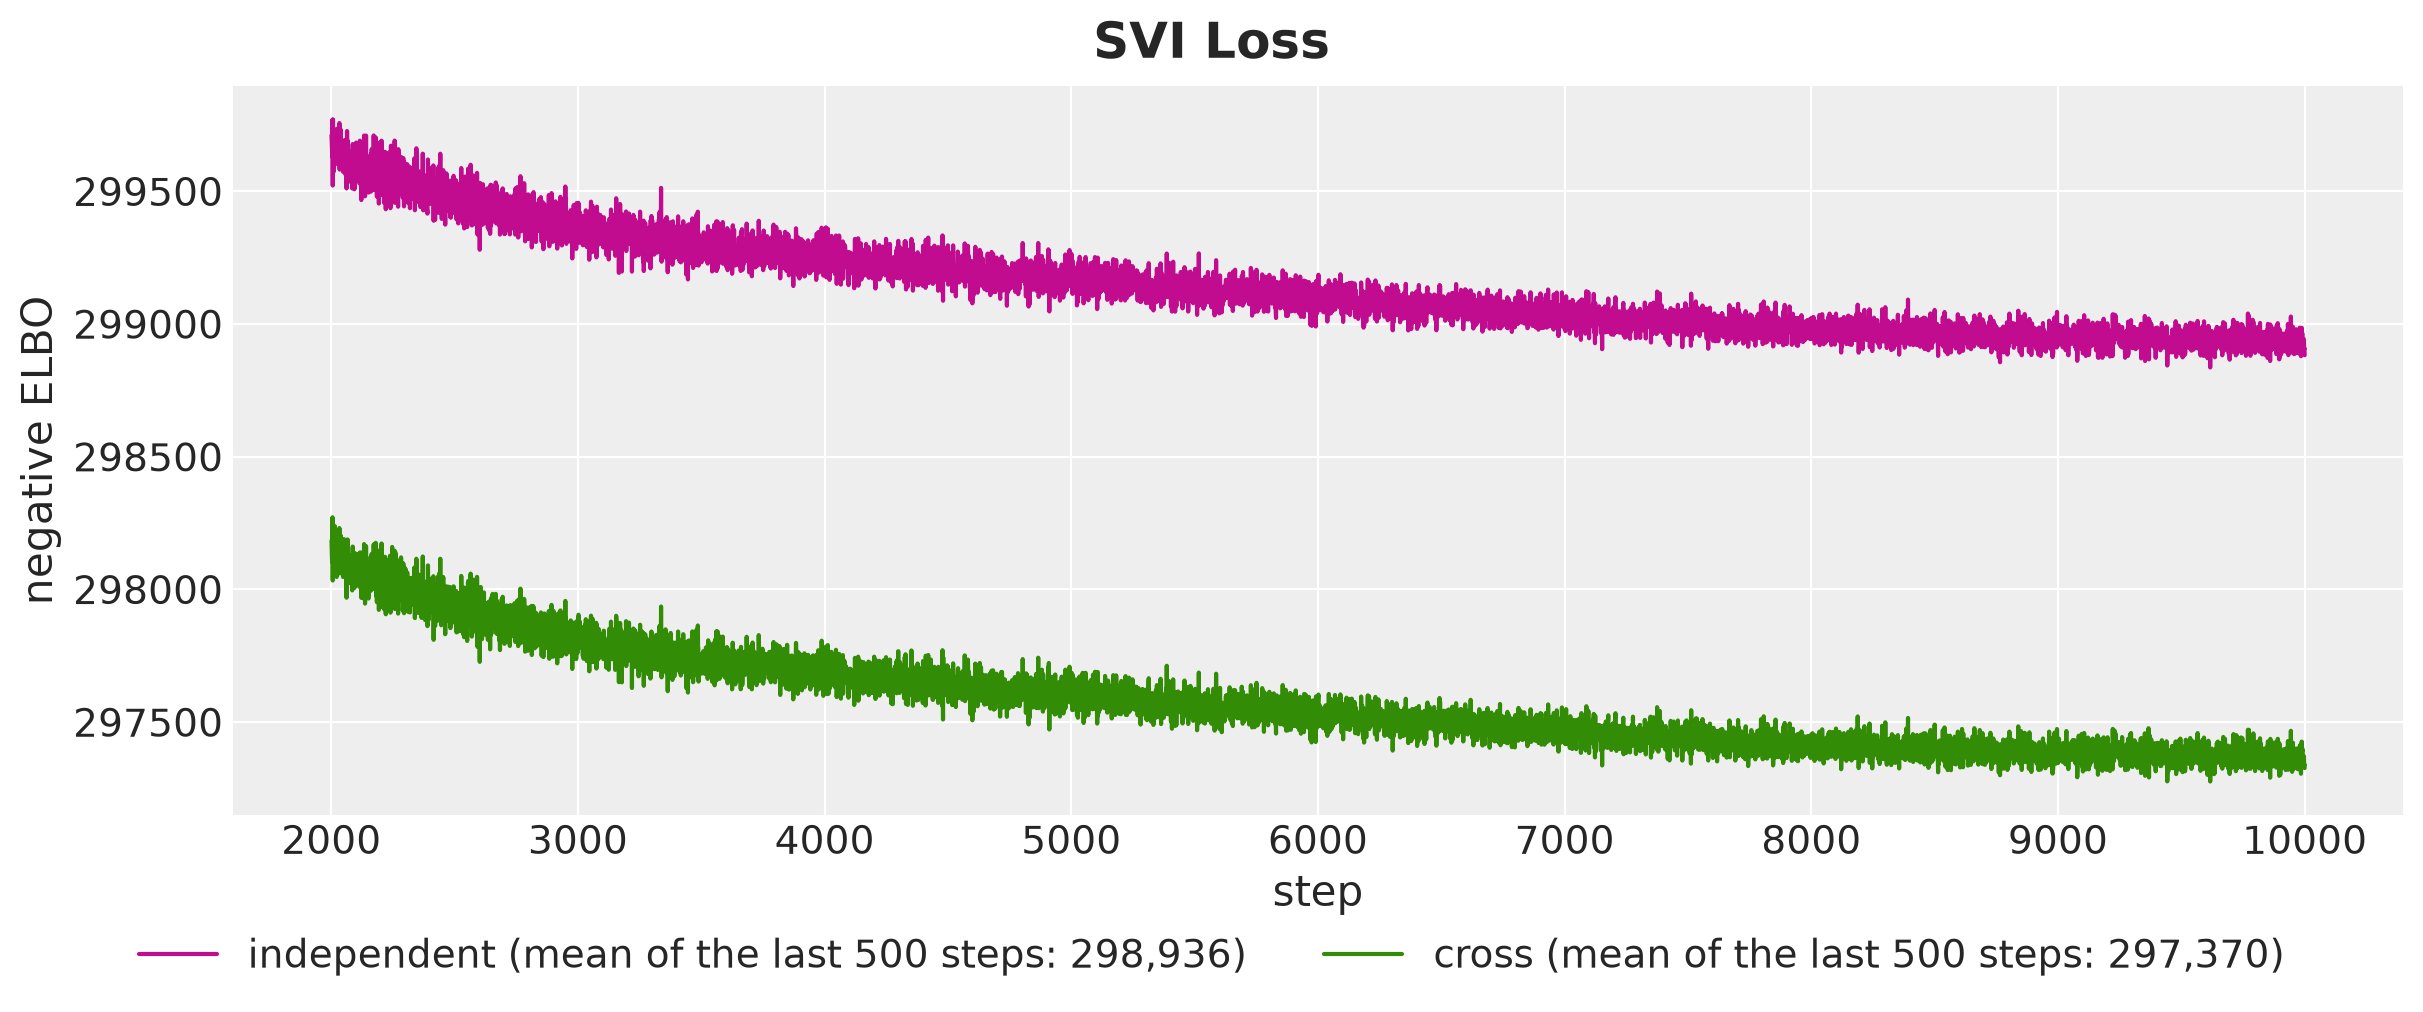

In [22]:
MODEL_COLORS = {Model.INDEPENDENT: "C3", Model.CROSS: "C2"}

fig, ax = plt.subplots(figsize=(12, 5))
for model in models:
    losses = svi_results[model].losses
    steps = np.arange(1, losses.size + 1)
    keep = steps > fit_config.n_svi_steps // 5
    ax.plot(
        steps[keep],
        losses[keep],
        color=MODEL_COLORS[model],
        label=f"{model} (mean of the last 500 steps: {losses[-500:].mean():,.0f})",
    )
ax.set(xlabel="step", ylabel="negative ELBO")
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle("SVI Loss", fontsize=18, fontweight="bold");

Both traces decrease more and more slowly and are close to flat over the last $1{,}000$ steps. Part of this is the decay of the step size, so a flat trace alone does not show convergence, and we rely on the checks of the next sections.

The cross model ends about $1{,}600$ lower than the independent model, at $297{,}370$ against $298{,}936$, which is what the cross-price term adds on the same data.

Next, let's look at the posterior of `cross_scale`, the common scale of the cross elasticities.

In [23]:
az.summary(
    az.from_dict(
        {
            "posterior": {
                "cross_scale": draws[Model.CROSS].parameters["cross_scale"][None]
            }
        }
    ),
    kind="stats",
)

,mean,sd,eti94_lb,eti94_ub
cross_scale,0.32,0.0037,0.31,0.32


The posterior mean of `cross_scale` is $0.32$, close to the root mean square of the $60$ true cross elasticities ($0.33$).

## Parameter Recovery

We compare the posterior of each model with the true parameters and with the true level of every series at the end of the history.

### Elasticities

First, we look at the own elasticities. We plot the posterior of `elasticity` minus its true value for every product and both models, so that a well-recovered parameter has an interval that covers zero.

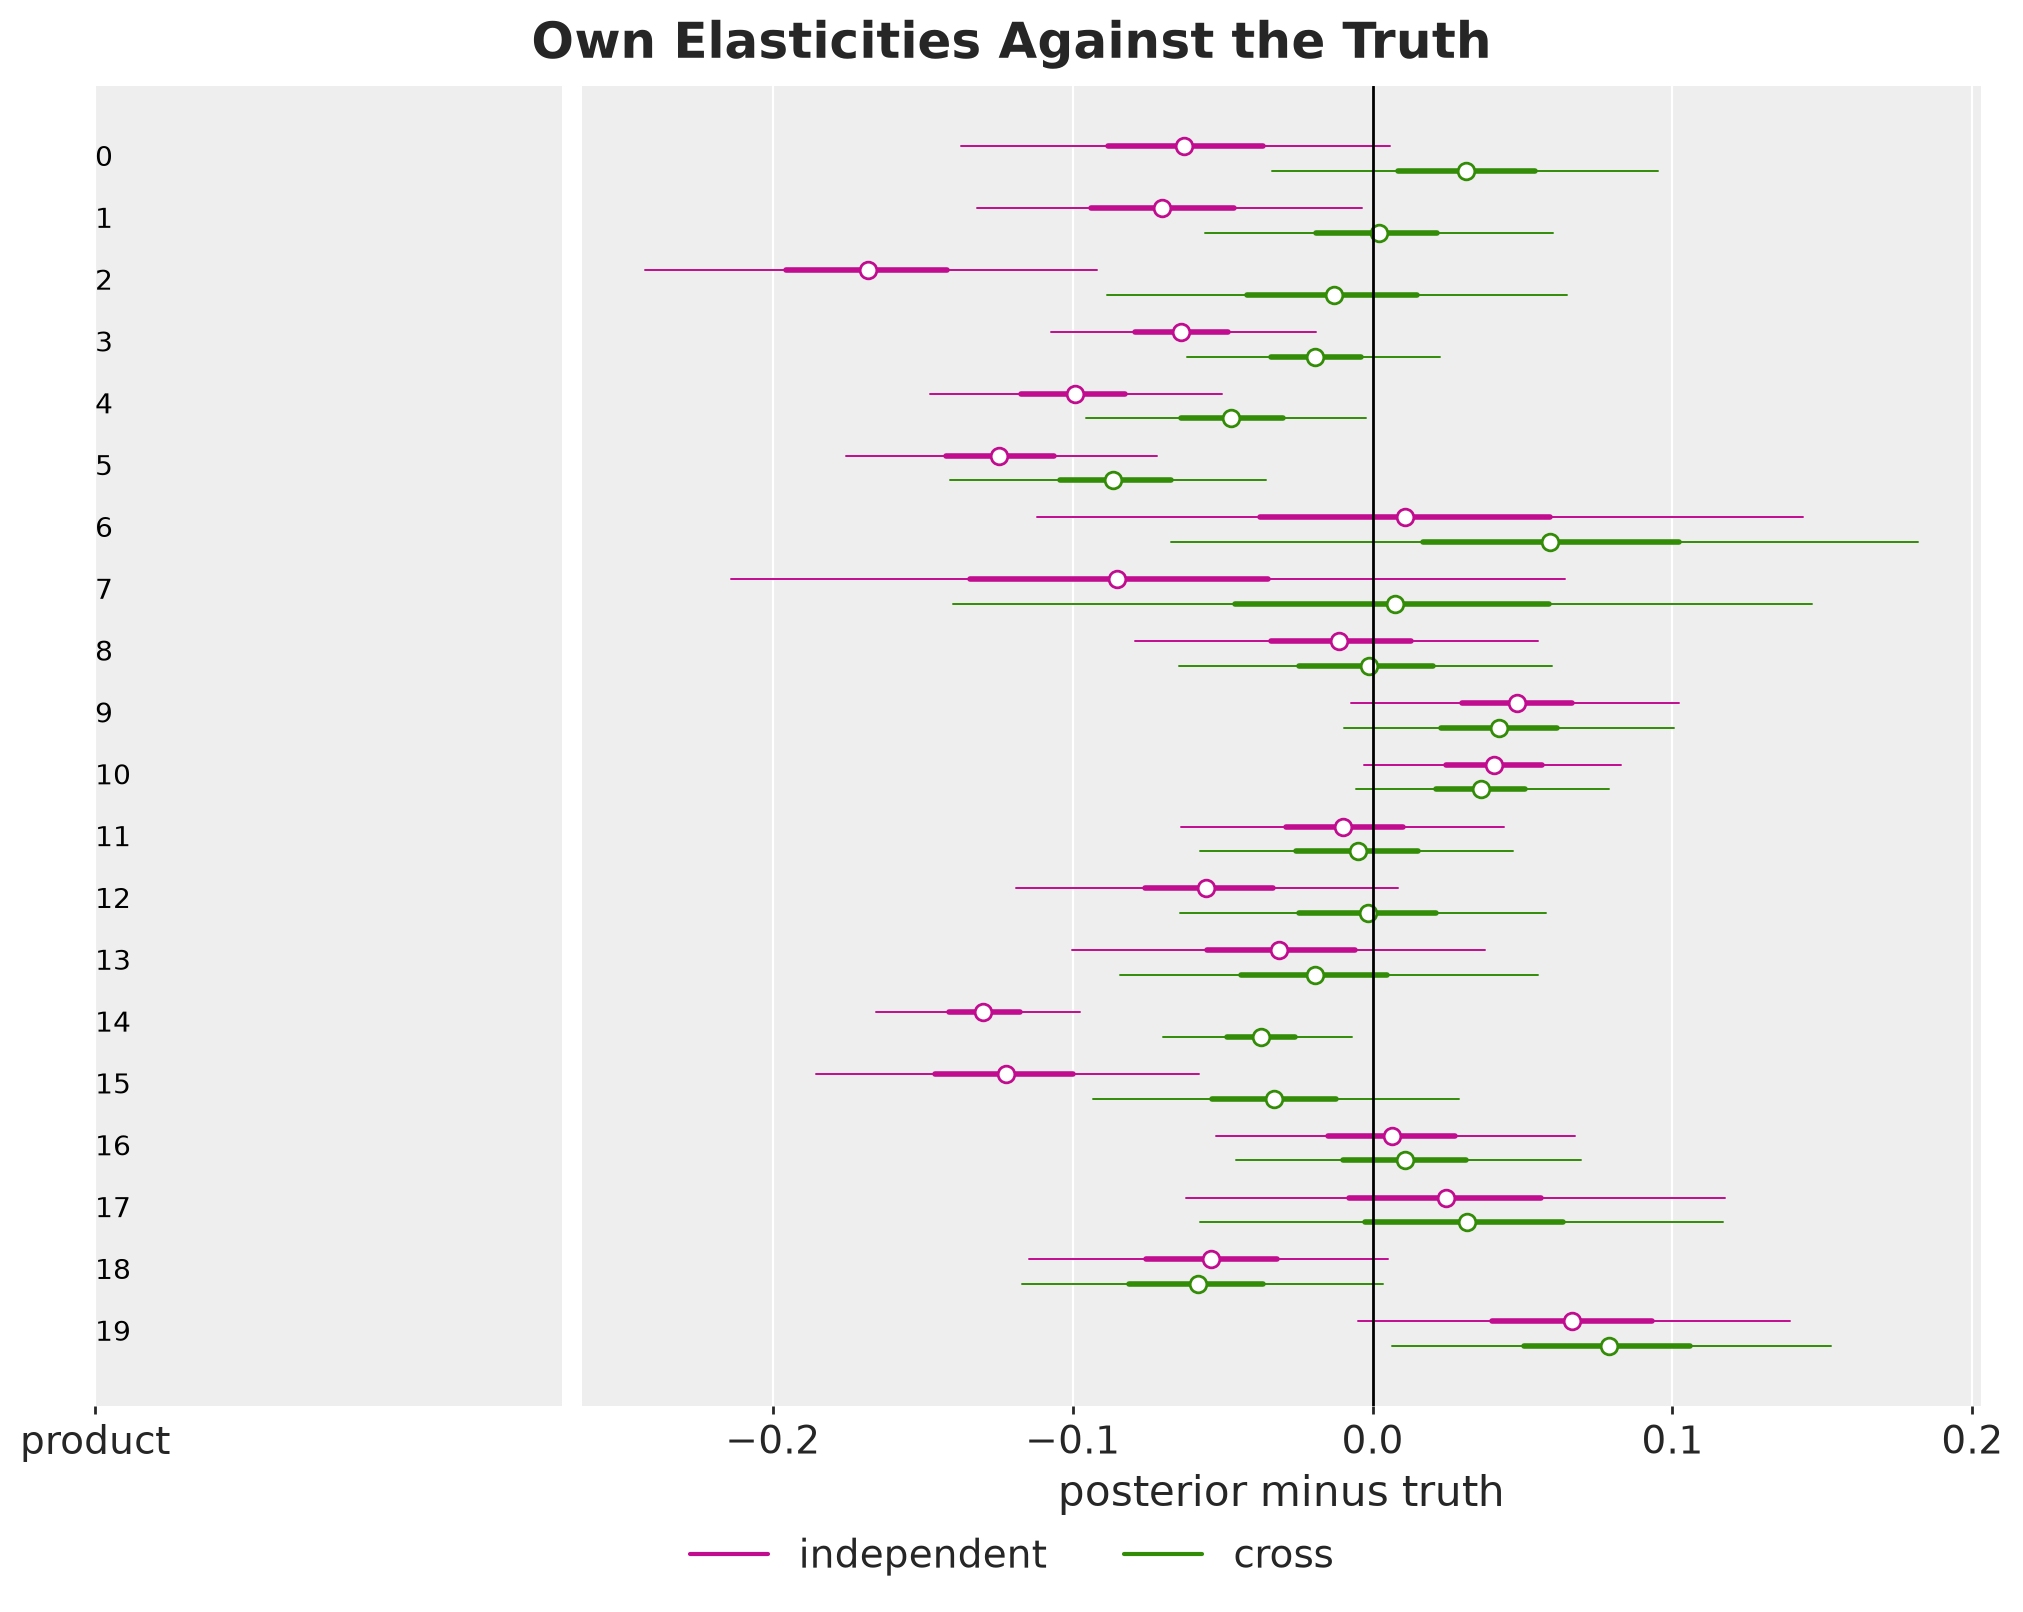

In [24]:
def minus_truth(model: Model, site: str, dim: str, labels: list[str]) -> xr.Dataset:
    """Posterior draws of `site` under `model` minus the true value."""
    error = draws[model].parameters[site] - true_params[site]
    return xr.Dataset({site: (("sample", dim), error)}, coords={dim: labels})


product_labels = [str(product) for product in range(setup.n_products)]
pc = az.plot_forest(
    {
        model: minus_truth(model, "elasticity", "product", product_labels)
        for model in models
    },
    sample_dims=["sample"],
    labels=["product"],
    color=[MODEL_COLORS[model] for model in models],
    figure_kwargs={"figsize": (10, 8)},
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(0.0, color="black", linewidth=1)
ax.set(xlabel="posterior minus truth")
pc.add_legend("model", title="", loc="outside lower center", ncol=2)
pc.viz["figure"].item().suptitle(
    "Own Elasticities Against the Truth", fontsize=18, fontweight="bold"
);

The dots are the posterior means and the thick and thin bars the $50\%$ and $94\%$ intervals. The following table averages the posterior mean minus the truth over the four products of each group, for both models.

In [25]:
def by_group(
    values: Float[Array, " n"], groups: Int[np.ndarray, " n"]
) -> dict[str, float]:
    """Mean of the entries of each group, given the group index of every entry."""
    return {
        f"group {group + 1}": float(values[groups == group].mean())
        for group in range(setup.n_groups)
    }


pl.DataFrame(
    [
        {
            "model": model.value,
            **by_group(
                (
                    draws[model].parameters["elasticity"] - true_params["elasticity"]
                ).mean(axis=0),
                panel.product_to_group,
            ),
        }
        for model in models
    ]
)

model,group 1,group 2,group 3,group 4,group 5
str,f64,f64,f64,f64,f64
"""independent""",-0.091,-0.075,0.017,-0.085,0.011
"""cross""",0.000,-0.017,0.018,-0.023,0.016


The two models differ in the groups with cannibalization.

- **Cross model.** The intervals cover zero for $16$ of the $20$ products, and the posterior means lie within $0.03$ of the truth on average in every group.
- **Independent model.** The intervals cover zero for $13$ products. The own elasticities of groups $1$, $2$ and $4$ are $0.07$ to $0.09$ too negative on average, and those of groups $3$ and $5$, the groups without cannibalization, are within $0.02$ of the truth.

This bias is consistent with a level that follows the sibling dips down. Measured against a level that is too low, the lift of an own promotion week looks larger than it is.

The widest intervals belong to products $6$ and $7$ under both models. These are the two products with a single promotion week in the history.

Next, we plot the cross elasticities of the cross model in the same form.

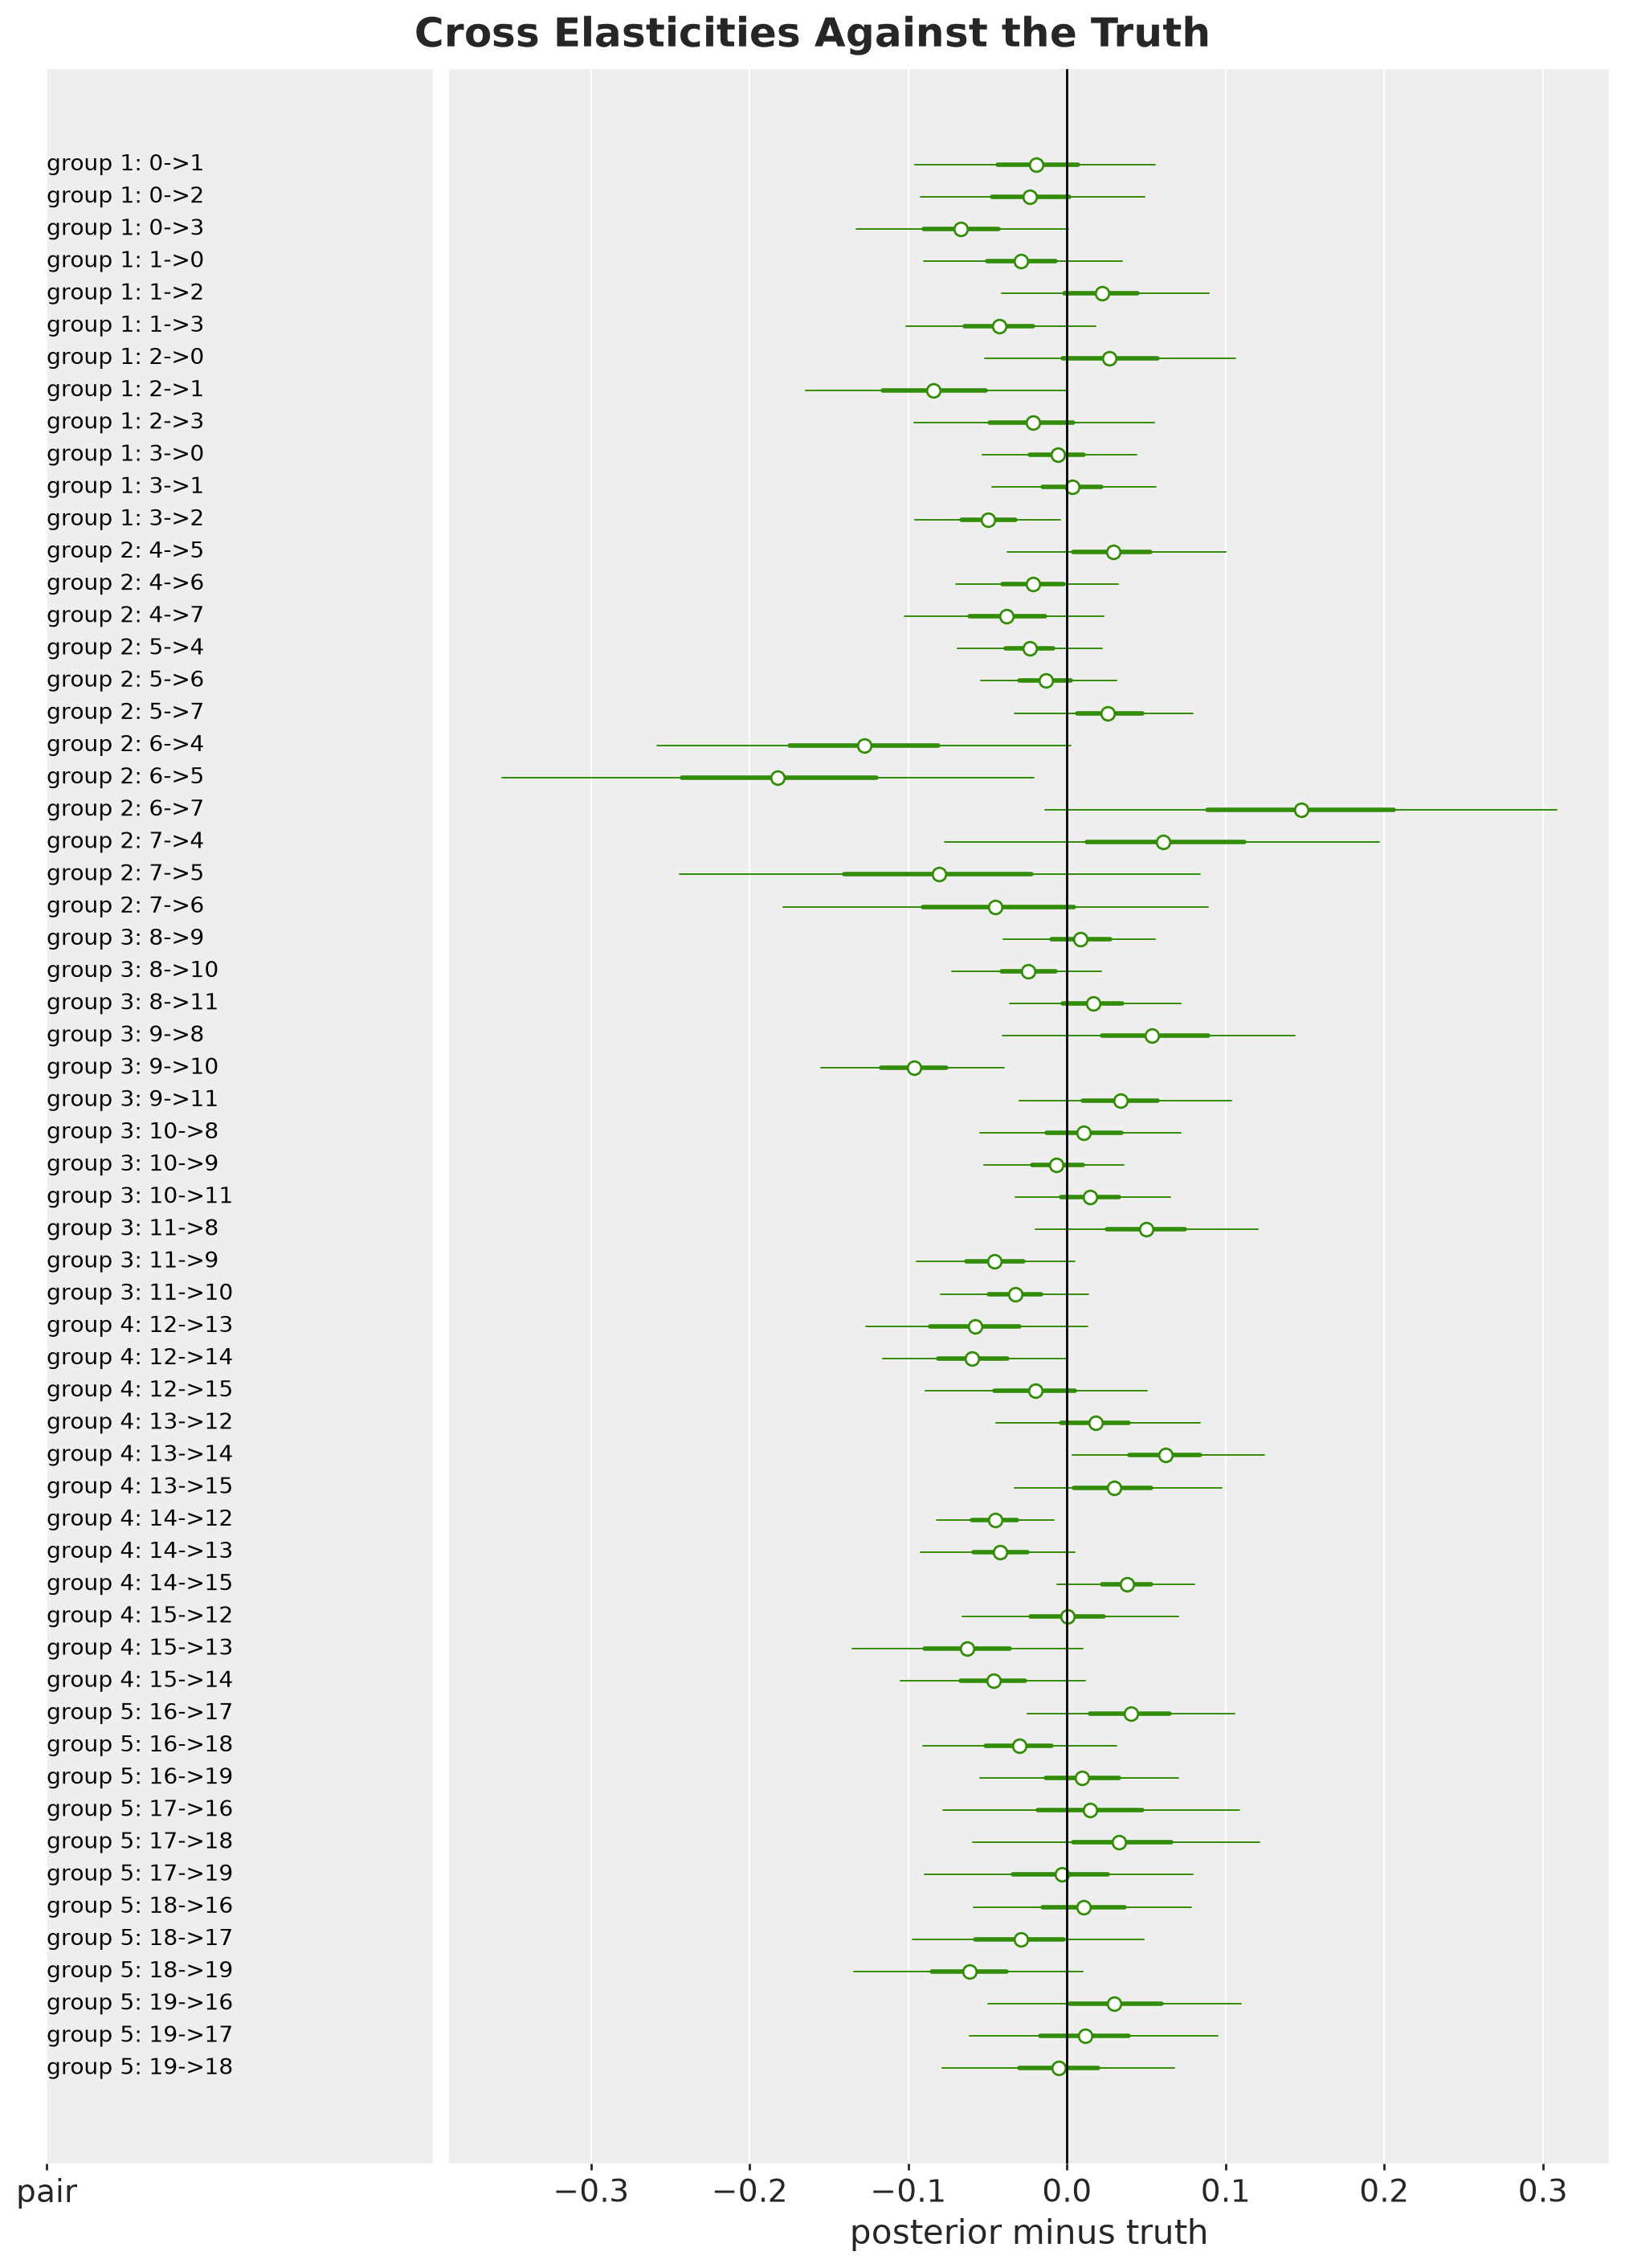

In [26]:
pair_group = panel.product_to_group[panel.pair_rows]
pair_labels = [
    f"group {group + 1}: {source}->{target}"
    for group, source, target in zip(
        pair_group, panel.pair_rows, panel.pair_cols, strict=True
    )
]

pc = az.plot_forest(
    {Model.CROSS: minus_truth(Model.CROSS, "cross_elasticity", "pair", pair_labels)},
    sample_dims=["sample"],
    labels=["pair"],
    color=[MODEL_COLORS[Model.CROSS]],
    figure_kwargs={"figsize": (10, 14)},
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(0.0, color="black", linewidth=1)
ax.set(xlabel="posterior minus truth")
pc.viz["figure"].item().suptitle(
    "Cross Elasticities Against the Truth", fontsize=18, fontweight="bold"
);

A label `k->j` is the response of the demand of product `j` to the price of product `k`. The intervals cover the truth for $54$ of the $60$ pairs, or $90\%$, a little below the $94\%$ of a calibrated interval.

Six of the eight widest intervals belong to pairs that start at product $6$ or $7$. These are again the two products with a single promotion week.

The next table averages the posterior mean of the cross elasticity over the $12$ pairs of each group, next to the true value.

In [27]:
cross_mean = draws[Model.CROSS].parameters["cross_elasticity"].mean(axis=0)
pl.DataFrame(
    [
        {
            "cross elasticity": "true value",
            **by_group(true_params["cross_elasticity"], pair_group),
        },
        {"cross elasticity": "posterior mean", **by_group(cross_mean, pair_group)},
    ]
)

cross elasticity,group 1,group 2,group 3,group 4,group 5
str,f64,f64,f64,f64,f64
"""true value""",0.600,0.300,0.000,0.300,0.000
"""posterior mean""",0.576,0.278,-0.002,0.284,0.002


The posterior means of the groups are $0.58$, $0.28$, $0.00$, $0.28$ and $0.00$. The model finds the cannibalization of groups $1$, $2$ and $4$, a few hundredths below the truth as we expect from the shrinkage, and finds none in groups $3$ and $5$.

### Level and Concentration

The first table is about the families of parameters. For each family and each model it reports the share of true values inside the $94\%$ interval and the median ratio of the posterior mean to the truth. The ratio uses the entries whose true value is not zero.

In [28]:
def coverage_of_truth(
    draws: Float[Array, " sample *shape"], truth: Float[Array, " *shape"]
) -> float:
    """Share of the entries whose true value lies inside the central interval."""
    tail = (1 - CI_PROB) / 2
    lower, upper = jnp.quantile(draws, jnp.array([tail, 1 - tail]), axis=0)
    return float(((truth >= lower) & (truth <= upper)).mean())


pl.DataFrame(
    [
        {
            "model": model.value,
            "parameter": site,
            "coverage of truth": coverage_of_truth(
                draws[model].parameters[site], true_params[site]
            ),
            "posterior mean / truth": recovery_ratio(
                draws[model].parameters[site], true_params[site]
            ),
        }
        for model in models
        for site in ["elasticity", "concentration", "drift_scale", "cross_elasticity"]
        if site in draws[model].parameters
    ]
)

model,parameter,coverage of truth,posterior mean / truth
str,str,f64,f64
"""independent""","""elasticity""",0.650,1.037
"""independent""","""concentration""",0.650,0.945
"""independent""","""drift_scale""",0.395,1.029
"""cross""","""elasticity""",0.800,1.001
"""cross""","""concentration""",0.900,0.990
"""cross""","""drift_scale""",0.450,0.915
"""cross""","""cross_elasticity""",0.900,0.943


The second table is about the level of every series at the end of the history, the quantity the forecast starts from. It reports the coverage, the mean error and the RMSE of the posterior mean on the log scale. The last column divides the RMSE by the median posterior standard deviation, which gives about one for a guide of the right width.

In [29]:
level_error = {
    model: draws[model].level_end.mean(axis=0) - level_end_true for model in models
}
pl.DataFrame(
    [
        {
            "model": model.value,
            "coverage of truth": coverage_of_truth(
                draws[model].level_end, level_end_true
            ),
            "mean error": float(level_error[model].mean()),
            "RMSE": rmse(draws[model].level_end, level_end_true),
            "RMSE / posterior sd": rmse(draws[model].level_end, level_end_true)
            / float(jnp.median(draws[model].level_end.std(axis=0))),
        }
        for model in models
    ]
)

model,coverage of truth,mean error,RMSE,RMSE / posterior sd
str,f64,f64,f64,f64
"""independent""",0.595,-0.020,0.072,2.570
"""cross""",0.655,0.008,0.056,2.009


The third table splits two quantities by group, since the groups differ in how much cannibalization their history holds. The quantities are the ratio of the posterior mean of the concentration to the truth and the mean error of the level.

In [30]:
series_group = panel.product_to_group[panel.series_to_product]
pl.DataFrame(
    [
        {"model": model.value, "quantity": quantity, **by_group(values, groups)}
        for model in models
        for quantity, values, groups in [
            (
                "concentration: posterior mean / truth",
                draws[model].parameters["concentration"].mean(axis=0)
                / true_params["concentration"],
                panel.product_to_group,
            ),
            ("level: mean error", level_error[model], series_group),
        ]
    ]
)

model,quantity,group 1,group 2,group 3,group 4,group 5
str,str,f64,f64,f64,f64,f64
"""independent""","""concentration: posterior mean / truth""",0.864,0.940,1.018,0.949,0.952
"""independent""","""level: mean error""",-0.064,-0.012,0.014,-0.047,0.008
"""cross""","""concentration: posterior mean / truth""",0.979,0.987,1.015,1.023,0.952
"""cross""","""level: mean error""",0.023,0.005,0.013,-0.010,0.008


For the parameters we see the following.

- **Cross model.** The own and the cross elasticities are covered at $80\%$ and $90\%$, and their posterior means are on or close to the truth. The concentration is $1\%$ low and the drift scale $8\%$ low. The interval of the drift scale covers the truth for only $45\%$ of the series, so these intervals are too narrow, with the mean-field guide as the likely cause.
- **Independent model.** The concentration is $6\%$ low. In the third table it is $14\%$ low in group $1$, where the sibling dips are the largest, and the same as under the cross model in groups $3$ and $5$, which have none. This is consistent with a model that treats the unexplained dips as noise. Its own elasticities are covered at $65\%$, for the reason we saw in the figure.

For the level at the end of the history we see the following.

- **Error.** The posterior mean of the level has an RMSE of $0.056$ for the cross model and $0.072$ for the independent model on the log scale, about $6\%$ to $7\%$ of the level.
- **Width.** The RMSE is $2.0$ and $2.6$ times the posterior standard deviation, and the $94\%$ intervals cover the truth for $66\%$ and $60\%$ of the series. The guide is overconfident about the level of every series. For the independent model the ratio also contains its bias.
- **Bias.** The mean error of the cross model is $0.008$. The independent model is $0.020$ low on average, that is, $2\%$ of the level. By group, it is $0.064$ low in group $1$ and $0.047$ low in group $4$, and within $0.02$ of the cross model in the other three groups.

The overconfidence is what we expected from a mean-field guide. We come back to it in the *Out of Sample Evaluation* section, where it shows up as a cost. We look at the bias of the independent model in the *Demand Scenarios* section.

## Posterior Predictive Checks

Before we look at the forecast, we check the fit on the history. We draw $300$ predictive paths of each model over the history and compute their CRPS over all days and all $200$ series. We plot the paths of the cross model for the four series of the prior predictive check.

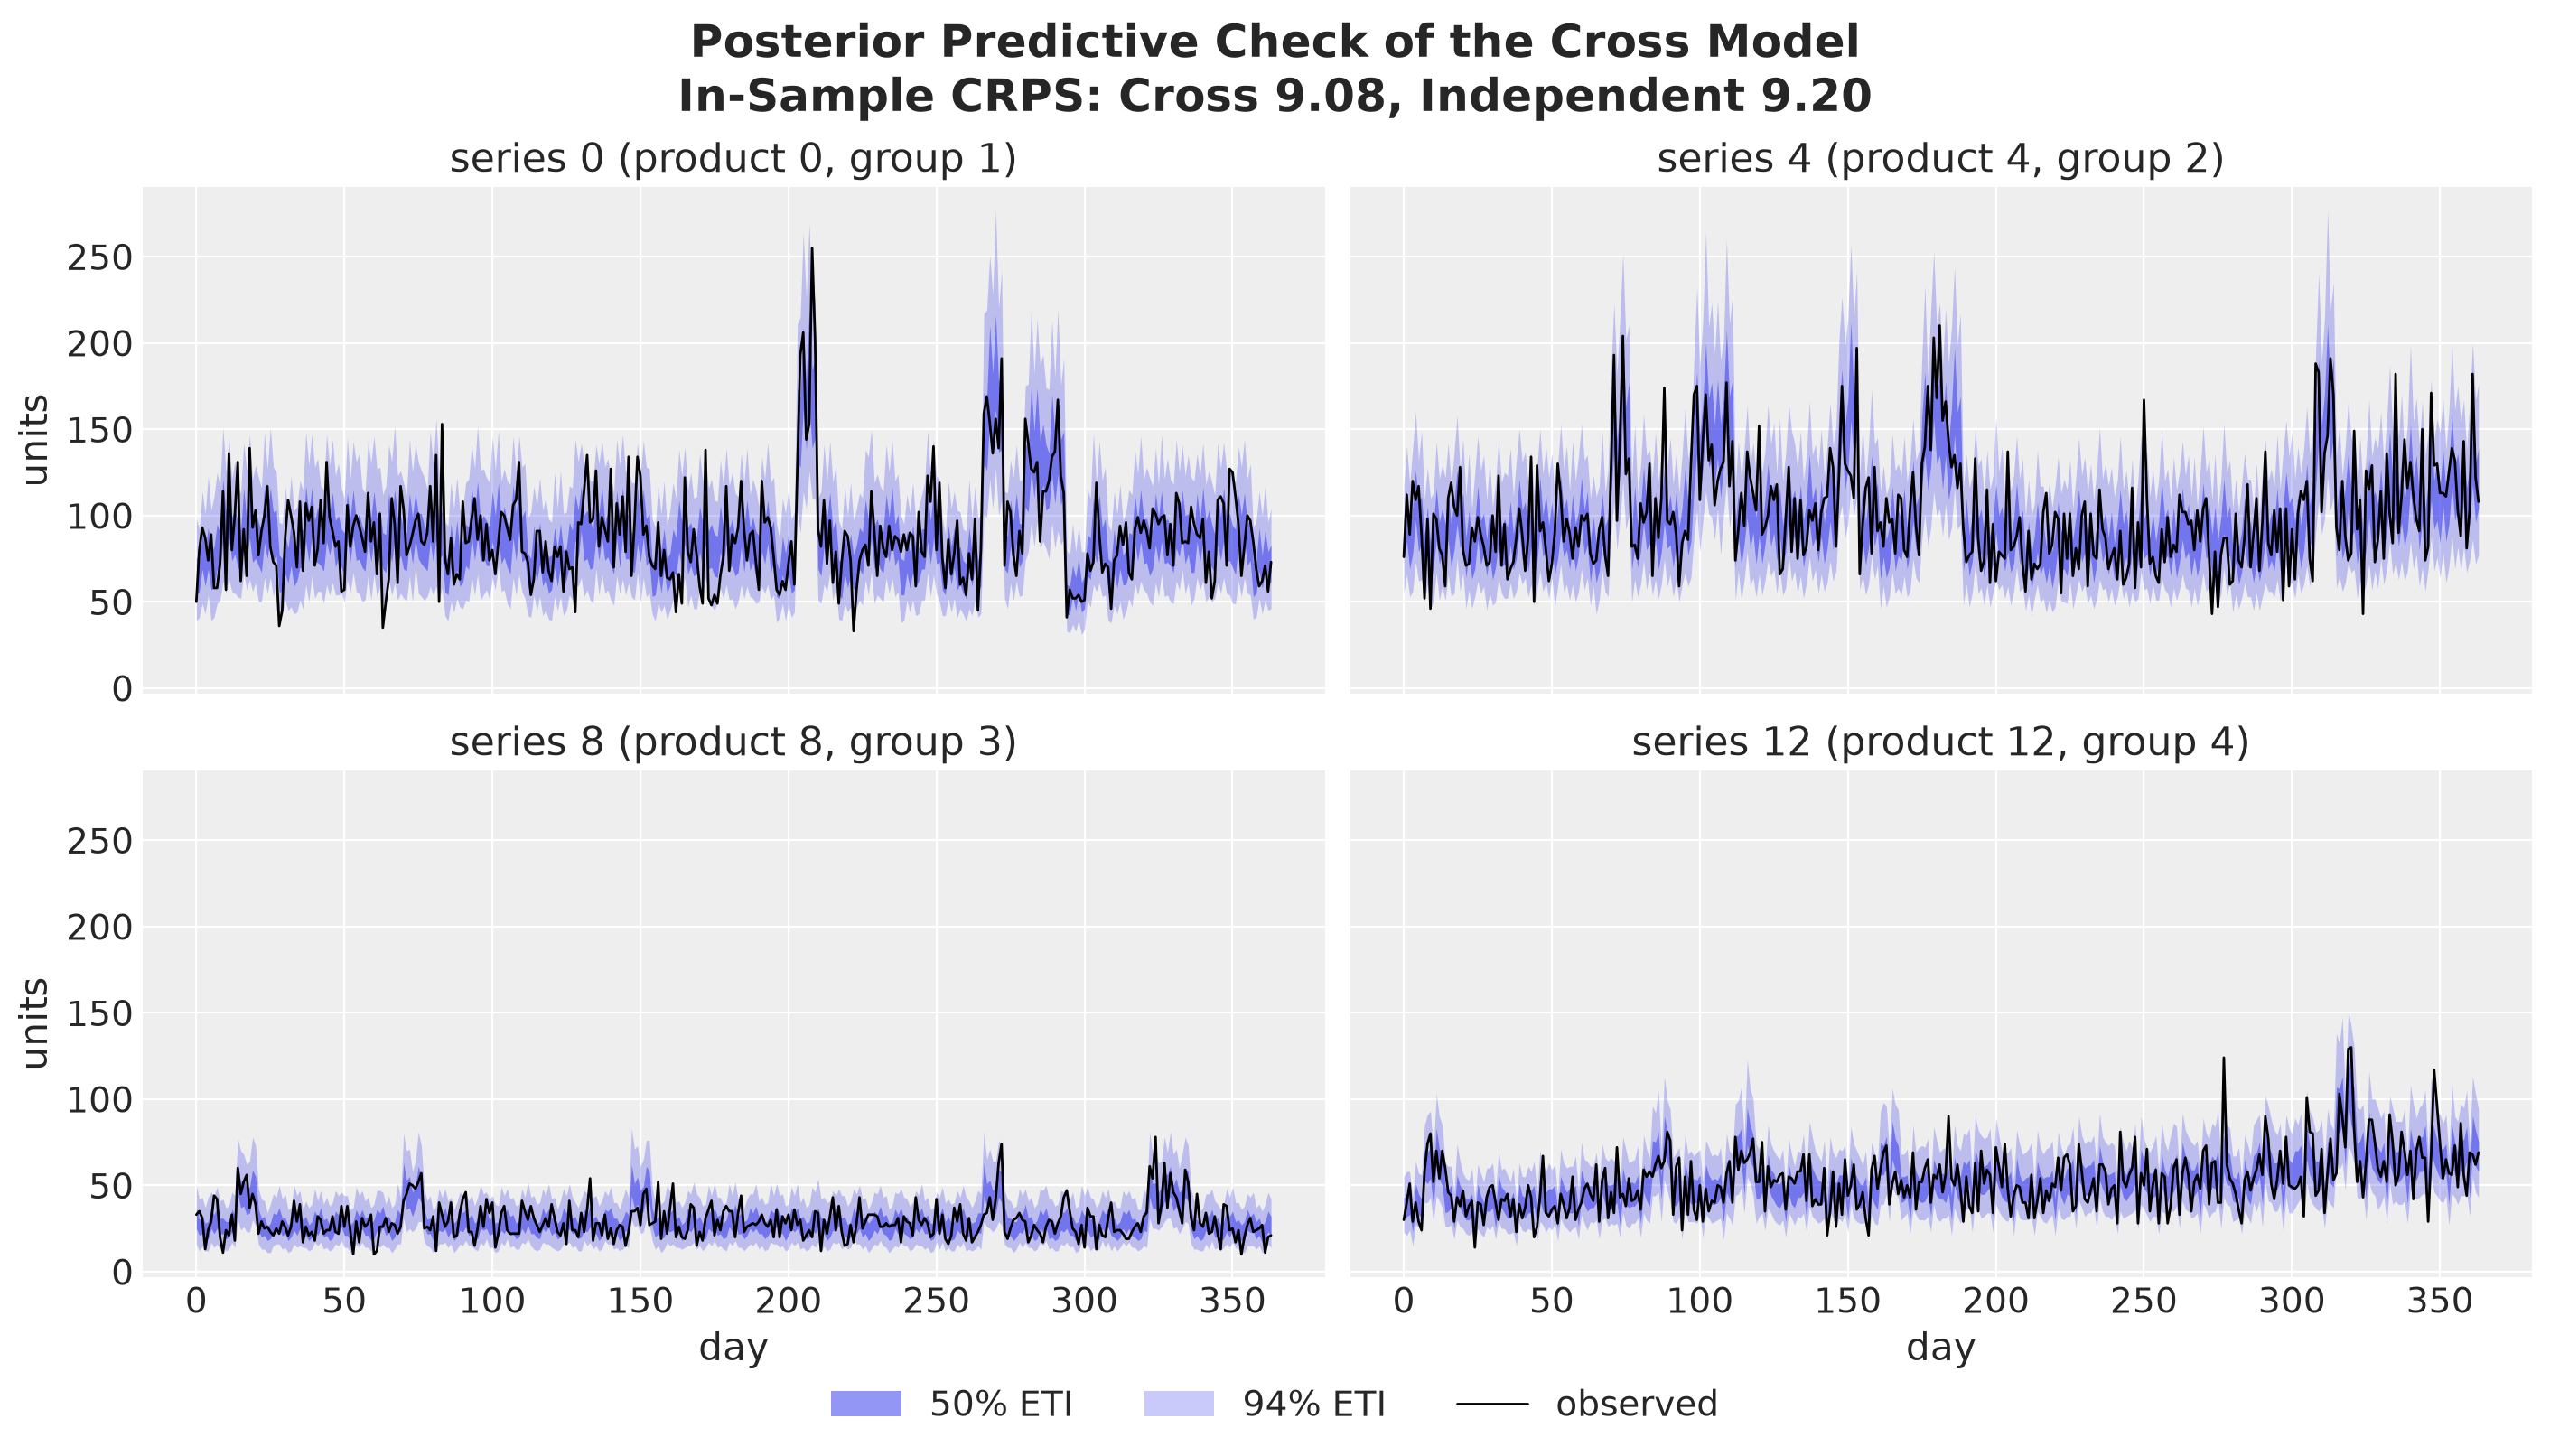

In [31]:
data_float = data.astype(jnp.float32)
ppc_obs, crps_in_sample = {}, {}
for model in models:
    rng_key, key_latent, key_ppc = random.split(rng_key, 3)
    _, sampled = latent_draws(
        key_latent, guides[model], svi_results[model], num_samples=300
    )
    ppc_obs[model] = predict_in_sample(
        key_ppc, models[model], sampled, covariates_train, batch_size=100
    ).astype(jnp.float32)
    crps_in_sample[model] = float(crps_empirical(ppc_obs[model], data_float).mean())
    # a predictive that ignores the fitted increments would fail this check
    assert 0.90 < float(eval_coverage(ppc_obs[model], data_float, alpha=CI_PROB)) < 0.98

plot_predictive_check(
    ppc_obs[Model.CROSS][..., check_series],
    "Posterior Predictive Check of the Cross Model\n"
    f"In-Sample CRPS: Cross {crps_in_sample[Model.CROSS]:.2f}, "
    f"Independent {crps_in_sample[Model.INDEPENDENT]:.2f}",
);

The bands follow the level of every series and show the bumps of the own promotion weeks, and the $94\%$ band contains almost all the observations. The in-sample CRPS is $9.08$ for the cross model and $9.20$ for the independent model.

### Forecast Calibration

The last check compares the width of the forecast of each model with the width of the evaluation scenarios. For every series and day we divide the standard deviation of the model's scenarios by the standard deviation of the evaluation scenarios. A ratio of one means that the forecast is as wide as the evaluation scenarios on a single day.

We compute the same ratio for the total demand of a series over the $15$ days, which also depends on how the days of a path move together. We also score the one realized future with the coverage of the $94\%$ interval and the CRPS.

In [32]:
sd_true = demand_eval.std(axis=0)
sd_total_true = demand_eval.sum(axis=1).std(axis=0)
width_ratio = {model: draws[model].scenarios.std(axis=0) / sd_true for model in models}
total_ratio = {
    model: draws[model].scenarios.sum(axis=1).std(axis=0) / sd_total_true
    for model in models
}
is_promo_day = promo_future.sum(axis=1) > 0

calibration = pl.DataFrame(
    [
        {
            "model": model.value,
            "sd ratio (median)": float(jnp.median(width_ratio[model])),
            "sd ratio, siblings in the promotion week": float(
                jnp.median(
                    width_ratio[model][is_promo_day][:, series_role == Role.SIBLING]
                )
            ),
            "sd ratio of the horizon total (median)": float(
                jnp.median(total_ratio[model])
            ),
            f"coverage {CI_PROB:.0%}": float(
                eval_coverage(draws[model].scenarios, demand_future_true, alpha=CI_PROB)
            ),
            "CRPS": float(
                crps_empirical(draws[model].scenarios, demand_future_true).mean()
            ),
            "share of series-days with sd ratio above 1.2": float(
                (width_ratio[model] > 1.2).mean()
            ),
        }
        for model in models
    ]
)
calibration

model,sd ratio (median),"sd ratio, siblings in the promotion week",sd ratio of the horizon total (median),coverage 94%,CRPS,share of series-days with sd ratio above 1.2
str,f64,f64,f64,f64,f64,f64
"""independent""",1.028,1.108,1.115,0.941,10.047,0.057
"""cross""",1.019,1.021,1.096,0.944,9.658,0.001


The next figure shows the distribution of the single-day ratio over the $3{,}000$ series-days of each model.

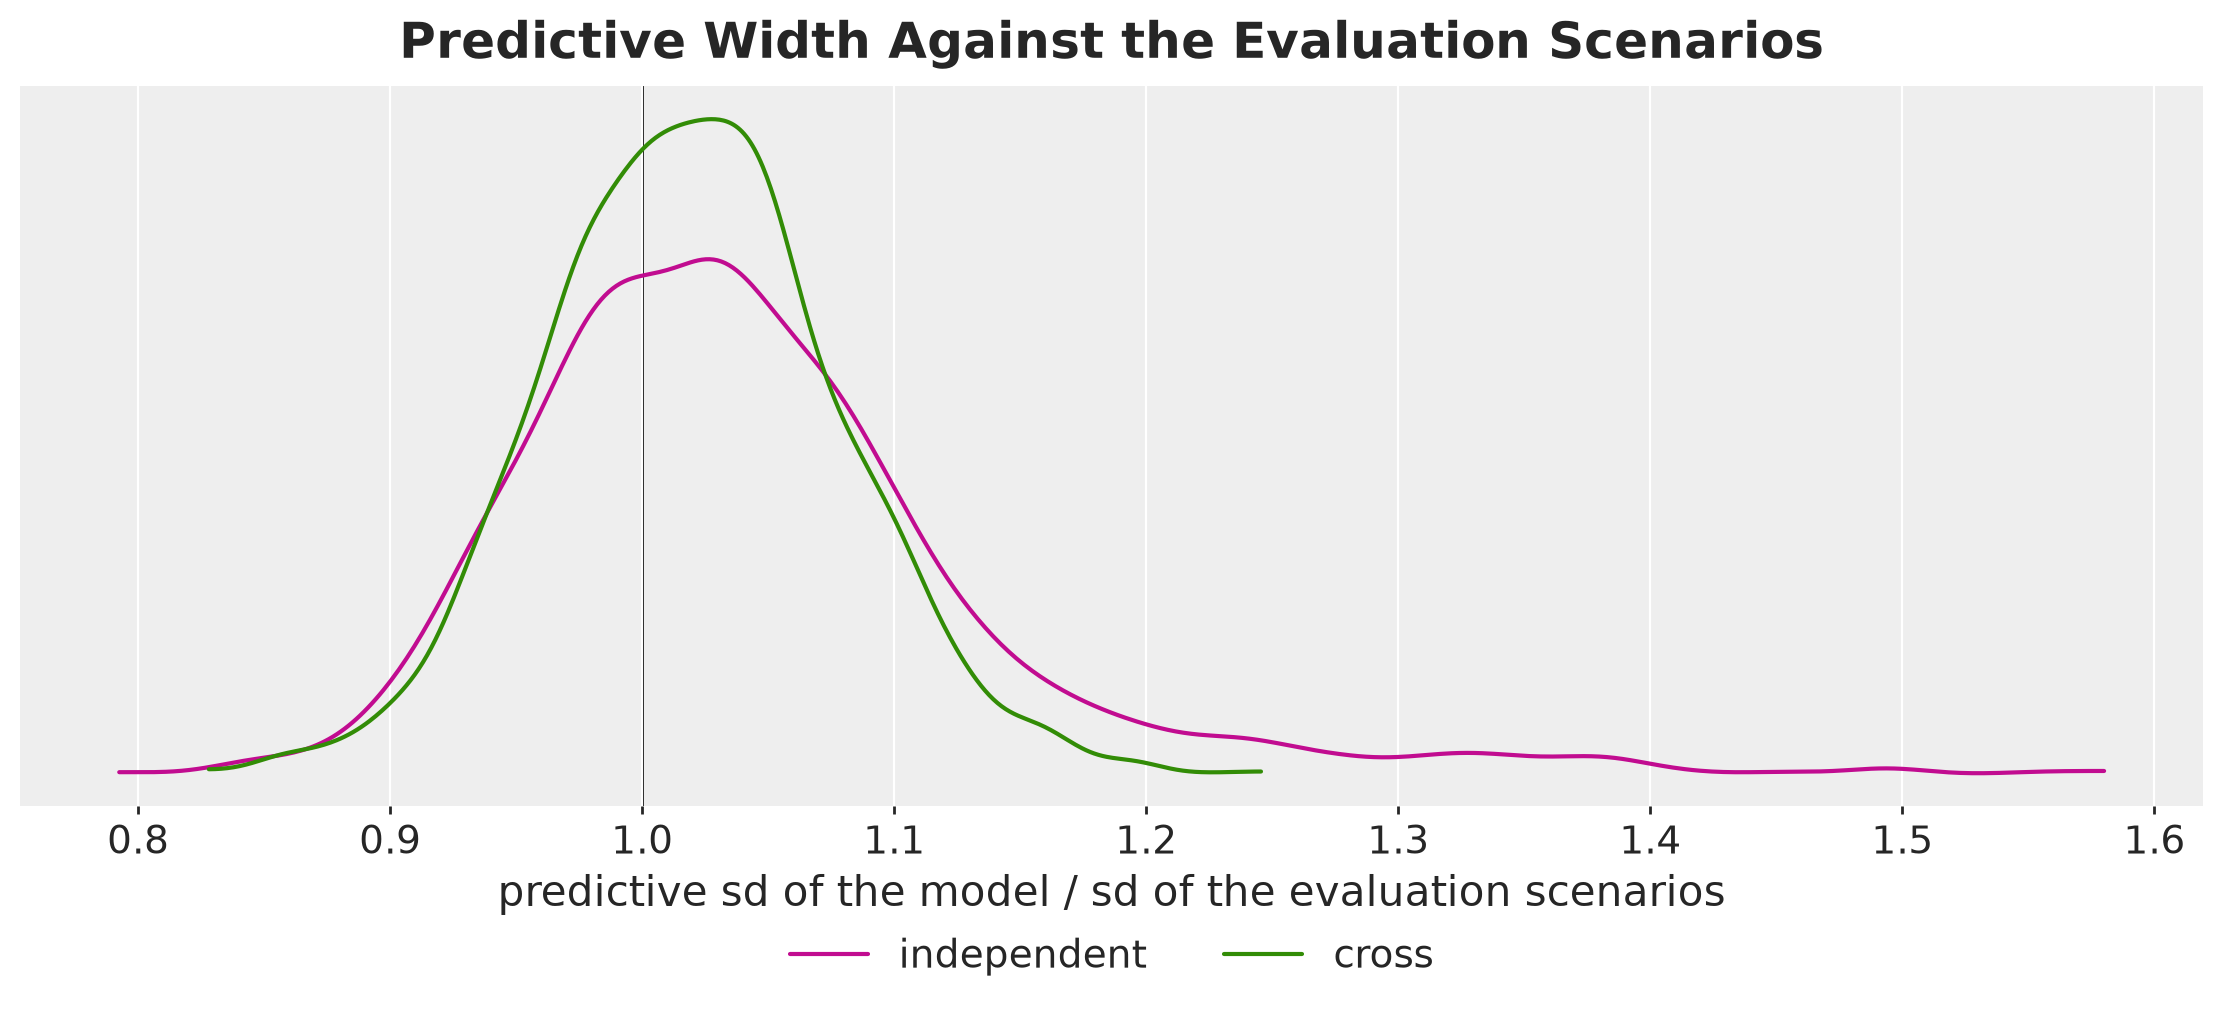

In [33]:
pc = az.plot_dist(
    {
        model: xr.Dataset({"sd ratio": (("sample",), width_ratio[model].ravel())})
        for model in models
    },
    sample_dims=["sample"],
    kind="kde",
    color=[MODEL_COLORS[model] for model in models],
    visuals={
        "point_estimate": False,
        "point_estimate_text": False,
        "credible_interval": False,
    },
    figure_kwargs={"figsize": (11, 5)},
)
az.add_lines(
    pc,
    values={"sd ratio": 1.0},
    aes_by_visuals={"ref_line": []},
    visuals={"ref_line": {"color": "black", "linestyle": "-", "linewidth": 1}},
)
ax = pc.viz["plot"]["sd ratio"].item()
ax.set(xlabel="predictive sd of the model / sd of the evaluation scenarios", title="")
pc.add_legend("model", title="", loc="outside lower center", ncol=2)
pc.viz["figure"].item().suptitle(
    "Predictive Width Against the Evaluation Scenarios", fontsize=18, fontweight="bold"
);

Both forecasts are about as wide as the evaluation scenarios on a single day, with a median ratio of $1.02$ for the cross model and $1.03$ for the independent model. Both cover the realized future at about $94\%$, and their CRPS are $9.66$ and $10.05$ units.

On the total demand of a series over the horizon both forecasts are wider than the evaluation scenarios, at $1.10$ and $1.12$. The evaluation scenarios condition on the true level of every series, which a model has to estimate, so a ratio above one is expected.

The independent model stands out on the siblings in the promotion week. Its forecast is $11\%$ wider than the evaluation scenarios there, against $2\%$ for the cross model, and $6\%$ of its series-days have a ratio above $1.2$, against $0.1\%$. This is consistent with its higher mean forecast for these series and its lower concentration, since both widen a negative binomial.

Next, we turn the forecasts into scenarios and plans.

## Demand Scenarios

We now have three sets of demand paths, each of shape `(scenarios, days, series)`.

- **Independent model.** Its $1{,}000$ forecast draws are the **optimization scenarios** of the plans built on it.
- **Cross model.** Its $1{,}000$ forecast draws are the optimization scenarios of the plans built on it.
- **True process.** Its $3{,}000$ draws are the evaluation scenarios, on which we score every plan.

The capacity of each store is a multiple $\kappa$ of its **regular throughput**, which we take as the median of its total daily demand over the last eight weeks of the history. The chain knows this number, and one promotion week does not move it much. We start with $\kappa = 1.05$ and sweep it in the *Capacity Sensitivity* section.

The initial stock of every series is its mean daily demand over the last four weeks of the history.

To see how tight this capacity is, we compute the mean demand of the evaluation scenarios as a share of the capacity, for each store and each period of the horizon. We split the horizon into three **periods**, the first week, the promotion week and the last day.

In [34]:
class Period(StrEnum):
    """Parts of the horizon."""

    FIRST_WEEK = "first week"
    PROMOTION_WEEK = "promotion week"
    LAST_DAY = "last day"


PERIODS = {
    Period.FIRST_WEEK: slice(0, setup.promo_start),
    Period.PROMOTION_WEEK: slice(setup.promo_start, setup.promo_end),
    Period.LAST_DAY: slice(setup.promo_end, setup.horizon),
}


def flat(
    orders: Float[Array, "horizon n_stores n_products"],
) -> Float[Array, "horizon n_series"]:
    """Reshape a plan from (day, store, product) to (day, series)."""
    return orders.reshape(setup.horizon, setup.n_series)


def unflat(
    orders: Float[Array, "horizon n_series"],
) -> Float[Array, "horizon n_stores n_products"]:
    """Reshape a plan from (day, series) to (day, store, product)."""
    return orders.reshape(setup.horizon, setup.n_stores, setup.n_products)


data_by_store = data.astype(jnp.float32).reshape(
    setup.t_obs, setup.n_stores, setup.n_products
)
regular_throughput = jnp.median(
    data_by_store[-setup.capacity_window :].sum(axis=-1), axis=0
)
capacity = setup.capacity_multiple * regular_throughput
initial_inventory = data[-setup.stock_window :].astype(jnp.float32).mean(axis=0)
mean_demand = {model: draws[model].scenarios.mean(axis=0) for model in models}

# mean demand of the true process over the capacity: (horizon, n_stores)
capacity_load = unflat(demand_eval.mean(axis=0)).sum(axis=-1) / capacity
pl.DataFrame(
    [
        {
            "period": period.value,
            "mean over the stores": float(capacity_load[days_slice].mean()),
            "lowest store": float(capacity_load[days_slice].mean(axis=0).min()),
            "highest store": float(capacity_load[days_slice].mean(axis=0).max()),
        }
        for period, days_slice in PERIODS.items()
    ]
)

period,mean over the stores,lowest store,highest store
str,f64,f64,f64
"""first week""",0.910,0.885,0.947
"""promotion week""",0.975,0.935,1.031
"""last day""",0.938,0.914,0.982


In the first week the mean demand takes about $91\%$ of the capacity. In the promotion week it takes $97.5\%$ on average, and $103\%$ in the tightest store.

The plans order more than the mean demand, because they hold a buffer against lost sales. With that buffer, a load of $91\%$ leaves room and a load of $97.5\%$ does not.

Note that this share depends on which products are promoted, so the same $\kappa$ can be tighter or looser on another panel.

The next figure shows the forecasts of both models for the four products of group $1$ in store $1$, next to the last four weeks of history and the realized future.

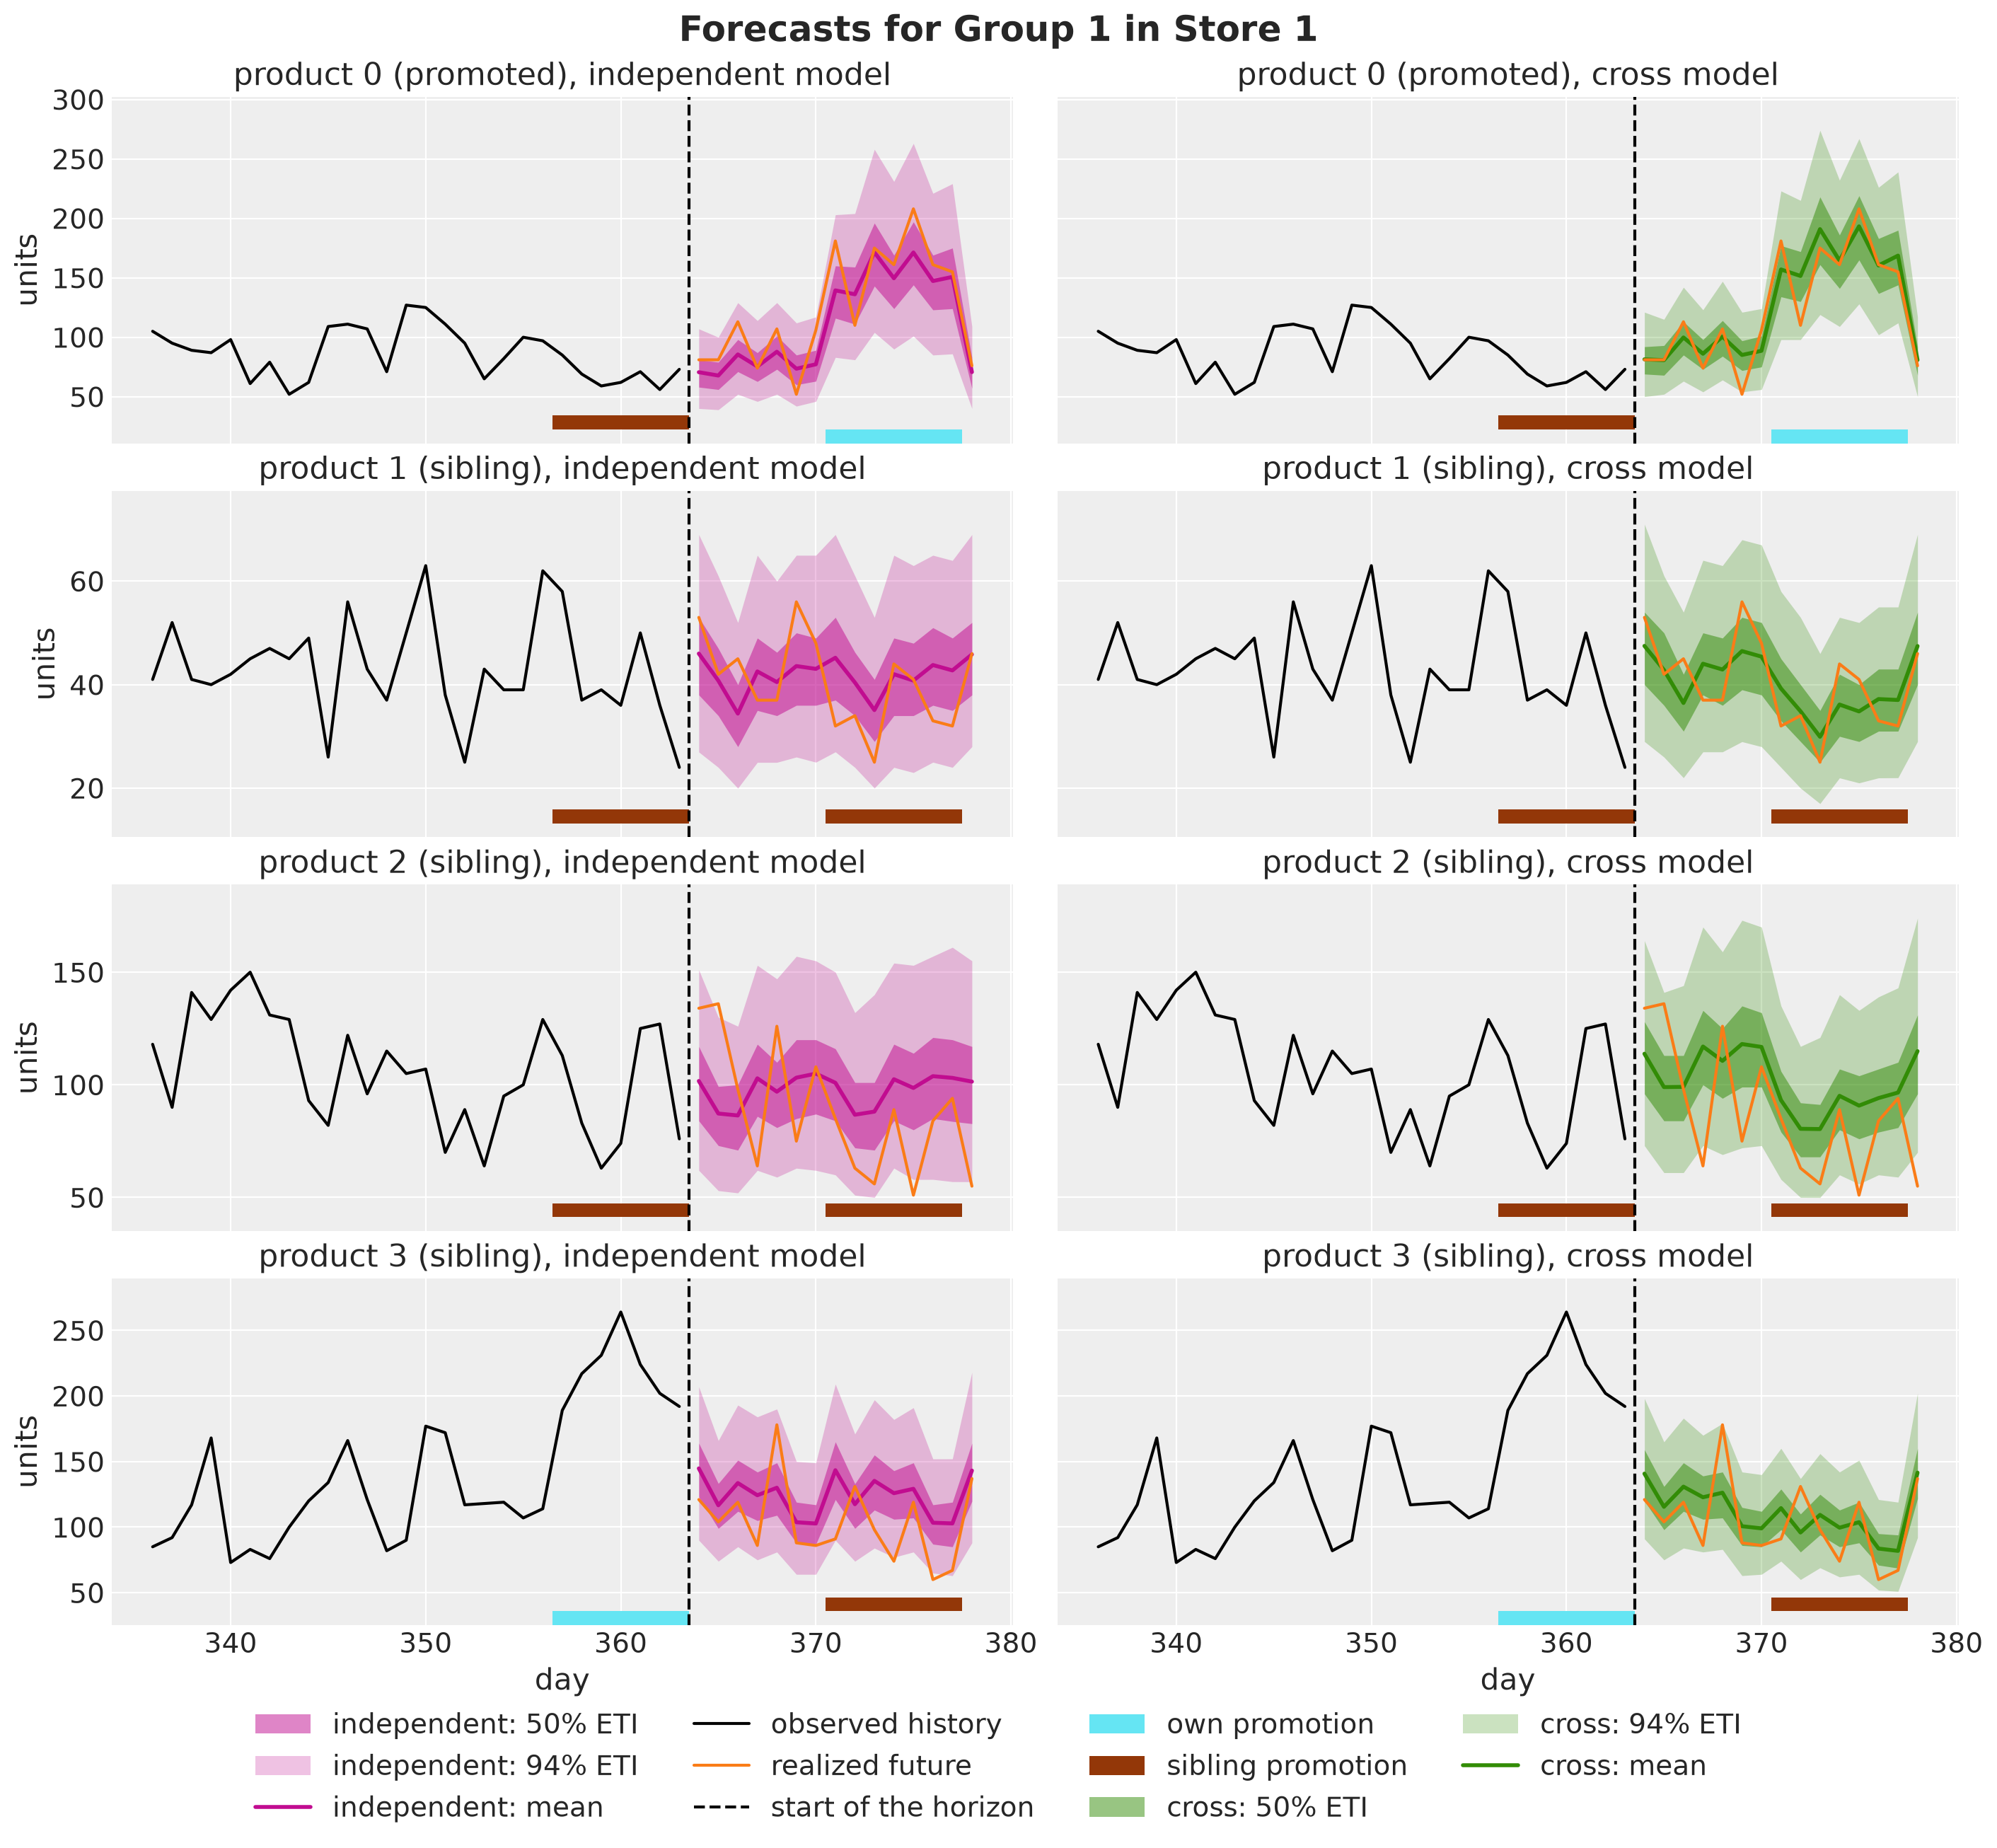

In [35]:
def plot_group_forecast(store: int, group: int, start: int = setup.t_obs - 28) -> None:
    """Forecasts of both models for the four products of a group in a store."""
    group_products = np.flatnonzero(panel.product_to_group == group)
    series = store * setup.n_products + group_products
    labels = [f"product {j} ({product_role[j]})" for j in group_products]
    shape = (len(series), len(models), setup.horizon)
    tree = az.from_dict(
        {
            # dims after chain and draw: (series, model, time)
            "posterior_predictive": {
                "obs": jnp.stack(
                    [draws[model].scenarios[..., series] for model in models], axis=-1
                )[None].transpose(0, 1, 3, 4, 2)
            },
            # `plot_lm` sorts these two in place, so they are numpy arrays
            "observed_data": {
                "obs": np.broadcast_to(
                    demand_future_true[:, series].T[:, None, :], shape
                ).copy()
            },
            "constant_data": {
                "day": np.broadcast_to(days_future.astype(float), shape).copy()
            },
        },
        coords={
            "series": labels,
            "model": [model.value for model in models],
            "time": days_future,
        },
        dims={"obs": ["series", "model", "time"], "day": ["series", "model", "time"]},
    )
    pc = az.plot_lm(
        tree,
        x="day",
        y="obs",
        y_obs="obs",
        plot_dim="time",
        smooth=False,
        ci_prob=(0.5, CI_PROB),
        point_estimate="mean",
        visuals={
            "pe_line": {"alpha": 1.0, "linewidth": 2},
            "observed_scatter": False,
            "xlabel": False,
            "ylabel": False,
        },
        cols=["series", "model"],
        col_wrap=len(models),
        aes={"color": ["model"]},
        aes_by_visuals={"pe_line": ["color"]},
        color=[MODEL_COLORS[model] for model in models],
        figure_kwargs={"figsize": (14, 13), "sharex": True, "sharey": "row"},
    )
    lighten_bands(pc, "day", prob_alpha=((0.5, 0.5), (CI_PROB, 0.25)))
    legend = {}
    for row, (label, i) in enumerate(zip(labels, series, strict=True)):
        for col, model in enumerate(models):
            where = {"series": label, "model": model.value}
            bands = pc.viz["ci_band"]["day"].sel(where)
            bands.sel(prob=0.5).item().set_label(f"{model}: 50% ETI")
            bands.sel(prob=CI_PROB).item().set_label(f"{model}: {CI_PROB:.0%} ETI")
            pc.viz["pe_line"]["day"].sel(where).item().set_label(f"{model}: mean")
            ax = pc.get_target("day", where)
            plot_demand(ax, int(i), start)
            ax.set(
                title=f"{label}, {model} model",
                xlabel="day" if row == len(labels) - 1 else "",
                ylabel="units" if col == 0 else "",
            )
            handles, names = ax.get_legend_handles_labels()
            legend |= dict(zip(names, handles, strict=True))
    fig = pc.viz["figure"].item()
    fig.legend(legend.values(), legend.keys(), loc="outside lower center", ncol=4)
    fig.suptitle(
        f"Forecasts for Group {group + 1} in Store {store + 1}",
        fontsize=18,
        fontweight="bold",
    )


plot_group_forecast(store=0, group=0);

On the promoted product both forecasts jump in the promotion week, and the independent model is lower throughout. On the three siblings the two models part in the promotion week, where the cross model dips and the independent model stays close to flat. The realized future, one noisy path, dips with the cross model.

The models also part in the first week, where no promotion happens. On products $0$, $1$ and $2$ the cross model starts above the independent model. The last week of the history was a sibling promotion week for these three products, so their demand dipped there.

The cross model attributes the dip to the price of product $3$ and expects the recovery. The independent model has no such term, and its lower start is consistent with a level that followed the dip down. We check this below.

Product $3$ shows the other case. It was on promotion itself in that week and no sibling was, and the two forecasts start at the same level.

Next, we draw the same figure for group $3$, which is promoted but has no cannibalization.

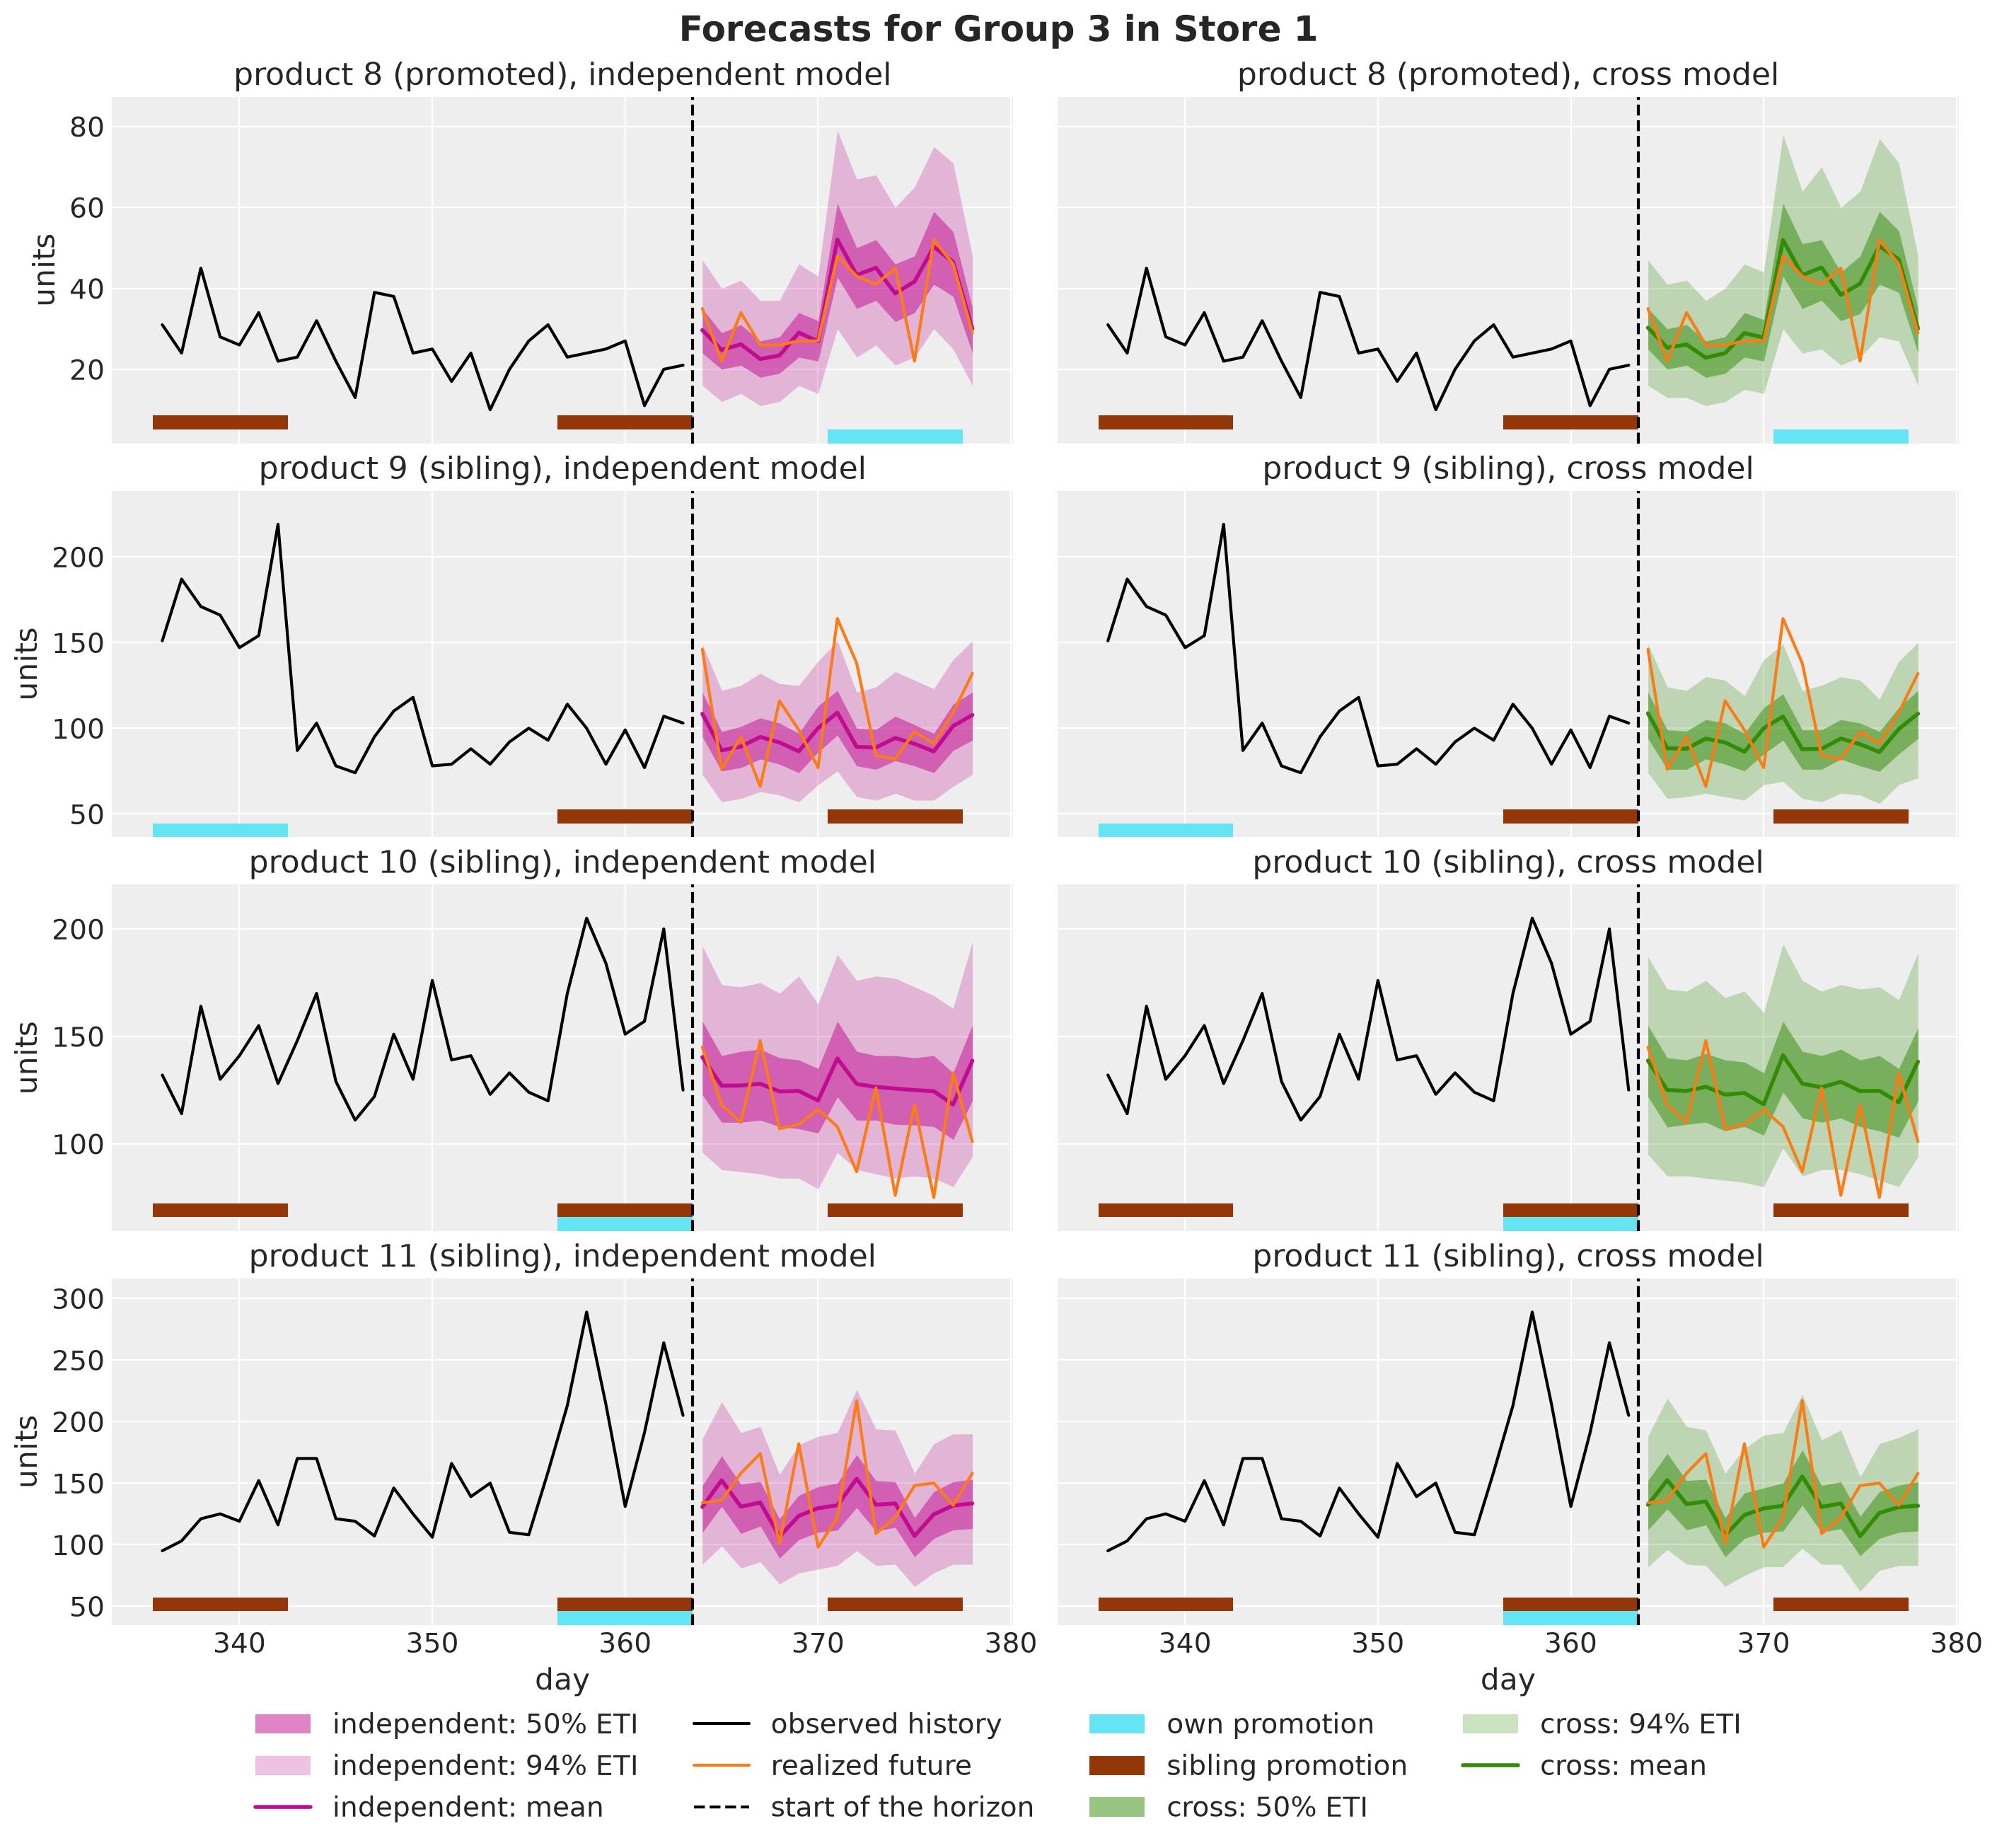

In [36]:
plot_group_forecast(store=0, group=2);

The two forecasts agree on every product, including the three siblings in the promotion week. The cross model does not invent a dip where the data show none, which is good!

Observe that the first week of the horizon has no promotion, so any difference between the two models in that week comes from the history. To see it for every series, we divide the mean forecast over the first week by the mean of the evaluation scenarios over the same week. A ratio of one means that the forecast starts at the level of the evaluation scenarios.

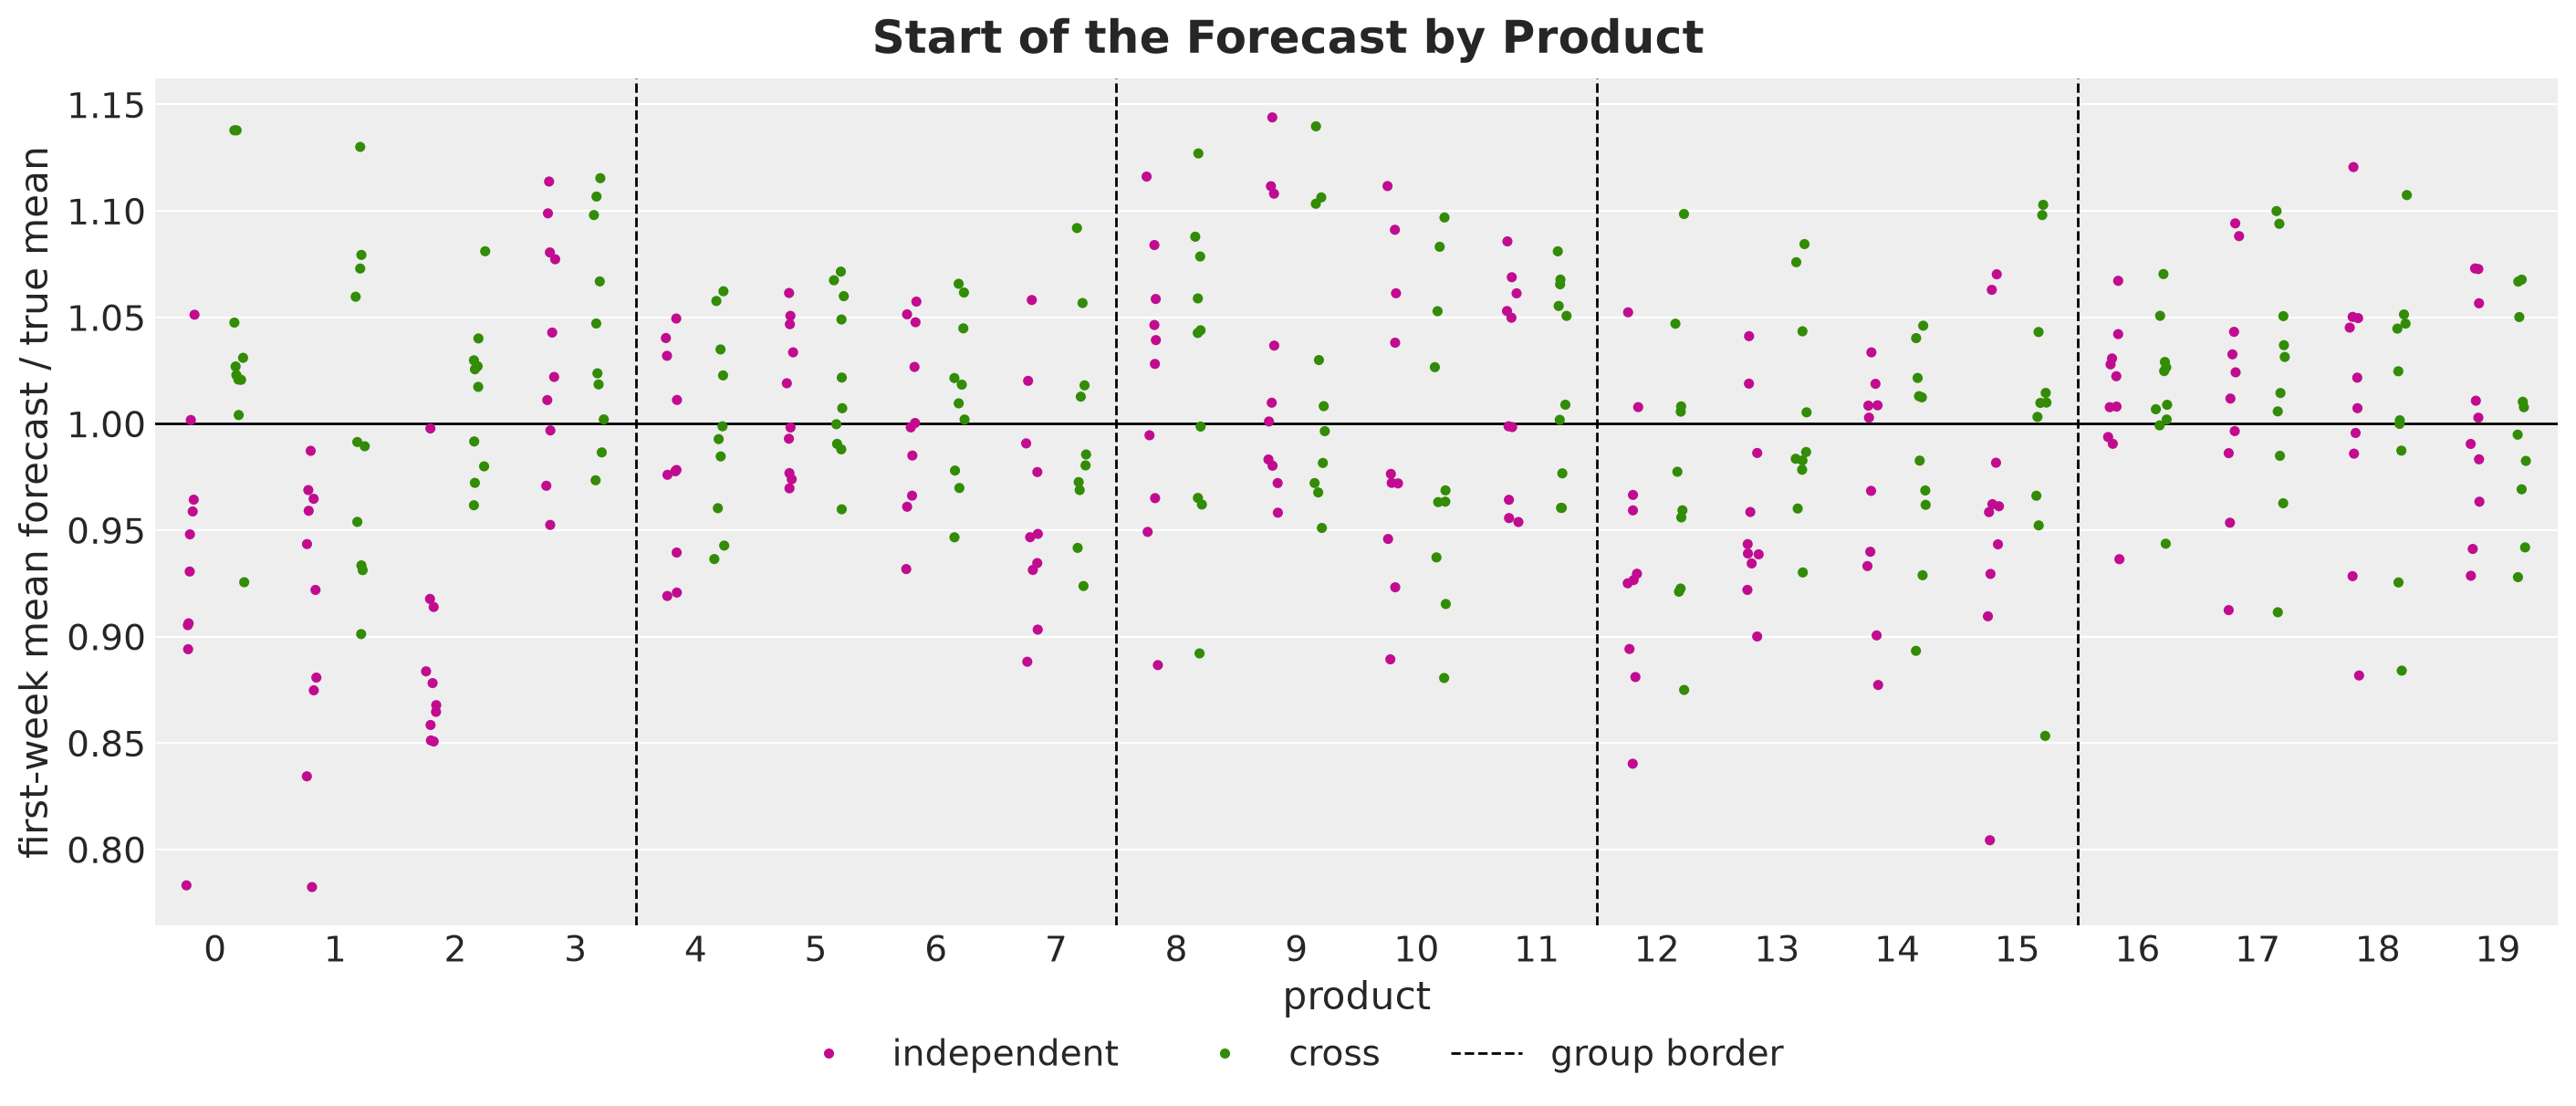

In [37]:
first_week = PERIODS[Period.FIRST_WEEK]
truth_start = demand_eval[:, first_week].mean(axis=(0, 1))
start_ratio = pl.DataFrame(
    {
        "product": np.tile(panel.series_to_product, len(models)),
        "model": np.repeat([model.value for model in models], setup.n_series),
        "ratio": np.concatenate(
            [
                draws[model].scenarios[:, first_week].mean(axis=(0, 1)) / truth_start
                for model in models
            ]
        ),
    }
)

fig, ax = plt.subplots(figsize=(14, 6))
sns.stripplot(
    data=start_ratio,
    x="product",
    y="ratio",
    hue="model",
    hue_order=[model.value for model in models],
    palette=MODEL_COLORS,
    dodge=True,
    size=4,
    ax=ax,
)
ax.axhline(1.0, color="black", linewidth=1)
for group in range(1, setup.n_groups):
    ax.axvline(
        group * setup.n_per_group - 0.5,
        color="black",
        linestyle="--",
        linewidth=1,
        label="group border" if group == 1 else None,
    )
ax.get_legend().remove()
ax.set(xlabel="product", ylabel="first-week mean forecast / true mean")
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Start of the Forecast by Product", fontsize=18, fontweight="bold");

Each point is one series, that is, one store of the product on the horizontal axis.

- **Group $1$.** Under the independent model, products $0$, $1$ and $2$ start below the truth in almost every store, and under the cross model they start around it. Product $3$ starts at the same place under both models.
- **Groups $2$ and $4$.** The independent model starts lower than the cross model on some products and at the same place on the others.
- **Groups $3$ and $5$.** The two models agree on every product.

The spread across the stores of a product is similar under both models. It is consistent with the error of the level that we saw in the *Parameter Recovery* section.

Here is the mechanism we propose. A random walk level follows the recent demand. When a sibling was on promotion in the last weeks of the history, the demand of a product was lower in those weeks, and a model without a cross-price term reads that as a lower level.

To check this, let $\tau$ be a **time constant** in days and let $w_t \propto \exp(-(T - t) / \tau)$ be weights over the days $t = 1, \dots, T$ of the history that sum to one and favor the last days. We define the **recent sibling exposure** of product $j$ as the weighted mean of the log price cuts of its siblings,

$$
e_j = \sum_{t=1}^{T} w_t \sum_{k \in g(j), \, k \neq j} (-x_{t,k}).
$$

The cross elasticity is constant within a group. Let $c_j$ be the cross elasticity of the group of product $j$. So on a weighted average the sibling promotions took $c_j \, e_j$ from the log demand of product $j$.

We compare this quantity with the **level gap** of the product, the posterior mean of the level at the end of the history under the independent model minus the same quantity under the cross model, averaged over the stores. If the level of the independent model absorbs the recent dips, the level gap is close to $-c_j \, e_j$.

The time constant stands for the memory of the level, which we do not estimate. The following table tries three values. For each one it gives the correlation between the level gap and $c_j \, e_j$ and the slope of the least squares line, over the $12$ products with a positive cross elasticity.

In [38]:
def recent_sibling_exposure(time_constant: float) -> Float[Array, " n_products"]:
    """Log price cuts of the siblings of each product, weighted toward the last days."""
    sibling_cut = -(log_price[: setup.t_obs] @ jnp.asarray(is_sibling, dtype=float))
    weights = jnp.exp(-jnp.arange(setup.t_obs)[::-1] / time_constant)
    return (weights / weights.sum()) @ sibling_cut


product_cross = jnp.asarray(group_cross[panel.product_to_group])
has_cross = group_cross[panel.product_to_group] > 0
level_gap = (
    (draws[Model.INDEPENDENT].level_end - draws[Model.CROSS].level_end)
    .mean(axis=0)
    .reshape(setup.n_stores, setup.n_products)
    .mean(axis=0)
)


def exposure_fit(time_constant: int) -> dict[str, int | float]:
    """Correlation and slope of the level gap against the expected sibling dip."""
    expected_dip = product_cross * recent_sibling_exposure(float(time_constant))
    return {
        "time constant (days)": time_constant,
        "correlation": float(
            jnp.corrcoef(expected_dip[has_cross], level_gap[has_cross])[0, 1]
        ),
        "slope": float(
            jnp.polyfit(expected_dip[has_cross], level_gap[has_cross], 1)[0]
        ),
    }


pl.DataFrame([exposure_fit(time_constant) for time_constant in (10, 20, 30)])

time constant (days),correlation,slope
i64,f64,f64
10,-0.973,-0.960
20,-0.951,-1.450
30,-0.957,-1.598


The correlation is below $-0.95$ for the three values, so on this panel the level gap is strongly correlated with the recent sibling promotions. The slope depends on the time constant and runs from $-0.96$ to $-1.60$.

We use $\tau = 10$ days from here on, the value of the three whose slope is closest to $-1$. The following table lists, for the $20$ products, the exposure, the expected level gap $-c_j \, e_j$ and the level gap.

In [39]:
exposure = recent_sibling_exposure(time_constant=10.0)
origin = pl.DataFrame(
    {
        "product": range(setup.n_products),
        "cross elasticity": group_cross[panel.product_to_group].tolist(),
        "recent sibling exposure": exposure.tolist(),
        "expected level gap": (0.0 - product_cross * exposure).tolist(),
        "level gap": level_gap.tolist(),
    }
)
origin

product,cross elasticity,recent sibling exposure,expected level gap,level gap
i64,f64,f64,f64,f64
0,0.600,0.182,-0.109,-0.107
1,0.600,0.182,-0.109,-0.099
2,0.600,0.182,-0.109,-0.133
3,0.600,0.001,-0.000,-0.008
4,0.300,0.050,-0.015,-0.014
5,0.300,0.046,-0.014,-0.011
6,0.300,0.007,-0.002,-0.009
7,0.300,0.051,-0.015,-0.035
8,0.000,0.381,0.000,-0.006


Next, we plot the level gap against the exposure. The three lines have slopes $-0.6$, $-0.3$ and $0$, which is where the points of each group lie if the level absorbs the recent dips.

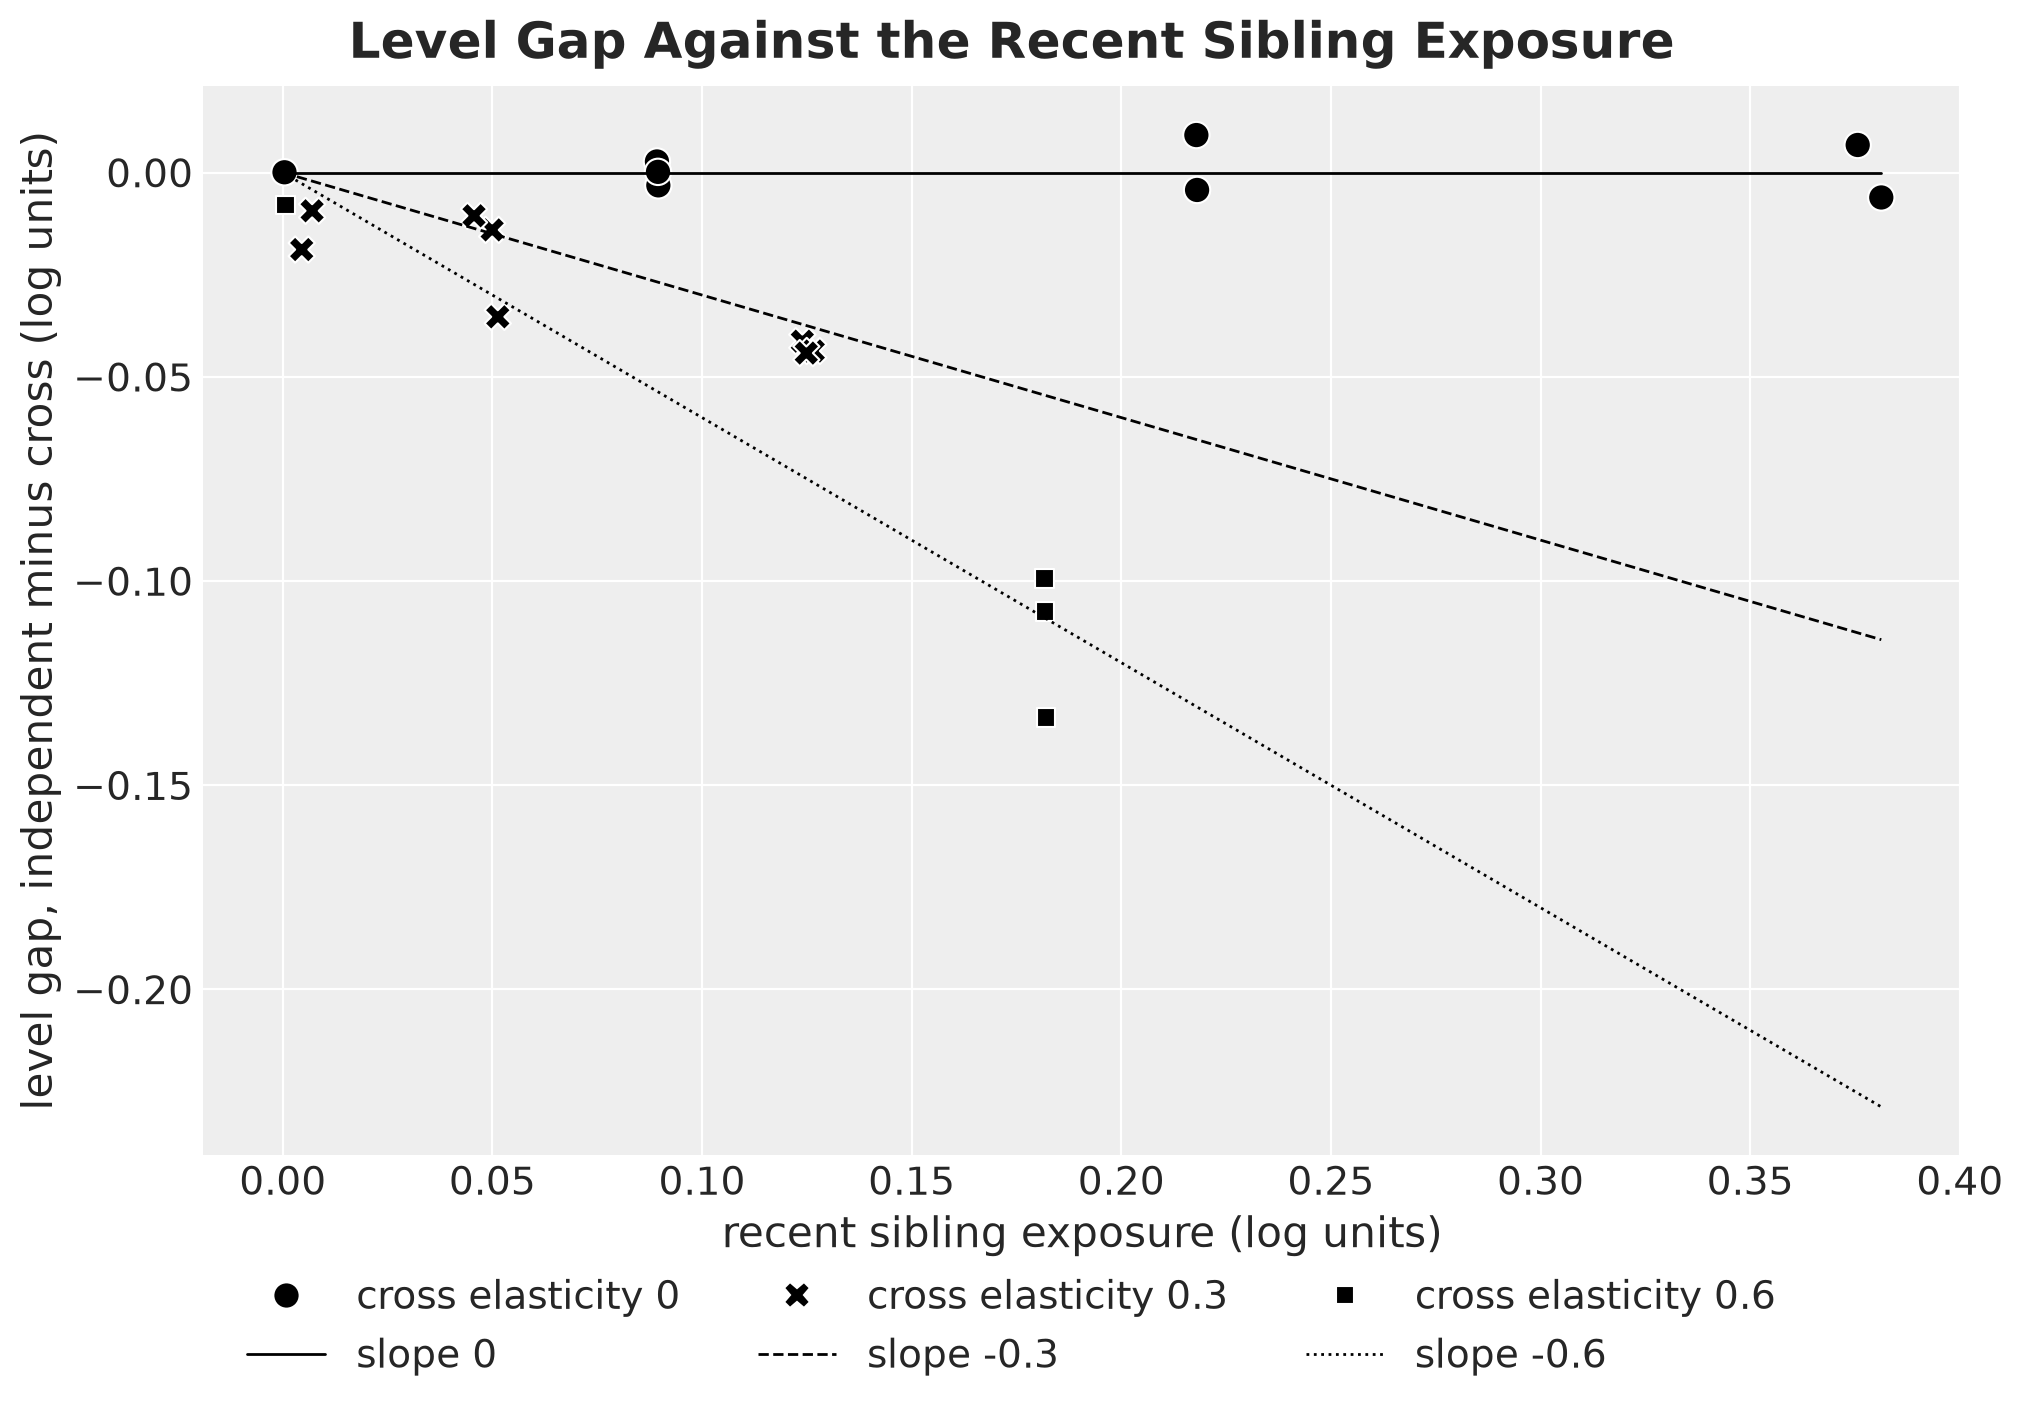

In [40]:
levels = sorted(set(setup.group_cross))

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=origin,
    x="recent sibling exposure",
    y="level gap",
    style="cross elasticity",
    style_order=levels,
    color="black",
    s=90,
    ax=ax,
)
markers, _ = ax.get_legend_handles_labels()
ax.get_legend().remove()
for marker, value in zip(markers, levels, strict=True):
    marker.set_label(f"cross elasticity {value:g}")
lines = [
    ax.plot(
        [0.0, float(exposure.max())],
        [0.0, -value * float(exposure.max())],
        color="black",
        linestyle=linestyle,
        linewidth=1,
        label=f"slope {0.0 - value:g}",
    )[0]
    for value, linestyle in zip(levels, ["-", "--", ":"], strict=True)
]
ax.set(
    xlabel="recent sibling exposure (log units)",
    ylabel="level gap, independent minus cross (log units)",
)
# one column per cross elasticity: its marker above its reference line
fig.legend(
    handles=[handle for pair in zip(markers, lines, strict=True) for handle in pair],
    loc="outside lower center",
    ncol=len(levels),
)
fig.suptitle(
    "Level Gap Against the Recent Sibling Exposure", fontsize=18, fontweight="bold"
);

The points of each group lie on or near the line of their cross elasticity.

- **Cross elasticity of $0.6$.** Products $0$, $1$ and $2$ have an exposure of $0.18$, because product $3$ was on promotion in the last week of the history. Their level gaps are between $-0.10$ and $-0.13$, against an expected $-0.11$. Product $3$ has the same cross elasticity and almost no recent exposure, and its level gap is close to zero.
- **Cross elasticity of $0.3$.** The products of groups $2$ and $4$ have smaller gaps, close to or below the middle line. Products $7$ and $14$ are the furthest below it.
- **No cross elasticity.** The products of groups $3$ and $5$ have a level gap within $0.01$ of zero at every exposure. Products $8$ to $11$ had one or two siblings on promotion in the last week too, with an exposure at least as large as that of products $0$, $1$ and $2$, and the two models agree on them.

So on this panel the bias of the independent model follows the promotion calendar of the last weeks of the history and the size of the cross elasticity. With another calendar, other products would start low. In the *Out of Sample Evaluation* section we see what this costs under an asymmetric loss.

## Inventory Simulator

We reuse the simulator of the first post, with the initial stock as an argument because it differs across series. The loss of a scenario is the sum over the series, and we keep the stock and lost sales paths per series to split the loss by product later.

In [41]:
class Simulation(NamedTuple):
    """Loss, stock path and lost sales path of a plan against demand paths."""

    loss: Float[Array, "*batch"]
    inventory: Float[Array, "*batch horizon"]
    lost_sales: Float[Array, "*batch horizon"]


def simulate(
    orders: Float[Array, " horizon"],
    demand: Float[Array, " horizon"],
    initial_inventory: ScalarLike,
    config: InventoryConfig,
) -> Simulation:
    """Run the inventory dynamics of one plan against one demand path."""

    def step(
        inventory: ScalarLike, inputs: tuple[ScalarLike, ScalarLike]
    ) -> tuple[ScalarLike, tuple[ScalarLike, ScalarLike, ScalarLike]]:
        order_t, demand_t = inputs
        available = inventory + order_t  # y_t
        sales_t = jnp.minimum(available, demand_t)
        lost_t = demand_t - sales_t
        inventory = available - sales_t
        cost_t = config.holding_cost * inventory + config.lost_sales_cost * lost_t
        return inventory, (inventory, lost_t, cost_t)

    _, (inventory_path, lost_path, cost_path) = jax.lax.scan(
        step, jnp.asarray(initial_inventory, dtype=orders.dtype), (orders, demand)
    )
    return Simulation(cost_path.sum(), inventory_path, lost_path)


# one plan (horizon, n_series) against one demand path (horizon, n_series): the
# results of every series, with the paths of shape (n_series, horizon)
simulate_series = jax.vmap(simulate, in_axes=(1, 1, 0, None))
# one plan against a batch of demand paths (scenarios, horizon, n_series)
simulate_scenarios = jax.jit(
    jax.vmap(simulate_series, in_axes=(None, 0, None, None)), static_argnames="config"
)

The **mean forecast plan** of a model orders, day by day, the mean demand that the stock on hand does not cover. We project the orders of every day onto the capacity set of the store before we carry the stock forward. We build one such plan per model.

In [42]:
def forward_pass_capacity(
    demand_path: Float[Array, "horizon n_stores n_products"],
    capacity: Float[Array, " n_stores"],
    initial_inventory: Float[Array, "n_stores n_products"],
) -> Float[Array, "horizon n_stores n_products"]:
    """Orders that follow one demand path: the projected shortfall of every day."""

    def step(
        inventory: Float[Array, "n_stores n_products"],
        demand_t: Float[Array, "n_stores n_products"],
    ) -> tuple[
        Float[Array, "n_stores n_products"], Float[Array, "n_stores n_products"]
    ]:
        shortfall = demand_t - inventory
        order_t = project_day(shortfall, capacity)
        inventory = jnp.maximum(inventory + order_t - demand_t, 0.0)
        return inventory, order_t

    _, orders = jax.lax.scan(step, initial_inventory, demand_path)
    return orders


initial_inventory_by_store = initial_inventory.reshape(setup.n_stores, setup.n_products)
orders_mean = {
    model: forward_pass_capacity(
        unflat(mean_demand[model]), capacity, initial_inventory_by_store
    )
    for model in models
}

## Decision Plans

We minimize the objective of the first post, the expected loss plus a **tail weight** $\lambda$ times its conditional value at risk (CVaR), the mean of the worst $5\%$ of the scenario losses. We sum the loss over the series before we take the mean and the tail.

Recall that with $N$ scenarios we approximate the expected loss by the sample average $\frac{1}{N} \sum_{n=1}^{N} L(a, D^{(n)})$, where $D^{(n)}$ is the $n$-th scenario. This is the sample average approximation of [Shapiro, Dentcheva and Ruszczyński (2021)](https://doi.org/10.1137/1.9781611976595).

The solver is projected Adam, written with [Optax](https://optax.readthedocs.io/), with `project_orders` in place of the clip at zero after every step. The iterates stay in the capacity set of every store and day. The `SolverConfig` tuple holds the settings of the solver, the tail probability of the CVaR and a numerical tolerance.

We solve the **expected cost plan** ($\lambda = 0$) on the scenarios of each model, starting from the mean forecast plan of that model.

We leave out the chance-constrained plan and the cross check against a linear program. The simulator and the solver are the ones checked in the first post, with the projection in place of the clip.

In [43]:
class SolverConfig(NamedTuple):
    """Settings of the projected Adam solver and of the scores."""

    n_steps: int = 1_500
    learning_rate: float = 1.0
    alpha: float = 0.05  # tail probability of the CVaR
    # numerical zero: lost sales (units) and capacity slack (relative) below it
    tol: float = 1e-3


def cvar(losses: Float[Array, " scenarios"], alpha: float) -> ScalarLike:
    """Mean of the worst share `alpha` of the losses."""
    # top_k needs a Python integer, so the tail size is static
    worst, _ = jax.lax.top_k(losses, max(1, round(alpha * losses.shape[0])))
    return worst.mean()


def objective(
    orders: Float[Array, "horizon n_stores n_products"],
    demand: Float[Array, "scenarios horizon n_series"],
    lam: ScalarLike,
    initial_inventory: Float[Array, " n_series"],
    config: InventoryConfig,
    alpha: float,
) -> ScalarLike:
    """Expected loss plus lam times the CVaR of the total loss over the scenarios."""
    losses = simulate_scenarios(flat(orders), demand, initial_inventory, config).loss
    losses = losses.sum(axis=-1)
    return losses.mean() + lam * cvar(losses, alpha)


def solve(
    demand: Float[Array, "scenarios horizon n_series"],
    lam: ScalarLike,
    orders_init: Float[Array, "horizon n_stores n_products"],
    capacity: Float[Array, " n_stores"],
    initial_inventory: Float[Array, " n_series"],
    config: InventoryConfig,
    solver: SolverConfig,
) -> tuple[Float[Array, "horizon n_stores n_products"], Float[Array, " n_steps"]]:
    """Projected Adam on the expected cost plus lam times CVaR, as a lax.scan."""
    schedule = optax.cosine_decay_schedule(
        init_value=solver.learning_rate, decay_steps=solver.n_steps
    )
    optimizer = optax.adam(learning_rate=schedule)
    value_and_grad = jax.value_and_grad(objective)

    def step(
        carry: tuple[Float[Array, "horizon n_stores n_products"], optax.OptState],
        _: None,
    ) -> tuple[
        tuple[Float[Array, "horizon n_stores n_products"], optax.OptState], ScalarLike
    ]:
        orders, opt_state = carry
        value, grads = value_and_grad(
            orders, demand, lam, initial_inventory, config, solver.alpha
        )
        updates, opt_state = optimizer.update(grads, opt_state, orders)
        orders = project_orders(orders + updates, capacity)  # projection onto A_C
        return (orders, opt_state), value

    (orders, _), values = jax.lax.scan(
        step, (orders_init, optimizer.init(orders_init)), None, length=solver.n_steps
    )
    return orders, values


solver = SolverConfig()
solve_jit = jax.jit(solve, static_argnames=("config", "solver"))

In [44]:
%%time

solves = {
    model: solve_jit(
        draws[model].scenarios,
        0.0,
        orders_mean[model],
        capacity,
        initial_inventory,
        config,
        solver,
    )
    for model in models
}
orders_expected = {model: orders for model, (orders, _) in solves.items()}

CPU times: user 446 ms, sys: 21.8 ms, total: 468 ms
Wall time: 140 ms


We now have the four plans, two per model. A `Plan` tuple holds the decision rule, the model whose scenarios built the plan, and the orders. From here on, the independent plan and the cross plan are the two expected cost plans.

In [45]:
class Rule(StrEnum):
    """The decision rules."""

    MEAN_FORECAST = "Mean forecast"
    EXPECTED_COST = "Expected cost"
    CVAR = "CVaR"


class Plan(NamedTuple):
    """One order plan with the rule and the model that built it."""

    rule: Rule
    model: Model
    orders: Float[Array, "horizon n_stores n_products"]

    @property
    def name(self) -> str:
        return f"{self.rule} ({self.model})"


plans = {
    (rule, model): Plan(rule, model, orders[model])
    for rule, orders in [
        (Rule.MEAN_FORECAST, orders_mean),
        (Rule.EXPECTED_COST, orders_expected),
    ]
    for model in models
}

Here are the traces of the two solves.

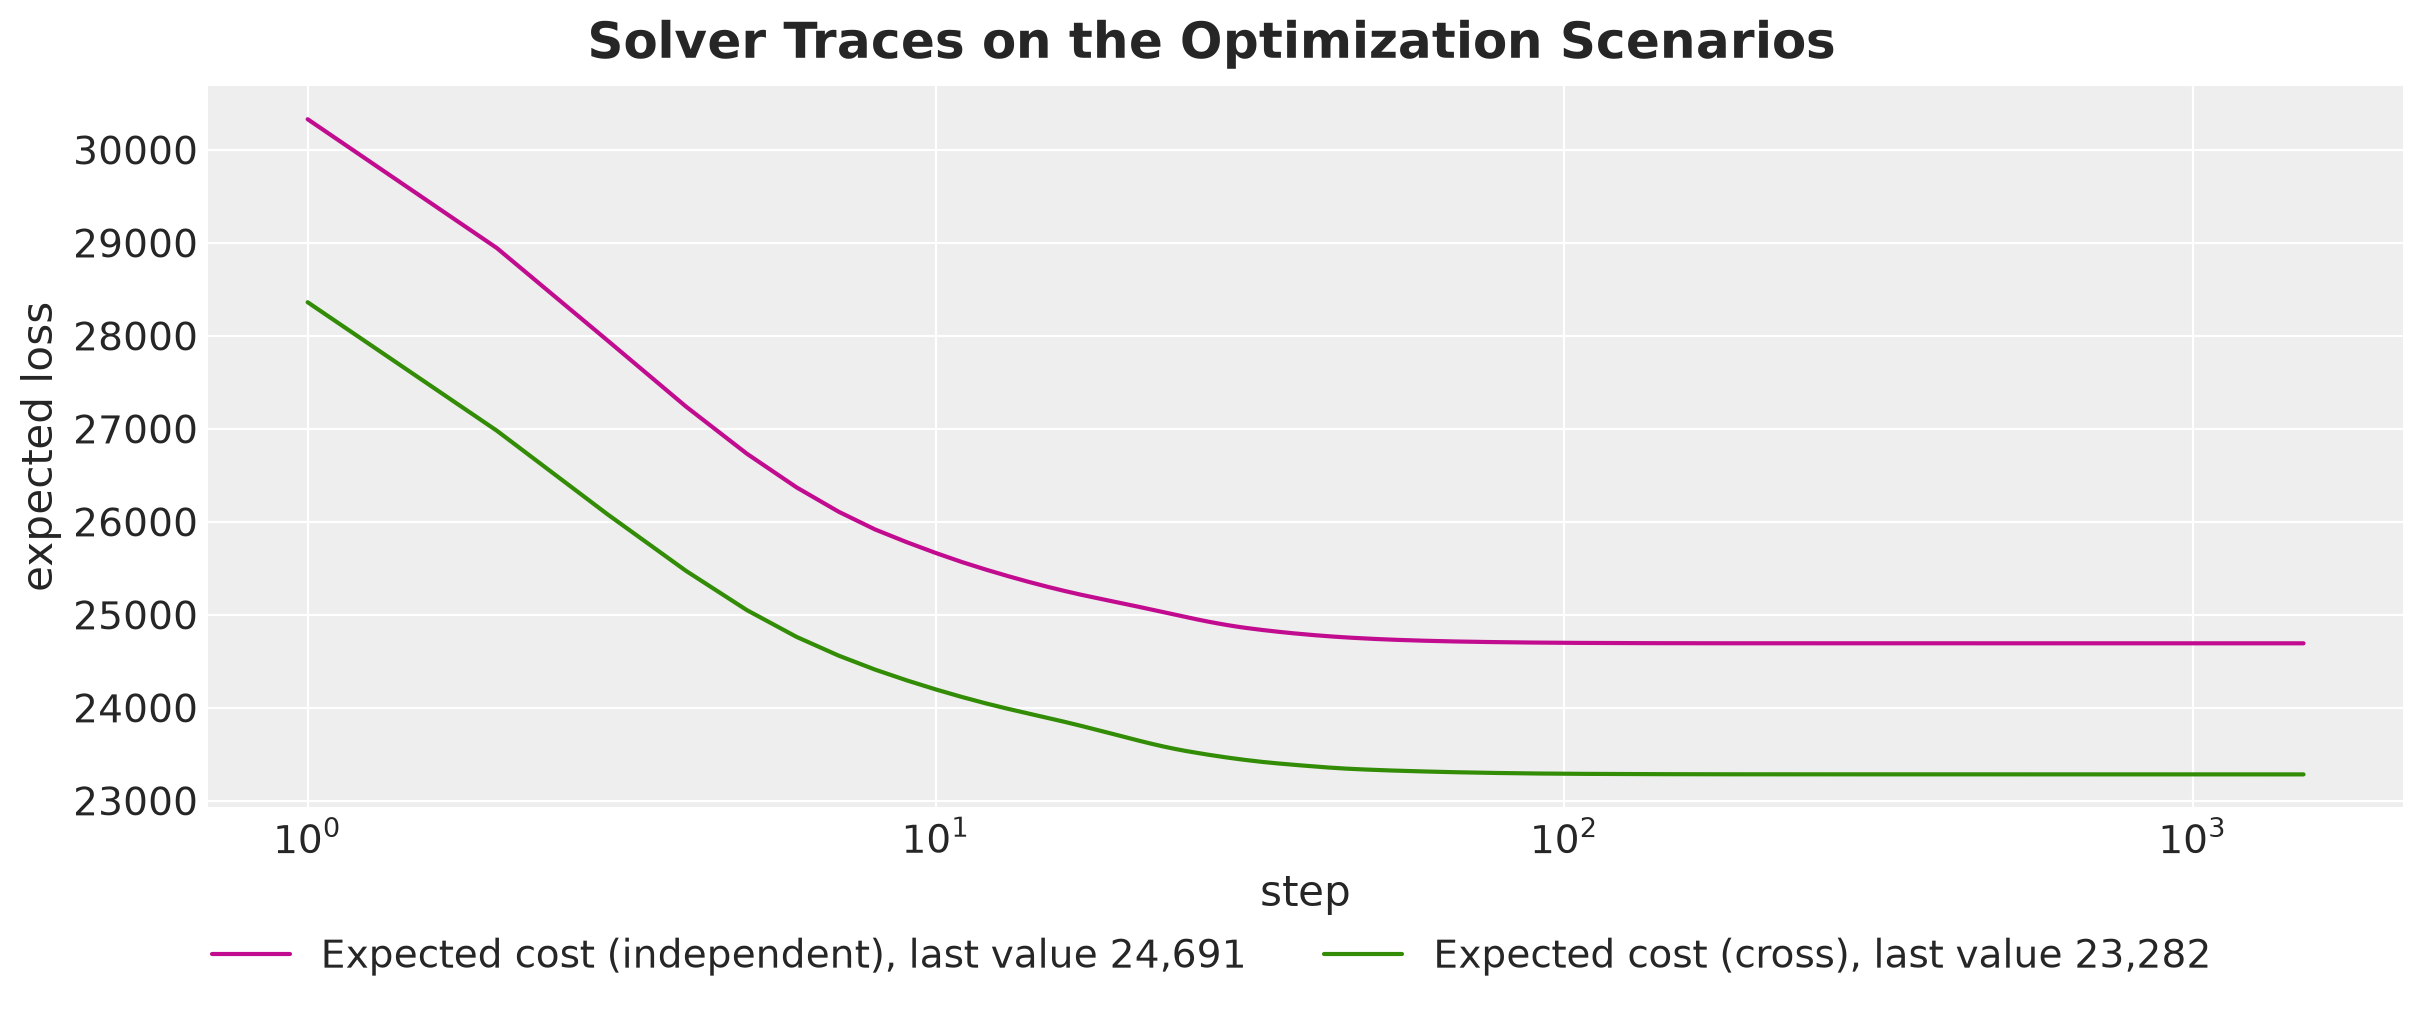

In [46]:
fig, ax = plt.subplots(figsize=(12, 5))
for model, (_, trace) in solves.items():
    ax.plot(
        np.arange(1, trace.size + 1),
        trace,
        color=MODEL_COLORS[model],
        label=f"{plans[Rule.EXPECTED_COST, model].name}, last value {trace[-1]:,.0f}",
    )
ax.set(xlabel="step", ylabel="expected loss", xscale="log")
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle(
    "Solver Traces on the Optimization Scenarios", fontsize=18, fontweight="bold"
);

Both objectives drop within the first $50$ steps and are flat after about $300$. The values on the optimization scenarios are $24{,}691$ for the independent plan and $23{,}282$ for the cross plan, and we compare them with the losses on the evaluation scenarios below.

Next, let's look at how much of the capacity the plans use. The following figure shows, for every day of the horizon, the share of the $10$ stores whose orders of that day are at capacity under each plan.

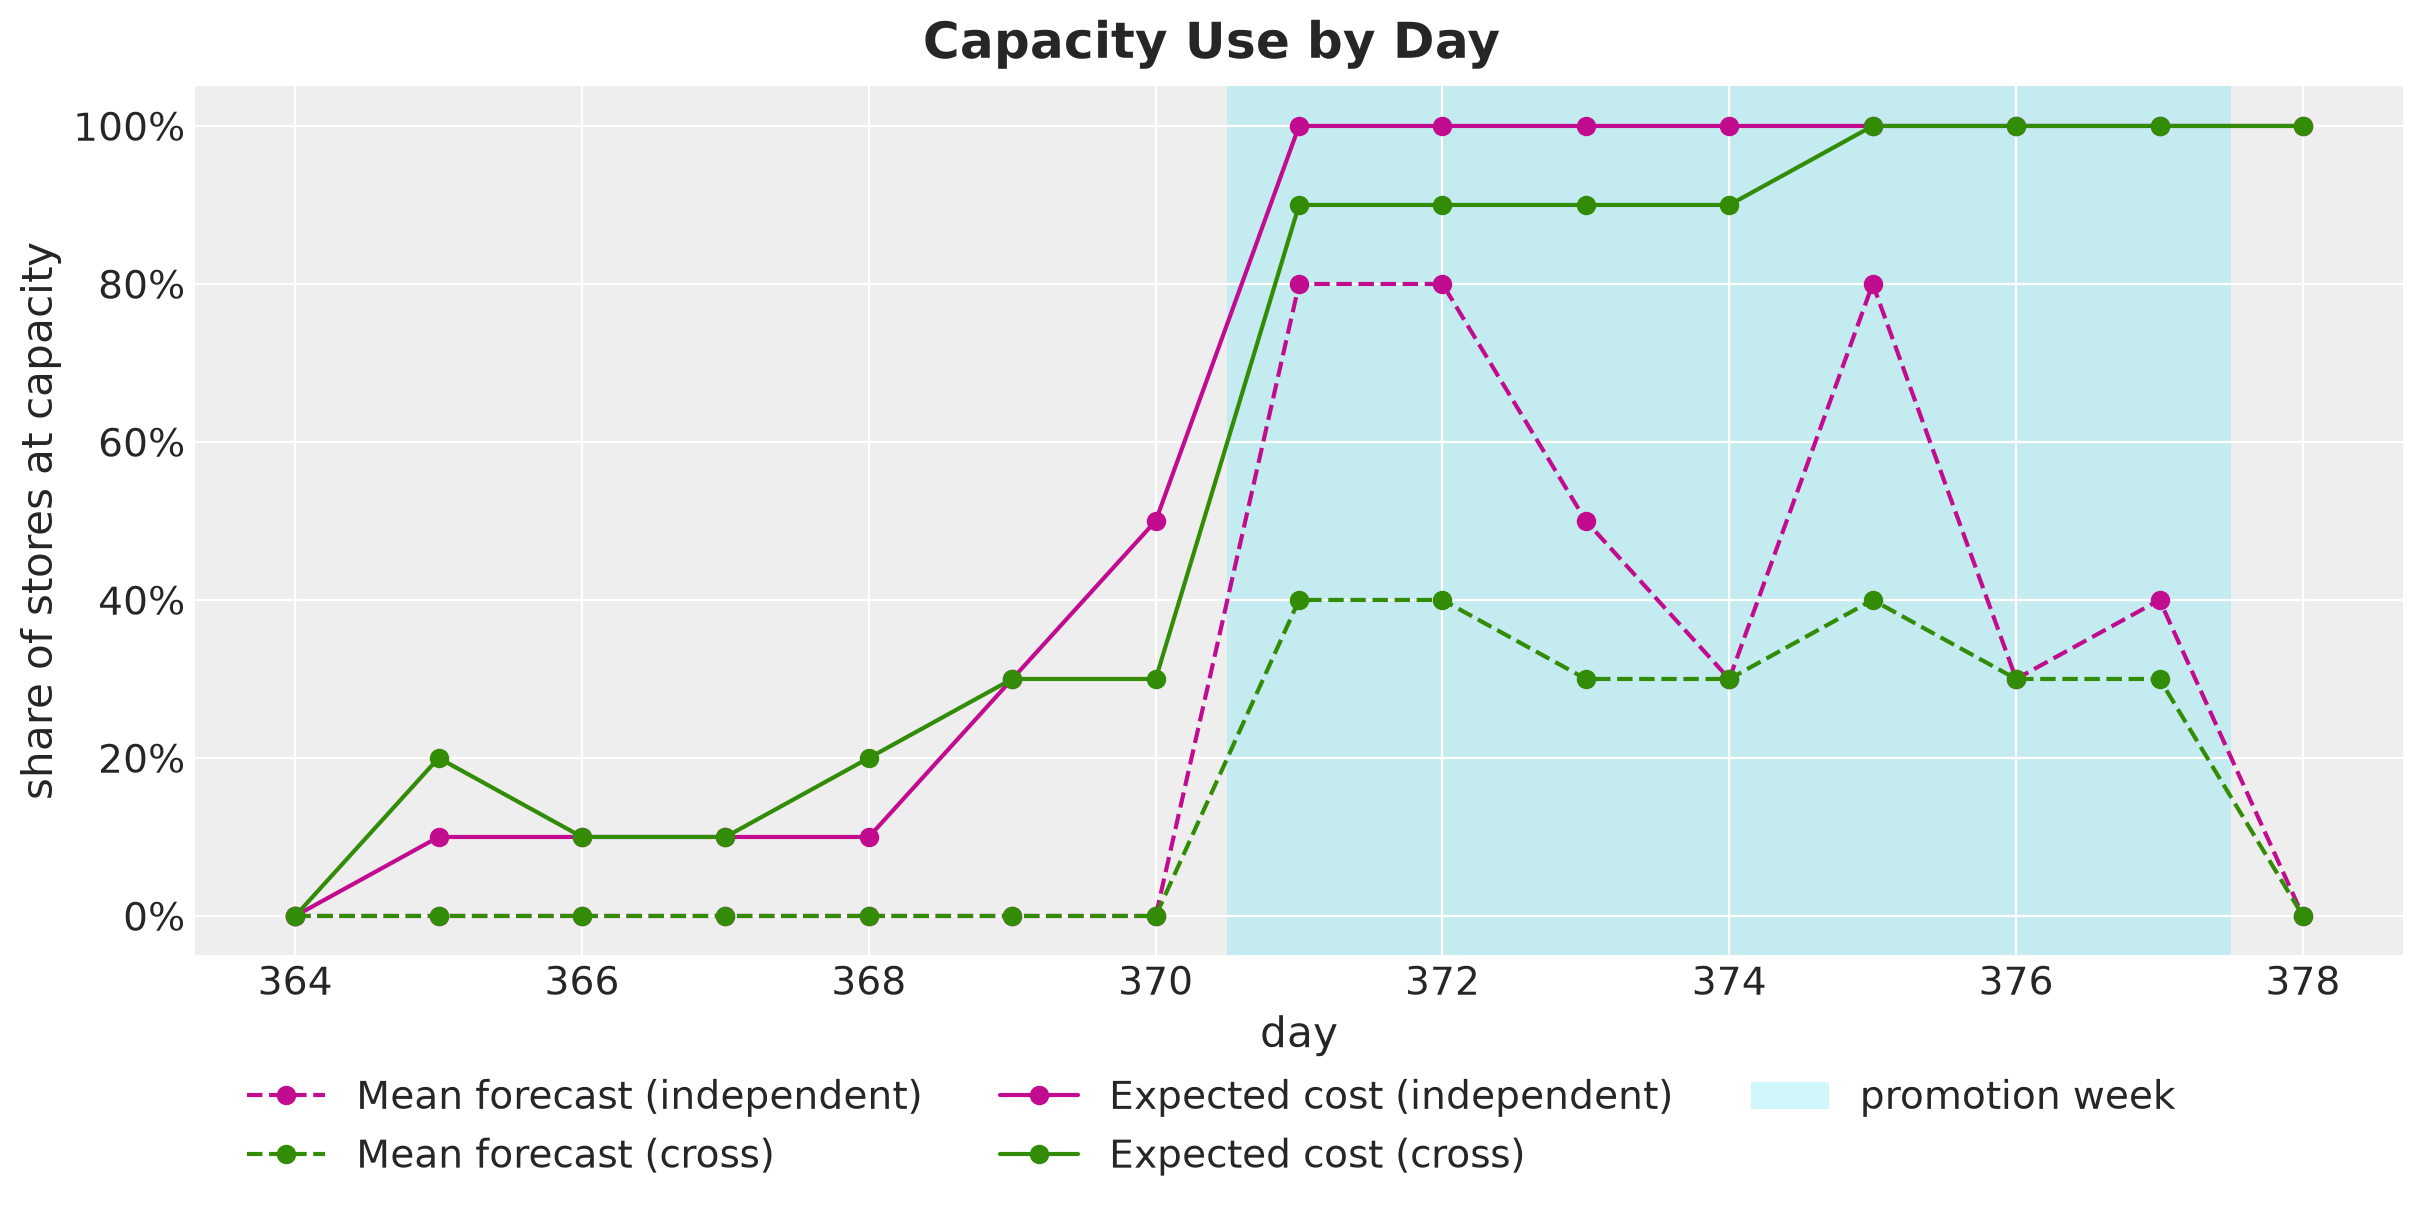

In [47]:
def at_capacity(
    orders: Float[Array, "horizon n_stores n_products"],
    capacity: Float[Array, " n_stores"],
    rtol: float,
) -> Float[Array, " horizon"]:
    """Share of the stores at capacity on every day of the horizon."""
    return (orders.sum(axis=-1) >= capacity * (1 - rtol)).mean(axis=-1)


def shade_promotion_week(ax: plt.Axes) -> None:
    """Shade the promotion week of the horizon, behind the data."""
    promo_days_future = days_future[PERIODS[Period.PROMOTION_WEEK]]
    ax.axvspan(
        promo_days_future[0] - 0.5,
        promo_days_future[-1] + 0.5,
        color="C5",
        alpha=0.3,
        linewidth=0,
        zorder=0,
        label="promotion week",
    )


fig, ax = plt.subplots(figsize=(12, 6))
for plan in plans.values():
    ax.plot(
        days_future,
        at_capacity(plan.orders, capacity, solver.tol),
        marker="o",
        color=MODEL_COLORS[plan.model],
        linestyle="--" if plan.rule is Rule.MEAN_FORECAST else "-",
        label=plan.name,
    )
shade_promotion_week(ax)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(xlabel="day", ylabel="share of stores at capacity")
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Capacity Use by Day", fontsize=18, fontweight="bold");

We read the figure by period.

- **First week.** No store is at capacity under the mean forecast plans, and the expected cost plans reach it in up to $3$ stores. On the day before the promotion week the independent plan is at capacity in $5$ of the $10$ stores and the cross plan in $3$.
- **Promotion week.** The independent plan is at capacity in every store on every day and the cross plan in $9$ or $10$ stores. The mean forecast plans reach it in $3$ to $8$ stores depending on the day.
- **Last day.** Both expected cost plans are at capacity in every store, and no mean forecast plan is. There is no later day to carry stock into, so a leftover costs $h$ once and a lost sale costs $p$, and the optimal order goes up to the $p / (p + h) = 0.95$ quantile of the demand of every product. In a rolling horizon the last order is never placed, so we do not read anything into day $15$.

Next, we compare the two expected cost plans across the whole chain. We take the orders of the independent plan minus the orders of the cross plan, per product and day, and average them over the products and stores of each role.

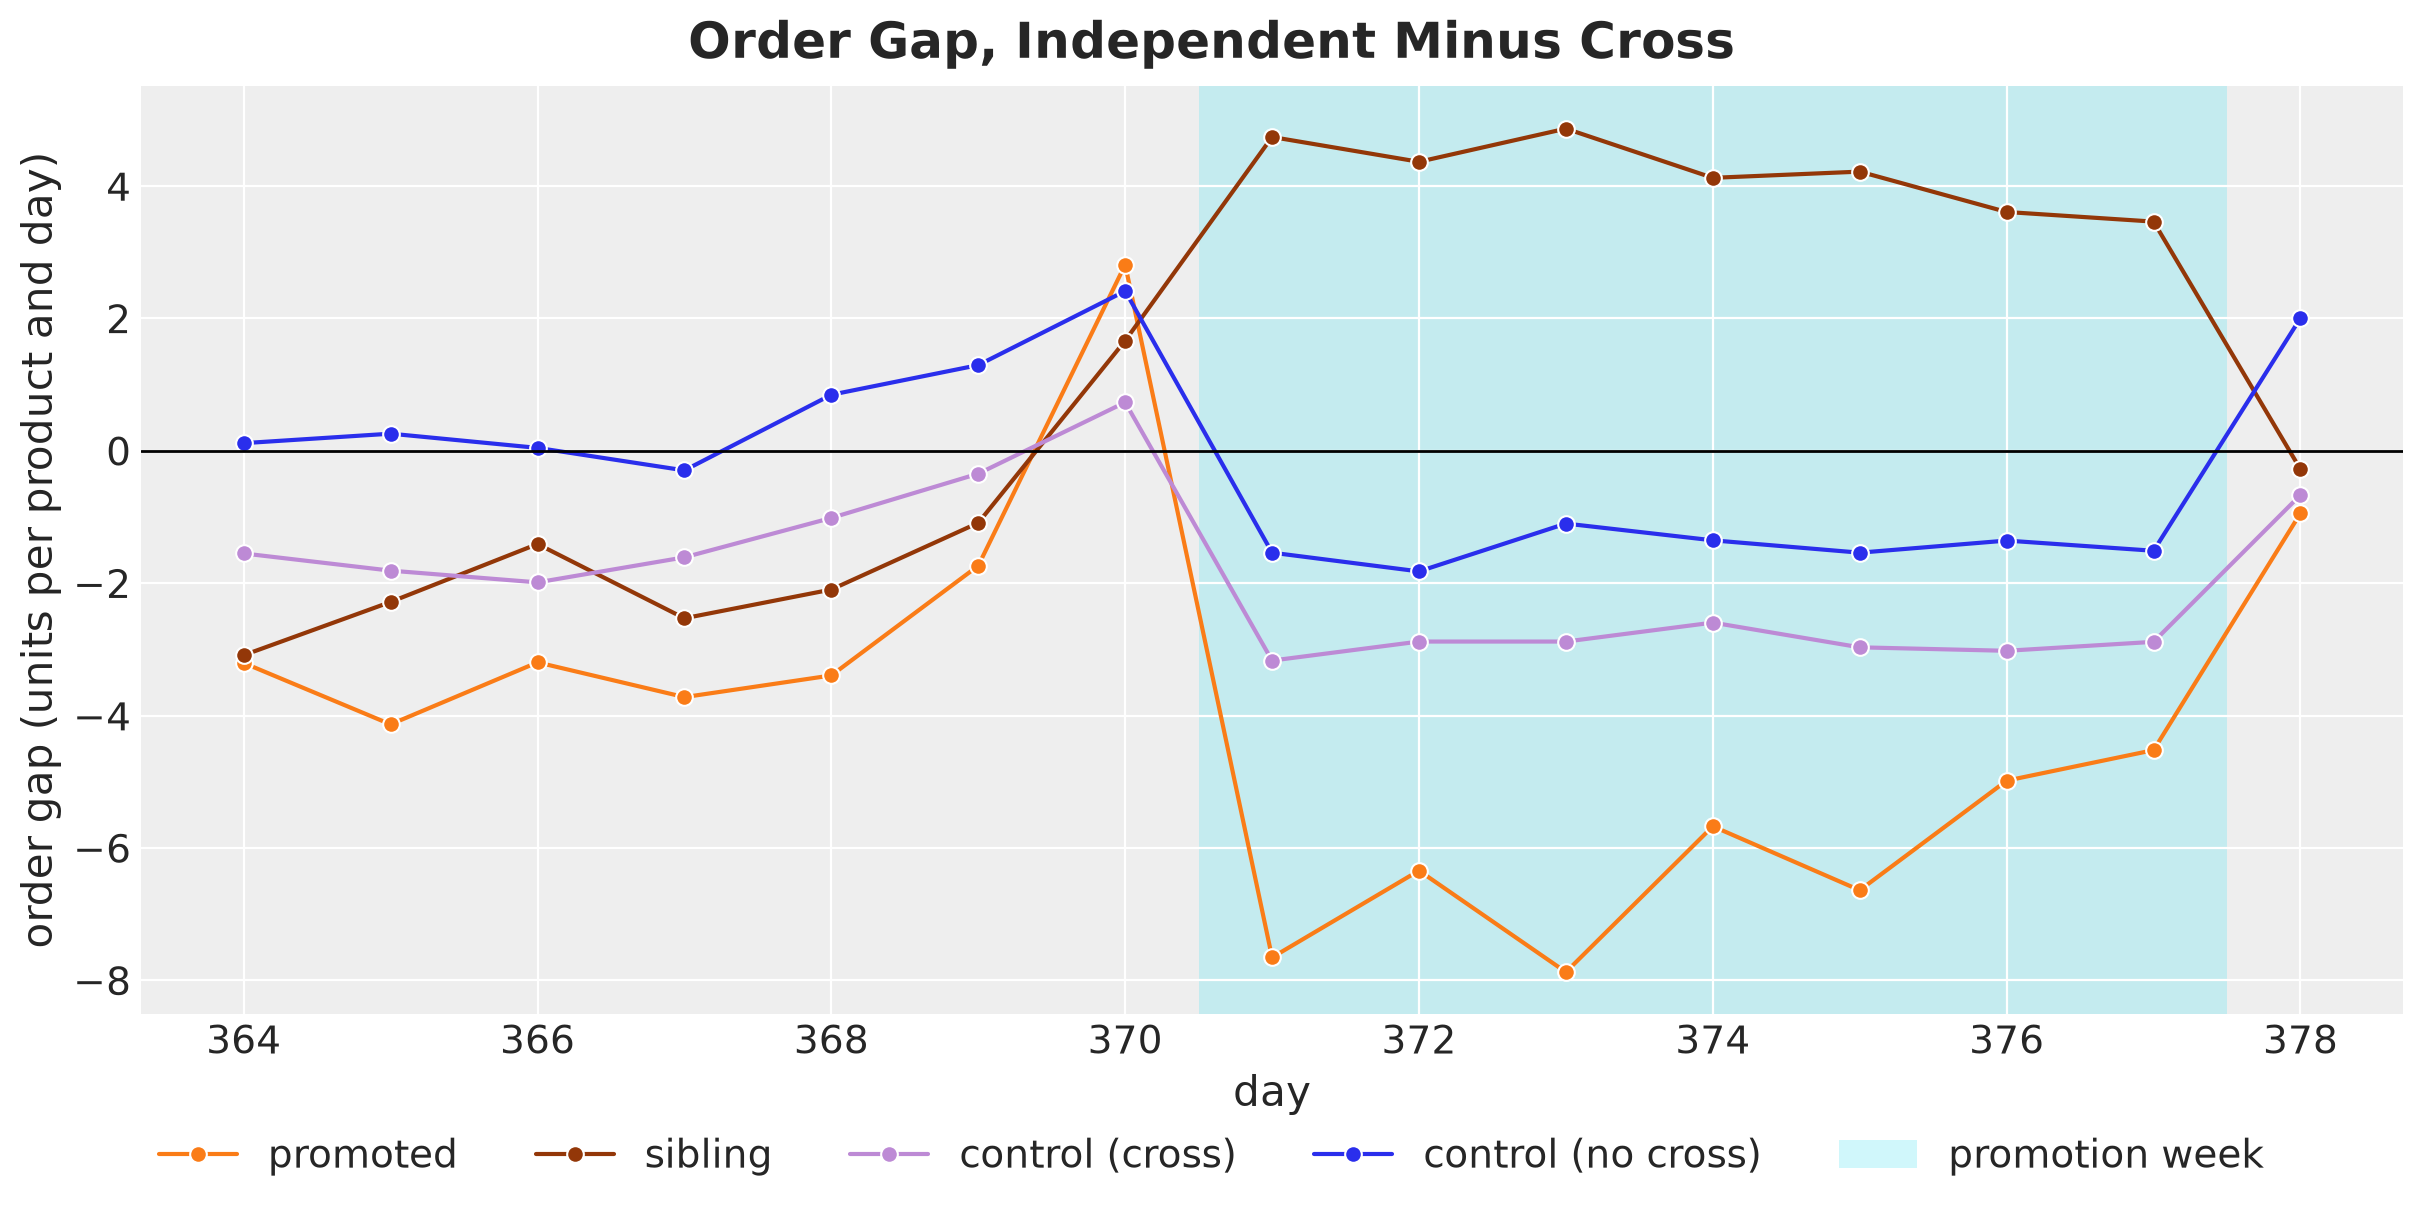

In [48]:
ROLE_COLORS = {
    Role.PROMOTED: "C1",
    Role.SIBLING: "C4",
    Role.CONTROL_CROSS: "C8",
    Role.CONTROL_NO_CROSS: "C0",
}
order_difference = orders_expected[Model.INDEPENDENT] - orders_expected[Model.CROSS]
order_gap = pl.DataFrame(
    {
        "role": np.repeat([role.value for role in Role], setup.horizon),
        "day": np.tile(days_future, len(Role)),
        "order gap": np.concatenate(
            [
                order_difference[:, :, product_role == role].mean(axis=(1, 2))
                for role in Role
            ]
        ),
    }
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=order_gap,
    x="day",
    y="order gap",
    hue="role",
    hue_order=[role.value for role in Role],
    palette=ROLE_COLORS,
    marker="o",
    ax=ax,
)
ax.axhline(0.0, color="black", linewidth=1)
shade_promotion_week(ax)
ax.get_legend().remove()
ax.set(xlabel="day", ylabel="order gap (units per product and day)")
fig.legend(loc="outside lower center", ncol=5)
fig.suptitle("Order Gap, Independent Minus Cross", fontsize=18, fontweight="bold");

We read the order difference in three periods.

- **Days $1$ to $6$.** The independent plan orders less than the cross plan on the `promoted`, `sibling` and `control (cross)` roles, by up to $4$ units per product and day. On `control (no cross)` the difference is at most about one unit. This matches the low start of the independent forecast.
- **Day $7$.** The difference turns positive on every role. The independent model does not expect the siblings to dip, so it forecasts more demand in the promotion week. The pattern is consistent with a plan that expects a tighter capacity in that week and moves orders to the day before it.
- **Promotion week.** The independent plan orders about $4$ units more per sibling and day, and $5$ to $8$ units less per promoted product and day. It is at capacity in every store, so the units that it gives to the siblings come out of the other three roles.

## Out of Sample Evaluation

We score every plan with four metrics on the $3{,}000$ evaluation scenarios and with one metric on the realized future.

- **Expected loss.** The mean over the evaluation scenarios of the loss summed over the series.
- **CVaR of the loss.** The mean of the worst $5\%$ of the scenario losses, the tail average.
- **Stockout probability per series-day.** The fraction of scenario, series and day triples with a lost sale.
- **Probability of a stockout in the horizon per series.** The fraction of scenario and series pairs with at least one lost sale in the $15$ days.
- **Loss on the realized future.** The loss of the plan against the one path we held out when we generated the data.

For every plan we also record the expected loss and the CVaR on the optimization scenarios of its own model, the values the solver sees.

In [49]:
class Metric(StrEnum):
    """Names of the scores."""

    EXPECTED_LOSS = "expected loss"
    CVAR = f"CVaR of loss (worst {solver.alpha:.0%})"
    STOCKOUT = "stockout probability per series-day"
    HORIZON = "probability of a stockout in the horizon per series"
    REALIZED = "loss on the realized future"
    OWN_EXPECTED_LOSS = "expected loss on own scenarios"
    OWN_CVAR = "CVaR of loss on own scenarios"


LOSS_METRICS = [
    Metric.EXPECTED_LOSS,
    Metric.CVAR,
    Metric.REALIZED,
    Metric.OWN_EXPECTED_LOSS,
    Metric.OWN_CVAR,
]


def is_stockout(sim: Simulation, tol: float) -> Bool[Array, "*batch horizon"]:
    """Days with lost sales above the tolerance."""
    return sim.lost_sales > tol


def evaluate(plan: Plan) -> Simulation:
    """Simulate a plan on the evaluation scenarios."""
    return simulate_scenarios(flat(plan.orders), demand_eval, initial_inventory, config)


def summarize(plan: Plan, sim: Simulation) -> dict[str, str | float]:
    """Scores of one plan on the evaluation scenarios, the realized future, its own."""
    losses = sim.loss.sum(axis=-1)
    stockout = is_stockout(sim, solver.tol)
    realized = simulate_series(
        flat(plan.orders), demand_future_true, initial_inventory, config
    ).loss.sum()
    own_losses = simulate_scenarios(
        flat(plan.orders), draws[plan.model].scenarios, initial_inventory, config
    ).loss.sum(axis=-1)
    return {
        "plan": plan.name,
        "rule": plan.rule.value,
        "model": plan.model.value,
        Metric.EXPECTED_LOSS: float(losses.mean()),
        Metric.CVAR: float(cvar(losses, solver.alpha)),
        Metric.STOCKOUT: float(stockout.mean()),
        Metric.HORIZON: float(stockout.any(axis=-1).mean()),
        Metric.REALIZED: float(realized),
        Metric.OWN_EXPECTED_LOSS: float(own_losses.mean()),
        Metric.OWN_CVAR: float(cvar(own_losses, solver.alpha)),
    }


def round_losses(frame: pl.DataFrame, columns: list[str]) -> pl.DataFrame:
    """Copy of a frame with some columns rounded to integers, for display."""
    return frame.with_columns(pl.col(columns).round(0).cast(pl.Int64))


scores = {key: evaluate(plan) for key, plan in plans.items()}
results = pl.DataFrame([summarize(plan, scores[key]) for key, plan in plans.items()])
round_losses(results, LOSS_METRICS).drop("rule", "model")

plan,expected loss,CVaR of loss (worst 5%),stockout probability per series-day,probability of a stockout in the horizon per series,loss on the realized future,expected loss on own scenarios,CVaR of loss on own scenarios
str,i64,i64,f64,f64,i64,i64,i64
"""Mean forecast (independent)""",34335,37334,0.274,0.829,34580,30328,33903
"""Mean forecast (cross)""",29271,32008,0.233,0.784,30164,28360,31190
"""Expected cost (independent)""",28435,30920,0.137,0.520,29230,24691,27288
"""Expected cost (cross)""",25769,28008,0.109,0.452,27294,23282,25361


Let's look at the four scores of each plan in one figure.

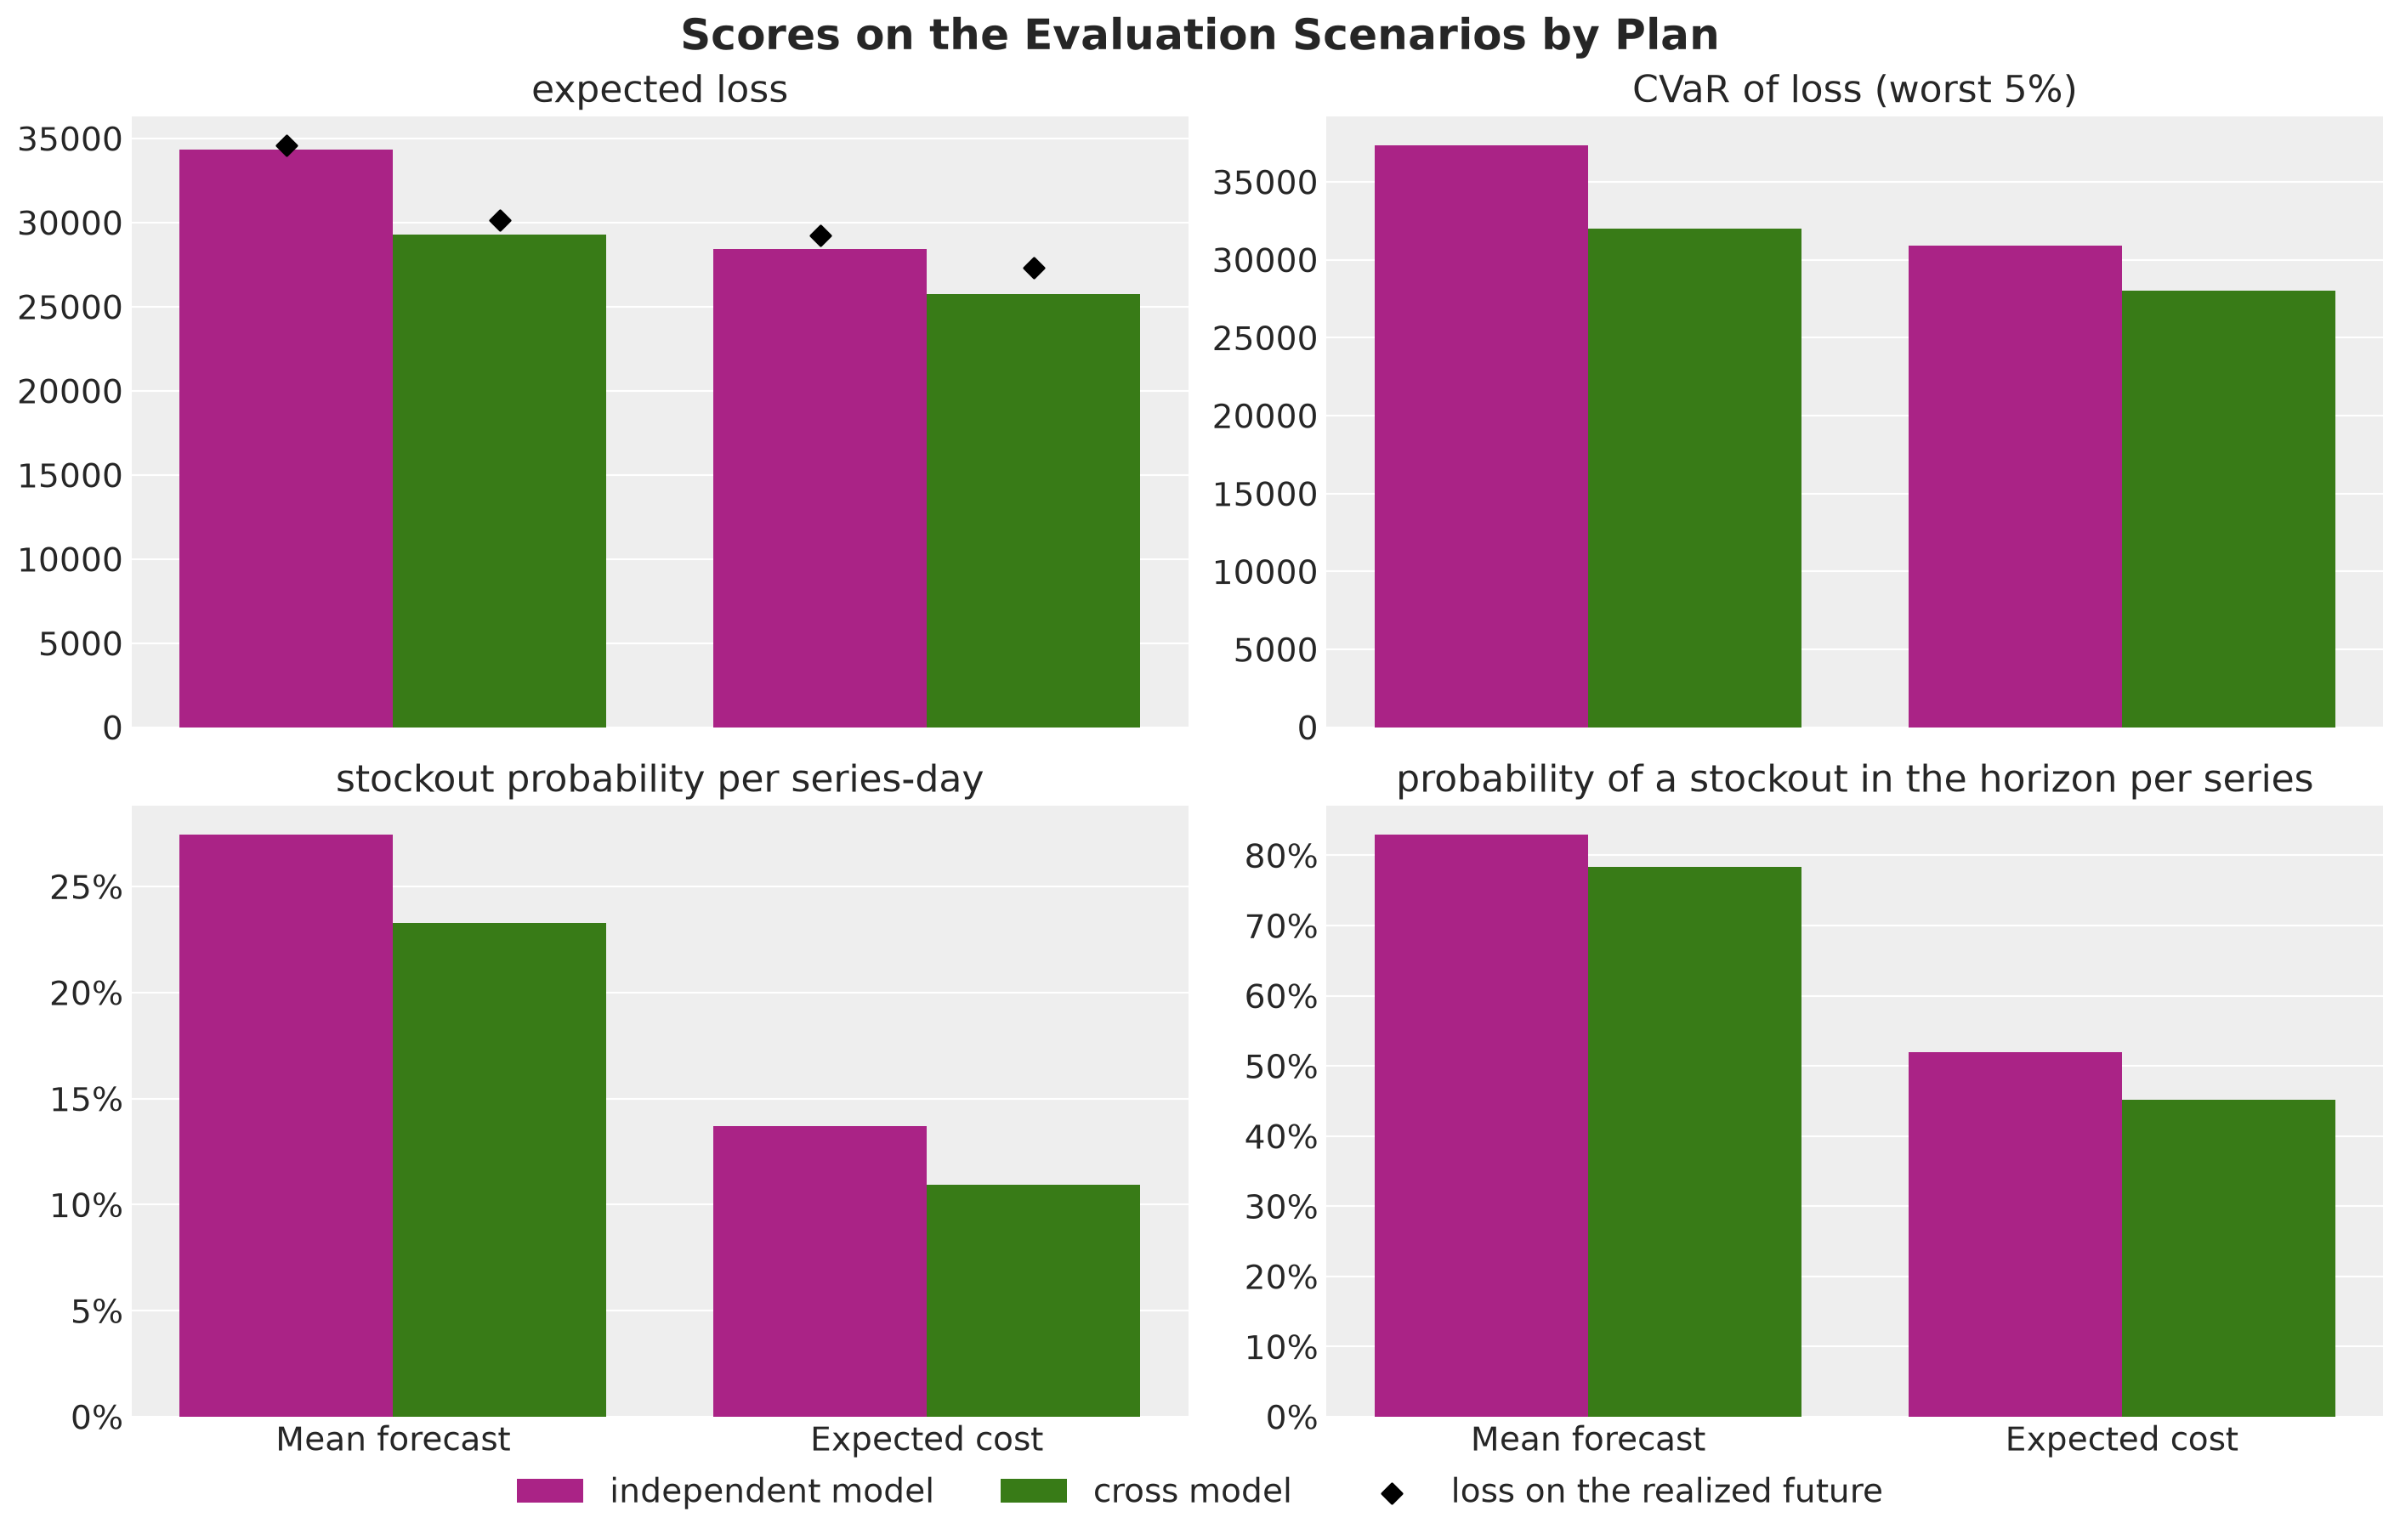

In [50]:
metrics = [Metric.EXPECTED_LOSS, Metric.CVAR, Metric.STOCKOUT, Metric.HORIZON]

fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(14, 9), sharex=True, layout="constrained"
)
for ax, metric in zip(axes.flat, metrics, strict=True):
    sns.barplot(
        data=results,
        x="rule",
        y=metric,
        hue="model",
        hue_order=[model.value for model in models],
        palette=MODEL_COLORS,
        ax=ax,
    )
    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()
    if metric in {Metric.STOCKOUT, Metric.HORIZON}:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set(title=metric, xlabel="", ylabel="")
# the bars of a rule sit at -0.2 and +0.2 around its tick, in the order of `results`
realized = axes[0, 0].scatter(
    [tick + offset for tick in range(2) for offset in (-0.2, 0.2)],
    results[Metric.REALIZED],
    color="black",
    marker="D",
    zorder=3,
)
fig.legend(
    [*handles, realized],
    [*[f"{label} model" for label in labels], Metric.REALIZED],
    loc="outside lower center",
    ncol=3,
)
fig.suptitle(
    "Scores on the Evaluation Scenarios by Plan", fontsize=18, fontweight="bold"
);

The four plans are ordered the same way on every metric.

- **Point forecast against distribution.** Within a model, the mean forecast plan costs $21\%$ more than the expected cost plan under the independent model ($34{,}335$ against $28{,}435$) and $14\%$ more under the cross model ($29{,}271$ against $25{,}769$). The first post found the same order on one series.
- **Independent against cross.** Within a rule, the plan of the independent model costs $17\%$ more than the plan of the cross model under the mean forecast rule and $10\%$ more under the expected cost rule ($28{,}435$ against $25{,}769$). The second number is the cost of ignoring cannibalization on this panel.
- **Rule and model.** The mean forecast plan of the cross model costs $3\%$ more than the expected cost plan of the independent model. On this panel the decision rule matters about as much as the model.
- **Service.** The stockout probability per series-day falls from $27\%$ and $23\%$ under the mean forecast plans to $14\%$ and $11\%$ under the expected cost plans. The probability of at least one stockout per series in the horizon falls from $83\%$ and $78\%$ to $52\%$ and $45\%$.
- **Realized future.** The losses on the realized future are within $6\%$ of the expected losses and keep the same order.

The two expected cost plans also cost more on the evaluation scenarios than on the scenarios of their own model, by $11\%$ for the cross plan ($25{,}769$ against $23{,}282$) and by $15\%$ for the independent plan. The order of the four plans is the same on both.

In the first post the two numbers agreed to within $1\%$, because the held-out scenarios came from the same posterior. Here the evaluation scenarios come from the true process, and the increase is consistent with a forecast that is wrong about the level of each series.

Recall from the *Parameter Recovery* section that the posterior mean of the level is off by about $0.06$ to $0.07$ on the log scale for a typical series, twice what the guide believes or more. The scenarios of a model are centered on its own estimate of the level, so they do not contain this error, and the evaluation scenarios do.

Each of these scores is an average over the evaluation scenarios. The next figure shows the distribution behind the averages, with the mean and the central $50\%$ and $94\%$ of the loss of each plan.

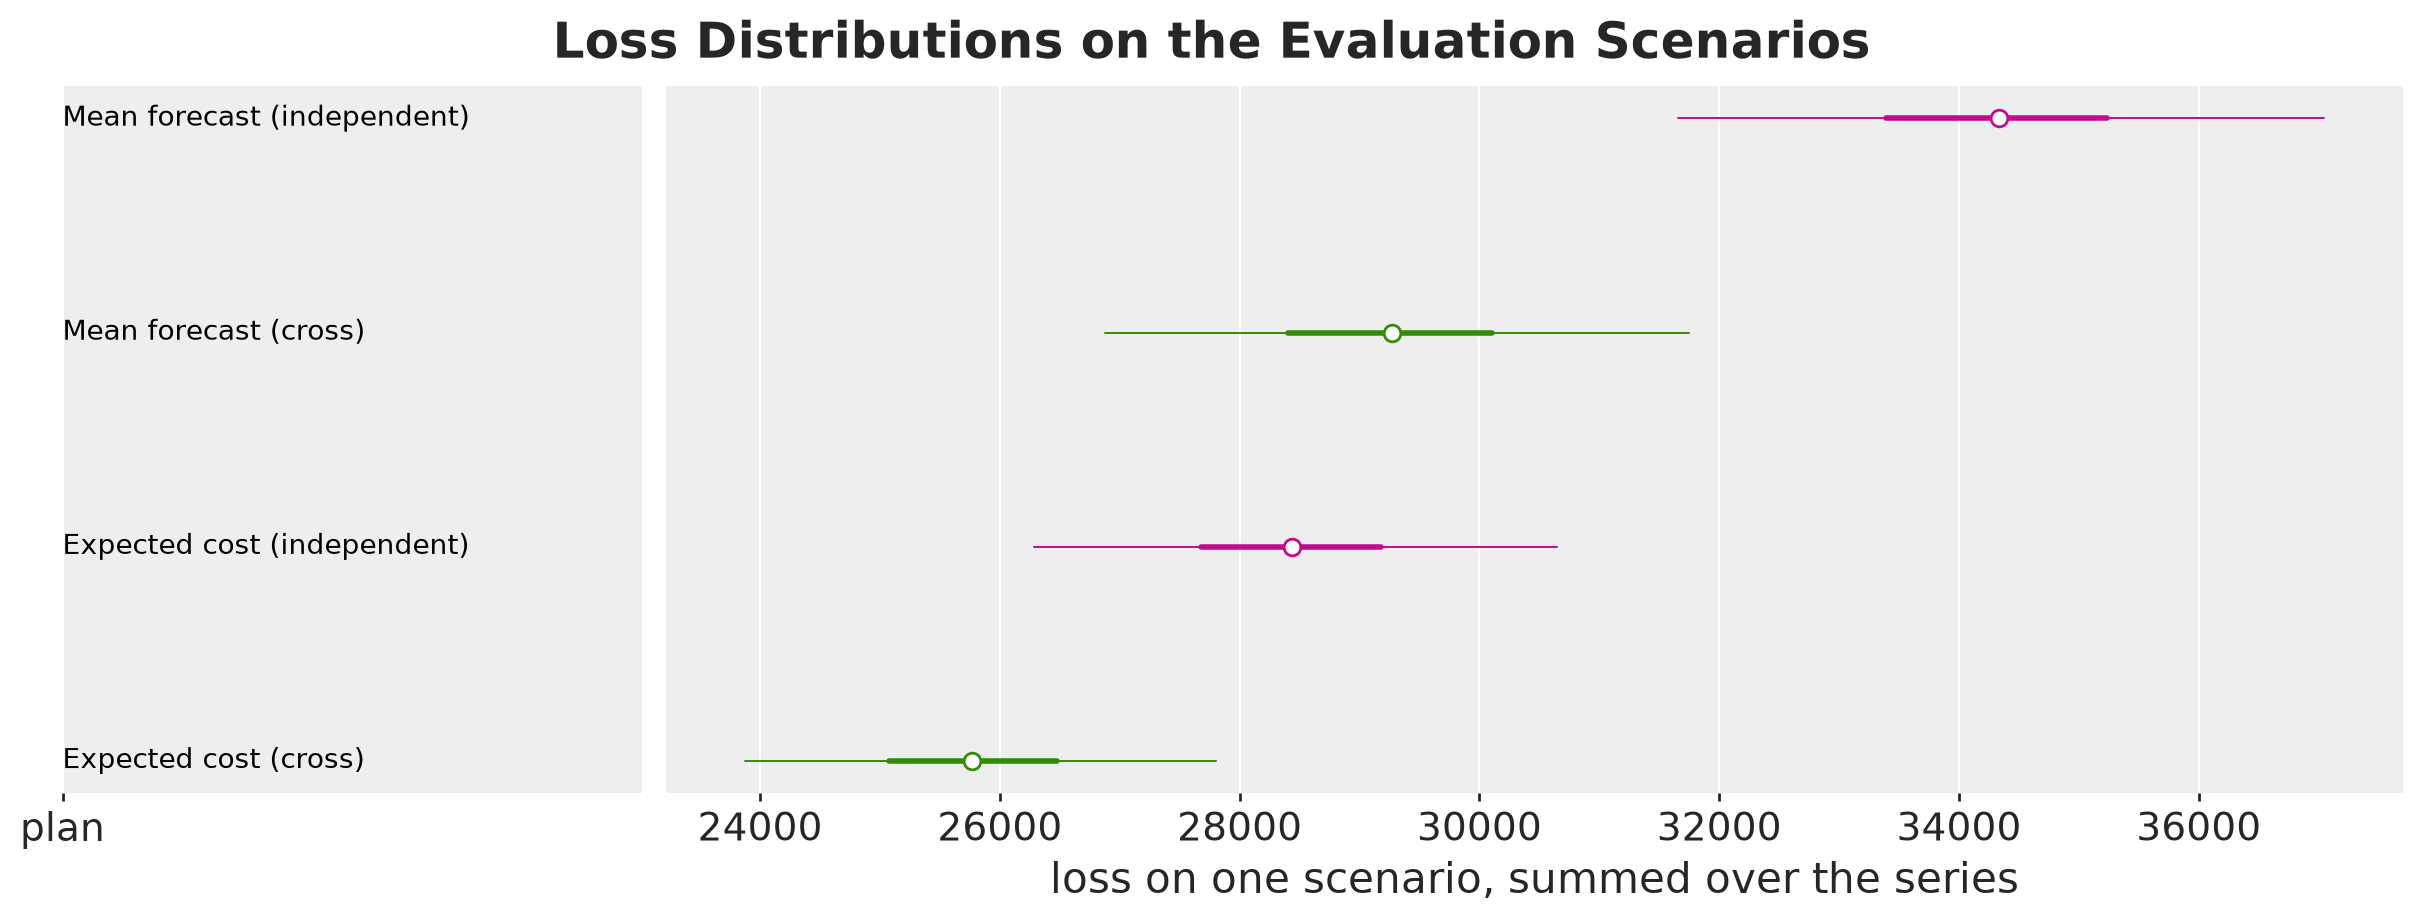

In [51]:
losses_by_plan = xr.Dataset(
    {
        "loss": (
            ("sample", "plan"),
            jnp.stack([sim.loss.sum(axis=-1) for sim in scores.values()], axis=-1),
        )
    },
    coords={"plan": [plan.name for plan in plans.values()]},
)

pc = az.plot_forest(
    losses_by_plan,
    sample_dims=["sample"],
    labels=["plan"],
    aes={"color": ["plan"]},
    color=[MODEL_COLORS[plan.model] for plan in plans.values()],
    figure_kwargs={"figsize": (12, 4.5)},
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.set(xlabel="loss on one scenario, summed over the series")
pc.viz["figure"].item().suptitle(
    "Loss Distributions on the Evaluation Scenarios", fontsize=18, fontweight="bold"
);

The four distributions are ordered as their means, and the $50\%$ intervals of the two expected cost plans do not overlap. The intervals are narrow relative to the means.

We score the plans on the same scenarios, so we can also compare the two expected cost plans scenario by scenario. The following table summarizes the **gap**, the loss of the independent plan minus the loss of the cross plan, over the evaluation scenarios.

In [52]:
loss_difference = (
    scores[Rule.EXPECTED_COST, Model.INDEPENDENT].loss
    - scores[Rule.EXPECTED_COST, Model.CROSS].loss
).sum(axis=-1)
tail = (1 - CI_PROB) / 2
lower, upper = f"{tail:.0%} quantile", f"{1 - tail:.0%} quantile"
round_losses(
    pl.DataFrame(
        {
            "share of scenarios with a cheaper cross plan": [
                float((loss_difference > 0).mean())
            ],
            "mean difference": [float(loss_difference.mean())],
            lower: [float(jnp.quantile(loss_difference, tail))],
            upper: [float(jnp.quantile(loss_difference, 1 - tail))],
        }
    ),
    ["mean difference", lower, upper],
)

share of scenarios with a cheaper cross plan,mean difference,3% quantile,97% quantile
f64,i64,i64,i64
1.000,2666,1388,3904


The cross plan is cheaper in every one of the $3{,}000$ evaluation scenarios of this history. The gap has a mean of $2{,}666$, and its central $94\%$ runs from $1{,}388$ to $3{,}904$.

The tails of the loss are thin. The tail average is $1.09$ times the expected loss for every plan, against about $3$ for the mean forecast plan of the first post. The next two sections look at what that means for the tail weight and for the dependence across series.

### Tail Weight

In the first post the CVaR plan, which minimizes the objective with $\lambda = 1$, had a visibly lower tail loss than the expected cost plan. Here we solve it on the scenarios of the cross model and score it twice, on those scenarios and on the evaluation scenarios.

In [53]:
orders_cvar, _ = solve_jit(
    draws[Model.CROSS].scenarios,
    1.0,
    orders_mean[Model.CROSS],
    capacity,
    initial_inventory,
    config,
    solver,
)
tail_metrics = [
    Metric.OWN_EXPECTED_LOSS,
    Metric.OWN_CVAR,
    Metric.EXPECTED_LOSS,
    Metric.CVAR,
]
round_losses(
    pl.DataFrame(
        [
            summarize(plan, evaluate(plan))
            for plan in [
                plans[Rule.EXPECTED_COST, Model.CROSS],
                Plan(Rule.CVAR, Model.CROSS, orders_cvar),
            ]
        ]
    ).select("plan", *tail_metrics),
    tail_metrics,
)

plan,expected loss on own scenarios,CVaR of loss on own scenarios,expected loss,CVaR of loss (worst 5%)
str,i64,i64,i64,i64
"""Expected cost (cross)""",23282,25361,25769,28008
"""CVaR (cross)""",23401,24916,25969,28198


On the scenarios of the cross model the tail weight lowers the tail. The CVaR plan has a tail loss of $24{,}916$ against $25{,}361$ for the expected cost plan, about $2\%$ lower, at an expected loss $0.5\%$ higher.

The lower tail does not carry over to the evaluation scenarios, where the CVaR plan has a tail of $28{,}198$ against $28{,}008$. The level error is not in the scenarios of the model, so the tail weight did not lower the tail here.

We keep the expected cost plans from here on.

### Dependence Across Series

In the first post we shuffled the days of the scenarios to show that the carried stock needs joint draws over time. Here we check whether the expected cost plan also needs joint draws across series. We shuffle the scenario index of every series independently, which keeps every single-series path and removes the dependence across series, and evaluate the objective of the expected cost plan on both sets.

We also measure how much dependence there is to lose. For each set of scenarios we take the total demand of every series over the horizon, and we divide the variance of the sum of these totals over the series by the sum of their variances. A ratio of one means uncorrelated series.

In [54]:
def variance_ratio(demand: Float[Array, "scenarios horizon n_series"]) -> float:
    """Variance of the chain total over the sum of the variances of the series."""
    per_series = demand.sum(axis=1)
    return float(per_series.sum(axis=1).var() / per_series.var(axis=0).sum())


rng_key, key_shuffle = random.split(rng_key)
shuffle_each_series = jax.vmap(random.permutation, in_axes=(0, 2), out_axes=2)
demand_shuffled = shuffle_each_series(
    random.split(key_shuffle, setup.n_series), draws[Model.CROSS].scenarios
)
objective_joint, objective_shuffled = (
    objective(
        orders_expected[Model.CROSS],
        demand,
        0.0,
        initial_inventory,
        config,
        solver.alpha,
    )
    for demand in (draws[Model.CROSS].scenarios, demand_shuffled)
)
assert jnp.allclose(objective_joint, objective_shuffled, rtol=1e-6)

pl.DataFrame(
    {
        "scenarios": [
            "evaluation (true process)",
            *[f"optimization ({model})" for model in models],
        ],
        "variance ratio": [
            variance_ratio(demand_eval),
            *[variance_ratio(draws[model].scenarios) for model in models],
        ],
    }
)

scenarios,variance ratio
str,f64
"""evaluation (true process)""",0.995
"""optimization (independent)""",0.976
"""optimization (cross)""",1.043


The assertion passes, so the objective is equal on the joint and on the shuffled scenarios, up to floating point. Under the expected cost rule the objective is a sum over the series of per-series expected losses, and the capacity constrains the orders, which are the same in every scenario. The plan depends on the marginal distribution of each series alone.

The table shows that there is little dependence to lose. The three ratios are $0.995$, $0.976$ and $1.043$, all close to one. The series are independent in the generator, which has no shock common to the series.

With independent series the high and the low series of a scenario cancel in the sum, which explains the thin tail of the total loss. On data with common shocks the dependence would matter for a rule on the total loss, such as a tail weight.

The joint draws over time remain necessary, since the stock carries over within a series.

### Cost Decomposition

To see which products and days are behind the cost of ignoring cannibalization, we split the expected loss of the two expected cost plans on the evaluation scenarios by series, period and cost part (holding and lost sales). From here on the gap is the expected gap, the difference of these expected losses.

First, we sum the gap over the products of each group, for each period. The last two columns give the share of each group in the total gap and the gap of a group over the expected loss of the cross plan on that group.

In [55]:
class Cost(StrEnum):
    """Parts of the loss."""

    HOLDING = "holding"
    LOST_SALES = "lost sales"


def loss_parts(
    sim: Simulation, days_slice: slice
) -> dict[Cost, Float[Array, " n_series"]]:
    """Expected holding cost and lost sales cost per series over some days."""
    holding = sim.inventory[:, :, days_slice].sum(axis=-1).mean(axis=0)
    lost_sales = sim.lost_sales[:, :, days_slice].sum(axis=-1).mean(axis=0)
    return {
        Cost.HOLDING: config.holding_cost * holding,
        Cost.LOST_SALES: config.lost_sales_cost * lost_sales,
    }


def gap_frame(sim_independent: Simulation, sim_cross: Simulation) -> pl.DataFrame:
    """Loss of the cross plan and gap to it, per series, period and cost part."""
    frames = []
    for period, days_slice in PERIODS.items():
        parts_independent = loss_parts(sim_independent, days_slice)
        parts_cross = loss_parts(sim_cross, days_slice)
        frames += [
            pl.DataFrame(
                {
                    "product": panel.series_to_product,
                    "period": period.value,
                    "part": part.value,
                    "loss_cross": parts_cross[part].tolist(),
                    "gap": (parts_independent[part] - parts_cross[part]).tolist(),
                }
            )
            for part in parts_independent
        ]
    return pl.concat(frames).join(
        products.select("product", "group", "role", "cross_elasticity"), on="product"
    )


gap_long = gap_frame(
    scores[Rule.EXPECTED_COST, Model.INDEPENDENT],
    scores[Rule.EXPECTED_COST, Model.CROSS],
)
period_names = [period.value for period in Period]
gap_by_group = (
    gap_long.group_by("group", "cross_elasticity", "period")
    .agg(pl.col("gap").sum())
    .pivot(on="period", index=["group", "cross_elasticity"], values="gap")
    .join(
        gap_long.group_by("group").agg(
            pl.col("loss_cross").sum(), total=pl.col("gap").sum()
        ),
        on="group",
    )
    .sort("group")
    .select(
        pl.format("group {} ({})", "group", "cross_elasticity").alias("group"),
        *period_names,
        "total",
        "loss_cross",
    )
)
gap_by_group = pl.concat(
    [
        gap_by_group,
        gap_by_group.select(pl.lit("all").alias("group"), pl.exclude("group").sum()),
    ]
)
round_losses(gap_by_group, [*period_names, "total"]).select(
    pl.exclude("loss_cross"),
    (gap_by_group["total"] / gap_by_group["total"][-1]).alias("share of the gap"),
    (gap_by_group["total"] / gap_by_group["loss_cross"]).alias(
        "gap / loss of the cross plan"
    ),
)

group,first week,promotion week,last day,total,share of the gap,gap / loss of the cross plan
str,i64,i64,i64,i64,f64,f64
"""group 1 (0.6)""",1000,777,92,1870,0.701,0.253
"""group 2 (0.3)""",37,95,25,157,0.059,0.041
"""group 3 (0.0)""",-23,101,-17,62,0.023,0.009
"""group 4 (0.3)""",155,384,-5,534,0.200,0.146
"""group 5 (0.0)""",-6,63,-13,44,0.016,0.011
"""all""",1163,1420,83,2666,1.000,0.103


The gap is the largest in group $1$, which has the largest cross elasticity and a sibling promotion in the last week of the history.

- **Group $1$.** It accounts for $1{,}870$ of the gap of $2{,}666$, or $70\%$, which is $25\%$ of the loss of the cross plan on this group.
- **Groups $2$ and $4$.** They account for $157$ and $534$, or $6\%$ and $20\%$ of the gap. Both have a cross elasticity of $0.3$. Group $2$ has a promoted product in the horizon. Group $4$ has none, but it saw sibling promotions in two of the last four weeks of the history, and its gap is more than three times larger.
- **Groups $3$ and $5$.** They account for $62$ and $44$, about $2\%$ of the gap each. These groups have no cannibalization. Their gap comes from the promotion week ($101$ and $63$), where they share the capacity with the other groups.

By period the gap is $1{,}163$ in the first week, $1{,}420$ in the promotion week and $83$ on the last day. A forecast that starts low stays low, so the promotion week also contains cost from the low start.

Next, we split the gap by product, for the first week and for the promotion week.

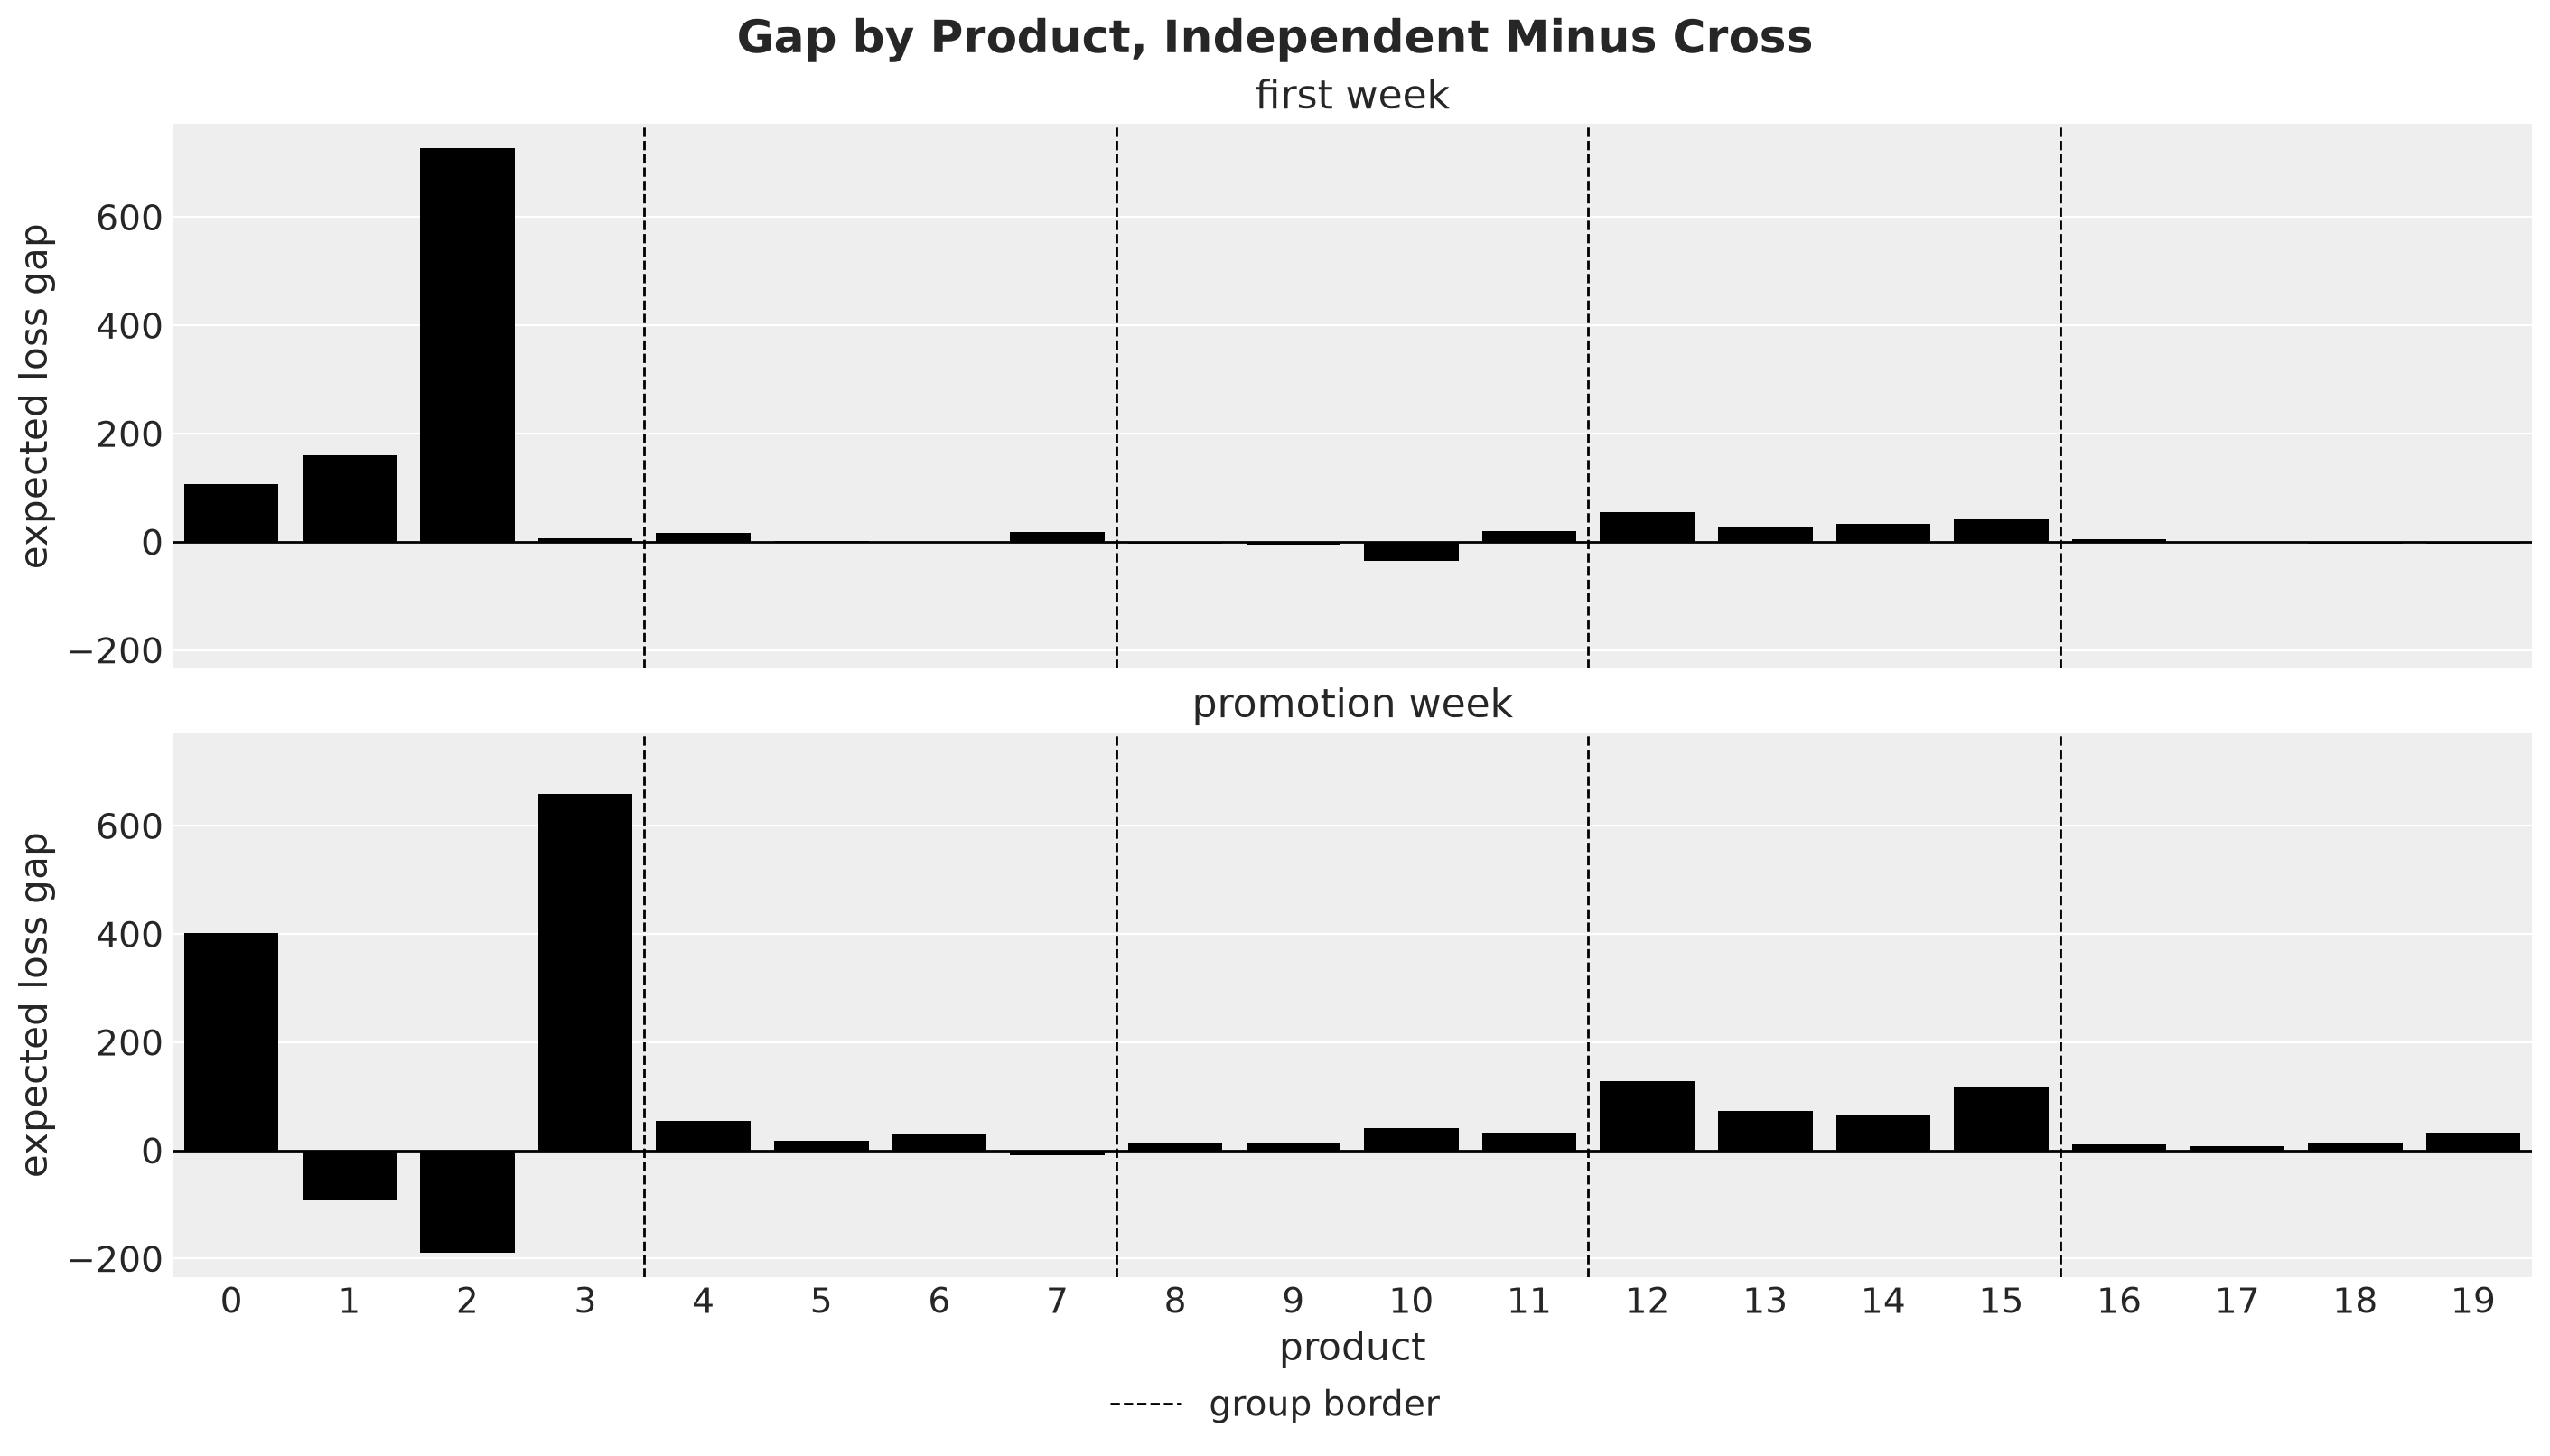

In [56]:
gap_by_product = (
    gap_long.group_by("product", "period").agg(pl.col("gap").sum()).sort("product")
)

fig, axes = plt.subplots(
    nrows=2, figsize=(14, 8), sharex=True, sharey=True, layout="constrained"
)
for ax, period in zip(axes, [Period.FIRST_WEEK, Period.PROMOTION_WEEK], strict=True):
    sns.barplot(
        data=gap_by_product.filter(pl.col("period") == period.value),
        x="product",
        y="gap",
        color="black",
        ax=ax,
    )
    ax.axhline(0.0, color="black", linewidth=1)
    for group in range(1, setup.n_groups):
        ax.axvline(
            group * setup.n_per_group - 0.5,
            color="black",
            linestyle="--",
            linewidth=1,
            label="group border" if group == 1 else None,
        )
    ax.set(title=period, xlabel="", ylabel="expected loss gap")
axes[-1].set(xlabel="product")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center")
fig.suptitle("Gap by Product, Independent Minus Cross", fontsize=18, fontweight="bold");

The two periods single out different products.

- **First week.** Products $0$, $1$ and $2$ account for most of the gap, with about $110$, $160$ and $730$. These are the three products whose forecast starts low after the promotion of product $3$ in the last week of the history. The gap of product $3$ is close to zero, and so is the gap of the products of groups $3$ and $5$.
- **Promotion week.** Product $3$ has the largest gap, about $660$. Its forecast started at the right level, so the independent plan stocks it for a demand that then dips by $19\%$. On products $1$ and $2$ the gap is negative. Their forecast started low, which offsets the dip that the independent model does not expect, so the two errors cancel.

The next figure splits the gap by role, cost part and period. The roles have $3$, $9$, $4$ and $4$ products, so we divide the gap of a role by its number of products.

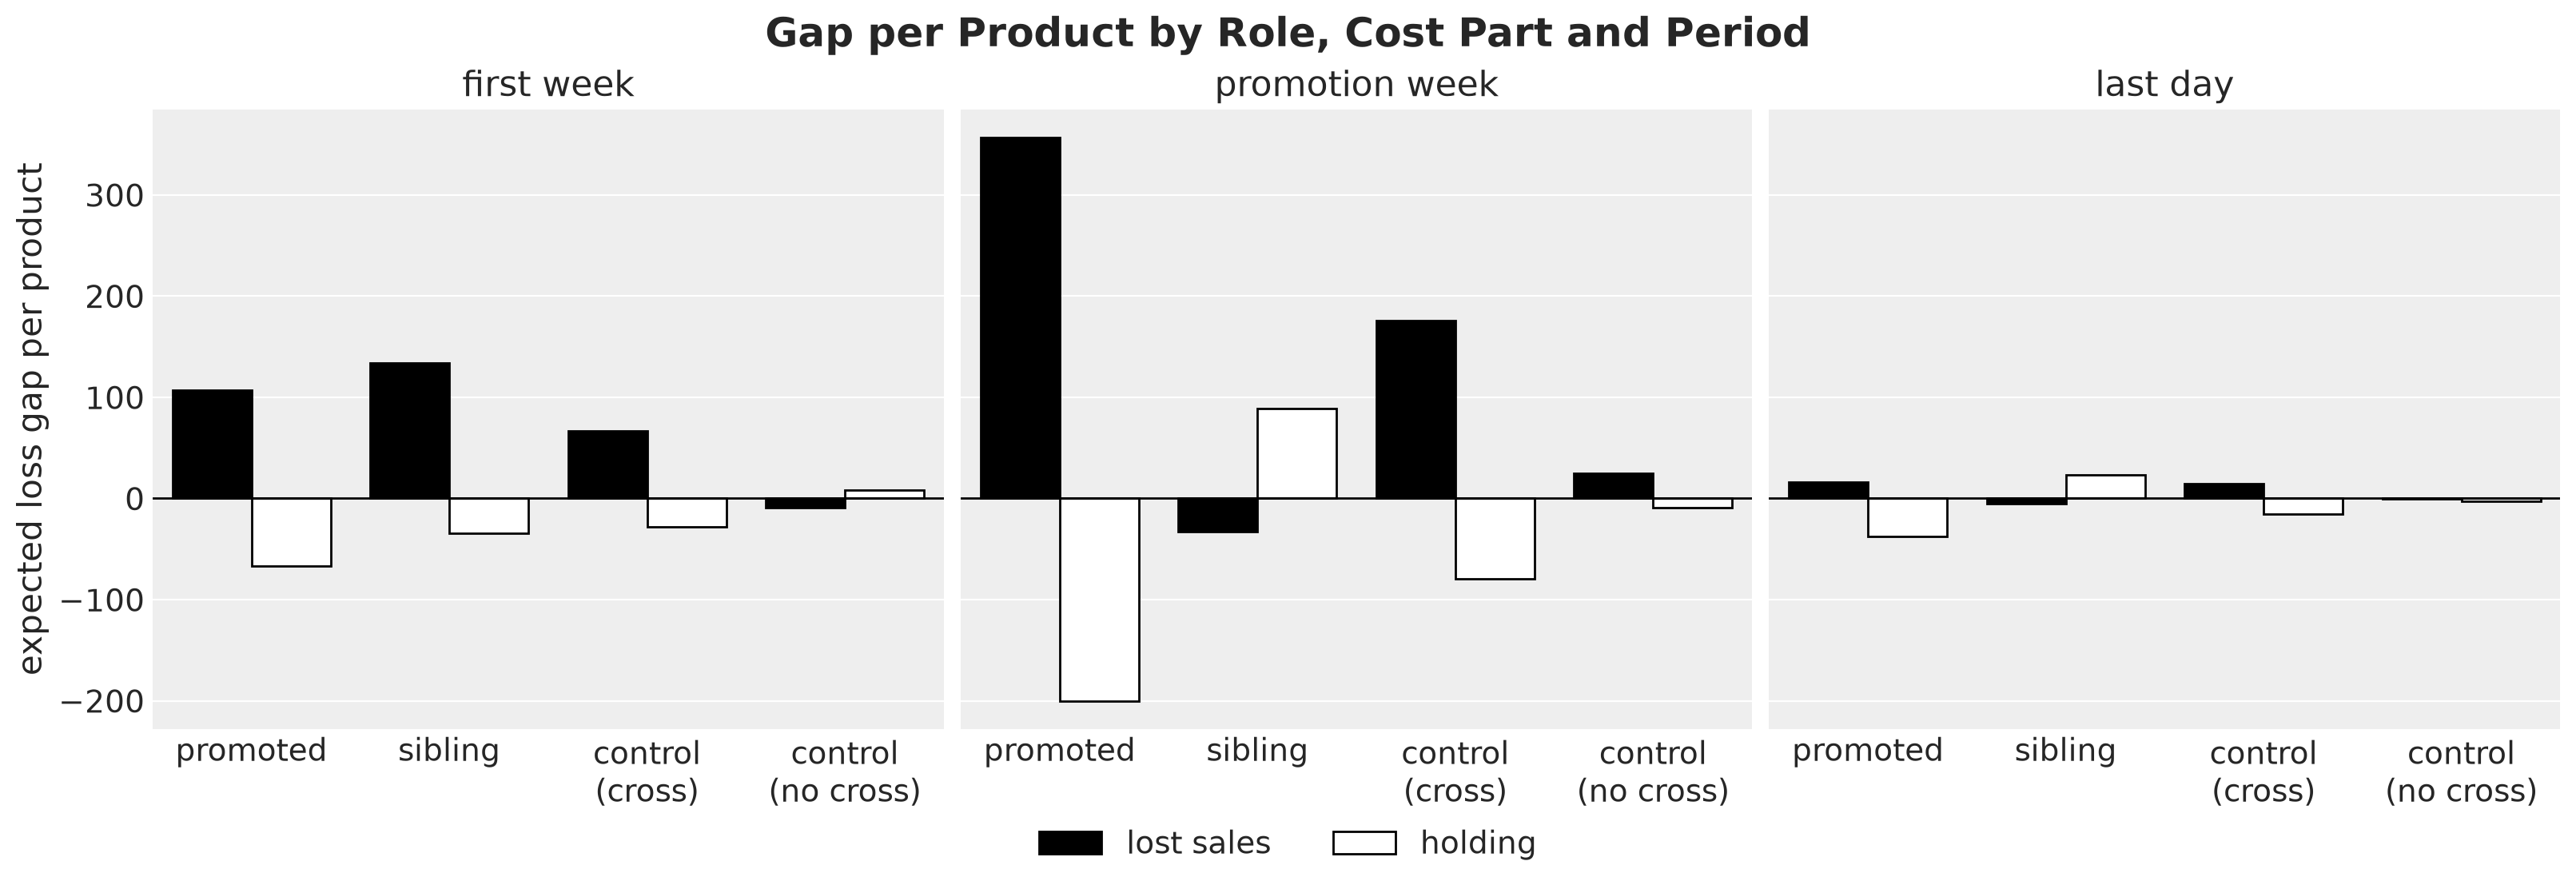

In [57]:
products_per_role = products.group_by("role").agg(n_products=pl.len())
gap_by_role = (
    gap_long.group_by("role", "period", "part")
    .agg(pl.col("gap").sum())
    .join(products_per_role, on="role")
    .with_columns(gap_per_product=pl.col("gap") / pl.col("n_products"))
)

fig, axes = plt.subplots(ncols=3, figsize=(16, 5.5), sharey=True, layout="constrained")
for ax, period in zip(axes, Period, strict=True):
    sns.barplot(
        data=gap_by_role.filter(pl.col("period") == period.value),
        x="role",
        y="gap_per_product",
        hue="part",
        order=[role.value for role in Role],
        hue_order=[Cost.LOST_SALES, Cost.HOLDING],
        palette={Cost.LOST_SALES: "black", Cost.HOLDING: "white"},
        edgecolor="black",
        ax=ax,
    )
    ax.axhline(0.0, color="black", linewidth=1)
    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()
    ax.set_xticks(range(len(Role)), [role.replace(" (", "\n(") for role in Role])
    ax.set(title=period, xlabel="", ylabel="expected loss gap per product")
fig.legend(handles, labels, loc="outside lower center", ncol=2)
fig.suptitle(
    "Gap per Product by Role, Cost Part and Period", fontsize=18, fontweight="bold"
);

The sign of each part tells us what the independent plan does wrong in each period.

- **First week.** On the `promoted`, `sibling` and `control (cross)` roles the independent plan has more lost sales and less holding. With lost sales at $20$ times the holding cost, the lost sales cost more than the lower stock saves.
- **Promotion week.** On the siblings the signs flip, since the independent plan overstocks them. The promoted products have about $360$ more in lost sales per product.
- **Last day.** The parts are small and of both signs.

The control group with cross effects has no promotion in the horizon, but its forecast starts low, so it loses sales in the first week. It loses more in the promotion week, where the low start carries over and the capacity binds. We separate these two effects in the *Capacity Sensitivity* section.

Next, we look at the stockout probability per day under the two expected cost plans, averaged over the series of each role.

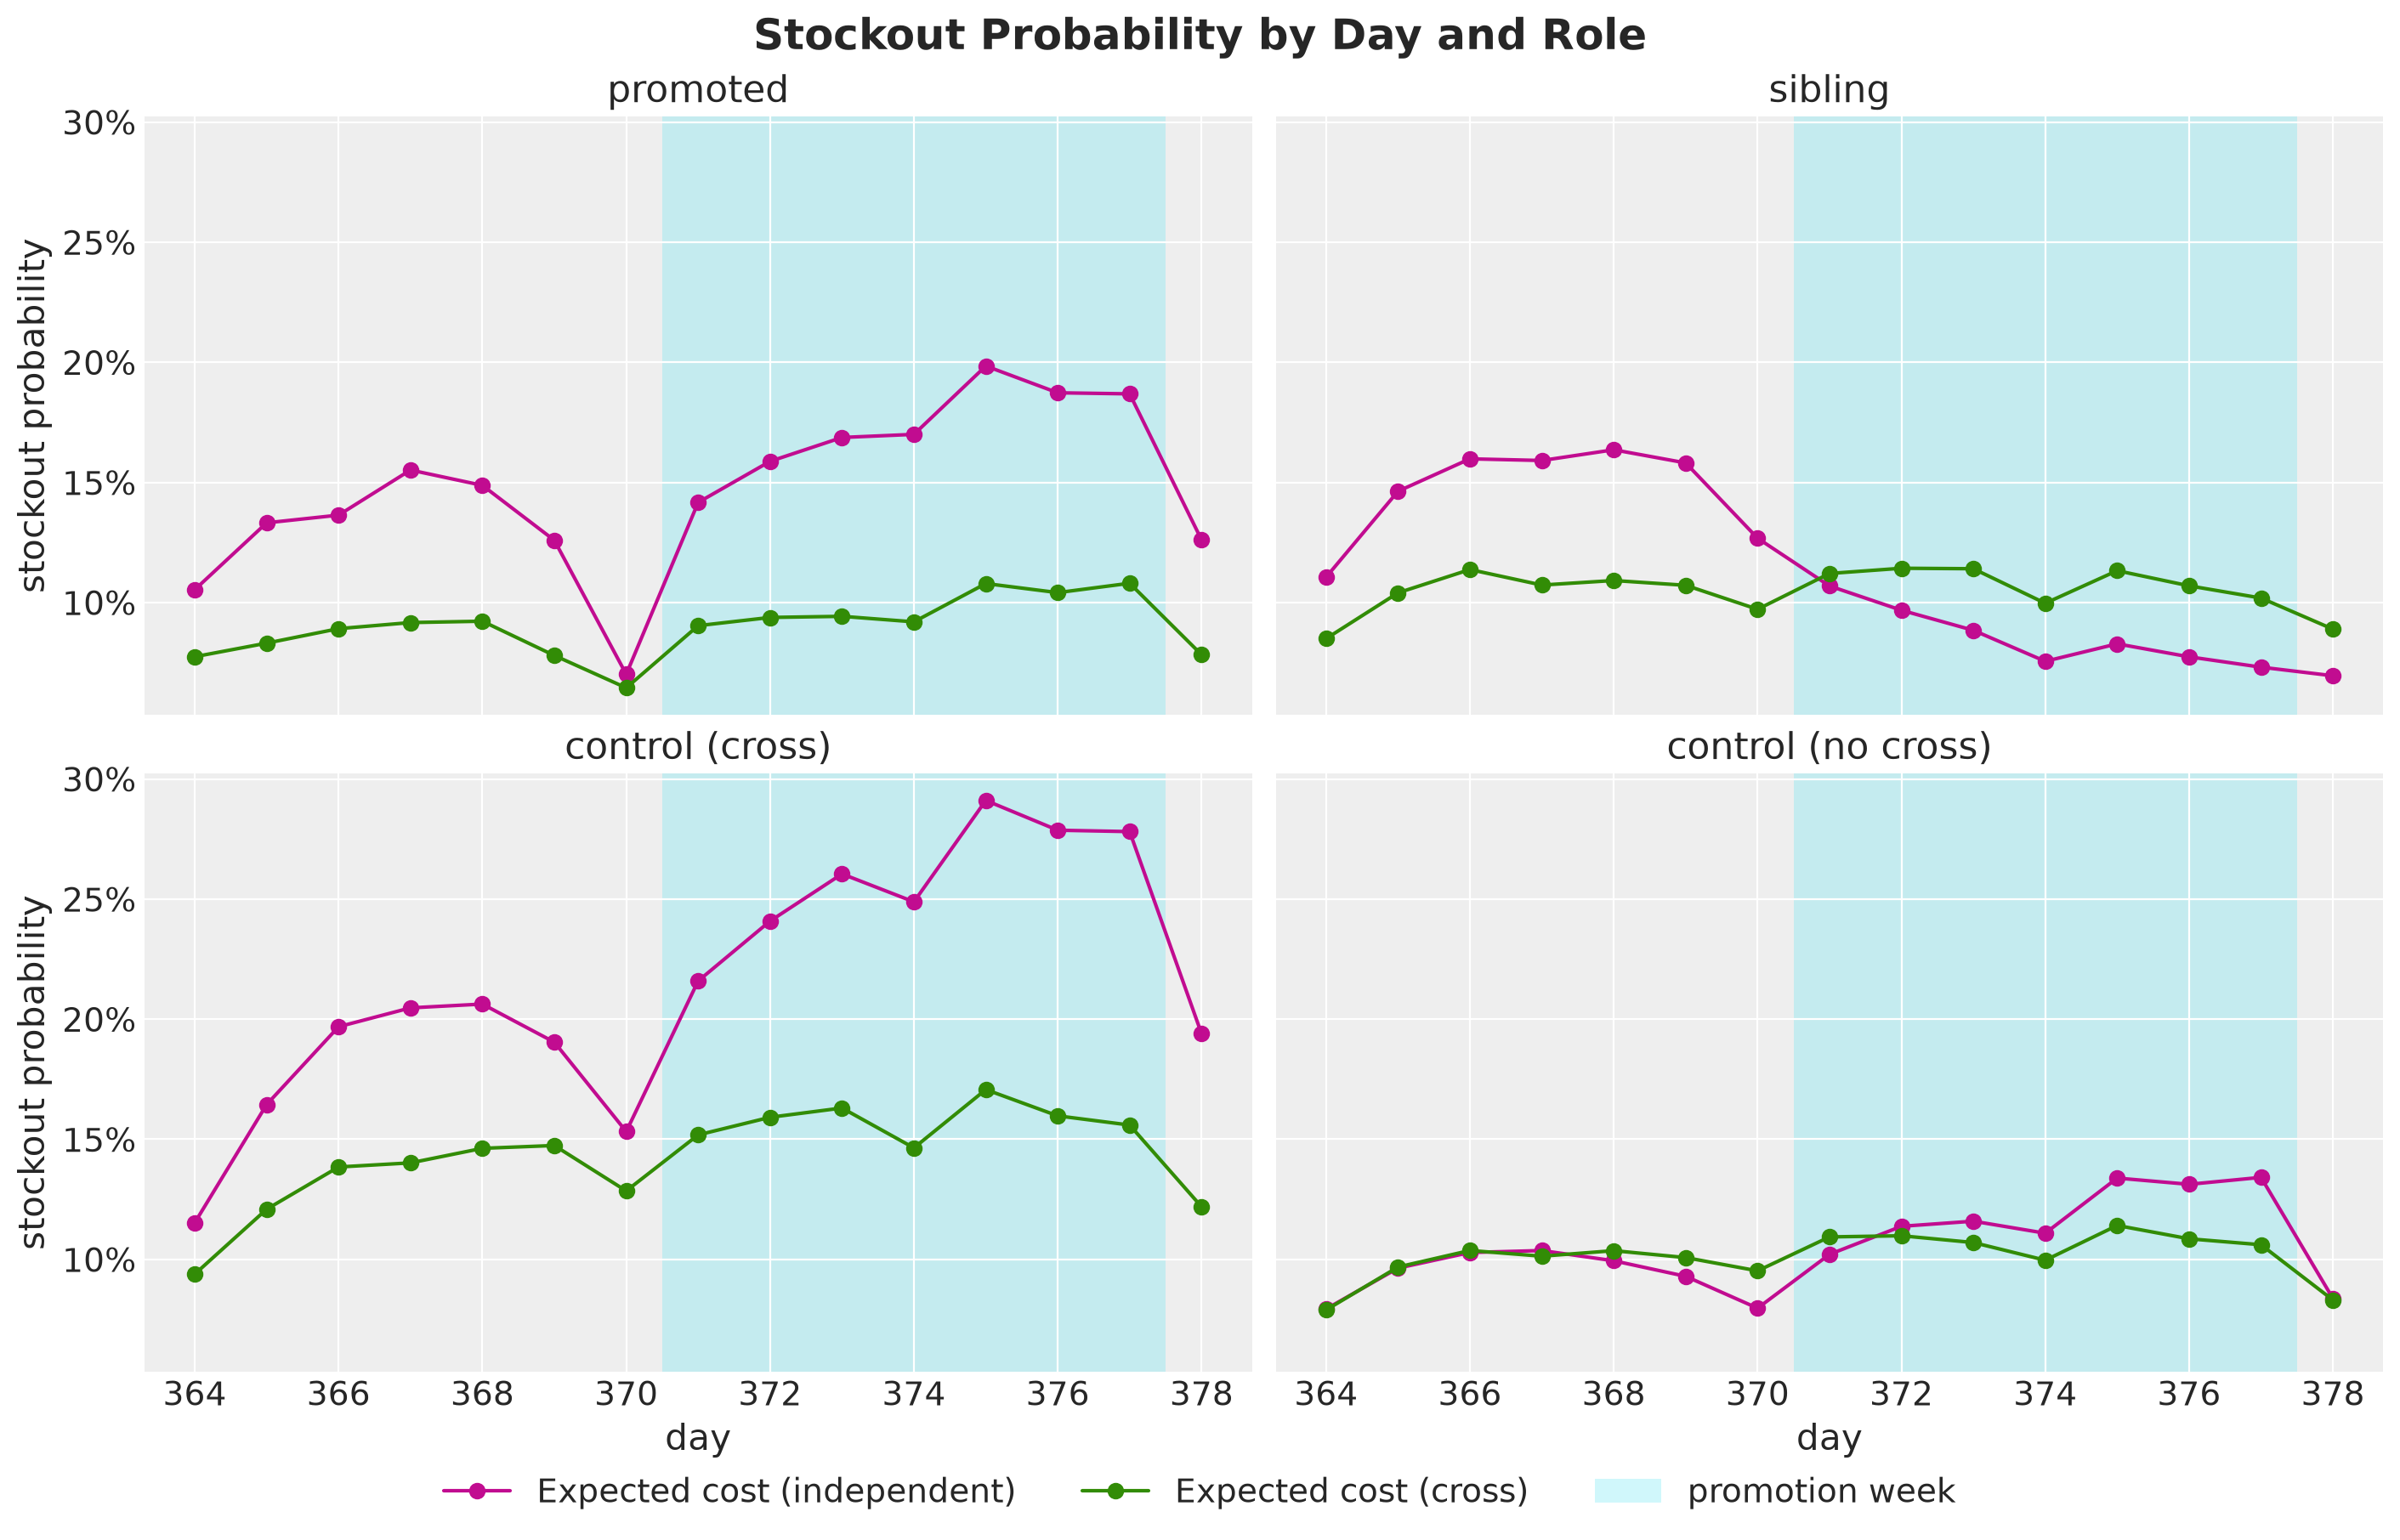

In [58]:
fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(14, 9), sharex=True, sharey=True, layout="constrained"
)
for k, (ax, role) in enumerate(zip(axes.flat, Role, strict=True)):
    for model in models:
        key = (Rule.EXPECTED_COST, model)
        stockout_by_series = is_stockout(scores[key], solver.tol).mean(axis=0)
        ax.plot(
            days_future,
            stockout_by_series[series_role == role].mean(axis=0),
            "o-",
            color=MODEL_COLORS[model],
            label=plans[key].name,
        )
    shade_promotion_week(ax)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set(
        title=role,
        xlabel="day" if k >= 2 else "",
        ylabel="stockout probability" if k % 2 == 0 else "",
    )
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle("Stockout Probability by Day and Role", fontsize=18, fontweight="bold");

The two plans differ on three roles and agree on `control (no cross)`.

- **`promoted`.** The independent plan runs out more often than the cross plan on every day, with the largest difference in the promotion week.
- **`sibling`.** The independent plan runs out more in the first week and less in the promotion week, where it is overstocked.
- **`control (cross)`.** The independent plan runs out more on every day, up to about $29\%$ of the series in the promotion week against about $17\%$ for the cross plan.
- **`control (no cross)`.** The two plans agree within a few points on every day.

Both plans run out less on the day before the promotion week, where they build stock.

So on this panel the cost of ignoring cannibalization comes from the forecast in two ways. The independent model starts the horizon too low on the products whose siblings were just on promotion, and its plan loses sales from the first day. In the promotion week its plan overstocks the siblings, and under a capacity that binds the promoted products get fewer units.

## Capacity Sensitivity

We have seen the gap between the two expected cost plans at one capacity. Here we check whether the capacity creates the gap or only changes it. We sweep the capacity multiple $\kappa$ from $0.9$, where the capacity binds on a regular day, to no capacity at all, and solve the expected cost plan of both models at every value.

We score every plan on the evaluation scenarios and split the gap as in the previous section.

In [59]:
%%time

kappas = [0.9, 1.0, 1.05, 1.1, 1.25, 1.5, float("inf")]
capacity_grid = jnp.array(kappas)[:, None] * regular_throughput[None, :]
# the mean forecast plan depends on the capacity through the projection, so the
# sweep rebuilds it at every capacity and starts each solve from it
mean_plan_sweep = jax.vmap(forward_pass_capacity, in_axes=(None, 0, None))
solve_sweep = jax.jit(
    jax.vmap(
        partial(solve, config=config, solver=solver), in_axes=(None, None, 0, 0, None)
    )
)

orders_sweep = {}
for model in models:
    orders_sweep[model], _ = solve_sweep(
        draws[model].scenarios,
        0.0,
        mean_plan_sweep(
            unflat(mean_demand[model]), capacity_grid, initial_inventory_by_store
        ),
        capacity_grid,
        initial_inventory,
    )
    # at the largest finite multiple the capacity no longer binds
    assert jnp.allclose(orders_sweep[model][-2], orders_sweep[model][-1], atol=1e-3)

sweep_loss, gap_frames = [], []
for k, kappa in enumerate(kappas):
    sims = {
        model: simulate_scenarios(
            flat(orders_sweep[model][k]), demand_eval, initial_inventory, config
        )
        for model in models
    }
    sweep_loss.append(
        {
            "kappa": kappa,
            **{
                f"expected loss ({model})": float(sims[model].loss.sum(axis=-1).mean())
                for model in models
            },
        }
    )
    gap_frames.append(
        gap_frame(sims[Model.INDEPENDENT], sims[Model.CROSS])
        .group_by("role", "period", "part")
        .agg(pl.col("gap").sum())
        .with_columns(kappa=pl.lit(kappa))
    )
sweep_gap = pl.concat(gap_frames)
sweep = (
    pl.DataFrame(sweep_loss)
    .join(
        sweep_gap.group_by("kappa", "part")
        .agg(pl.col("gap").sum())
        .pivot(on="part", index="kappa", values="gap")
        .select("kappa", pl.col([cost.value for cost in Cost]).name.suffix(" gap")),
        on="kappa",
    )
    .with_columns(gap=pl.col(f"{Cost.HOLDING} gap") + pl.col(f"{Cost.LOST_SALES} gap"))
    .sort("kappa")
)
round_losses(sweep, sweep.columns[1:]).with_columns(
    (sweep["gap"] / sweep[f"expected loss ({Model.CROSS})"]).alias("relative gap")
)

CPU times: user 2min 13s, sys: 6.45 s, total: 2min 19s
Wall time: 45.6 s


kappa,expected loss (independent),expected loss (cross),holding gap,lost sales gap,gap,relative gap
f64,i64,i64,i64,i64,i64,f64
0.900,41617,38290,925,2403,3327,0.087
1.000,30167,27231,-548,3483,2936,0.108
1.050,28435,25769,-728,3394,2666,0.103
1.100,28067,25469,-585,3182,2598,0.102
1.250,28013,25430,-471,3054,2583,0.102
1.500,28013,25430,-471,3054,2583,0.102
inf,28013,25430,-471,3054,2583,0.102


We plot the expected loss of both plans and the gap, split into its two parts, against $\kappa$. The figure shows the finite values of $\kappa$, and the plans at $\kappa = 1.5$ are the plans without a capacity.

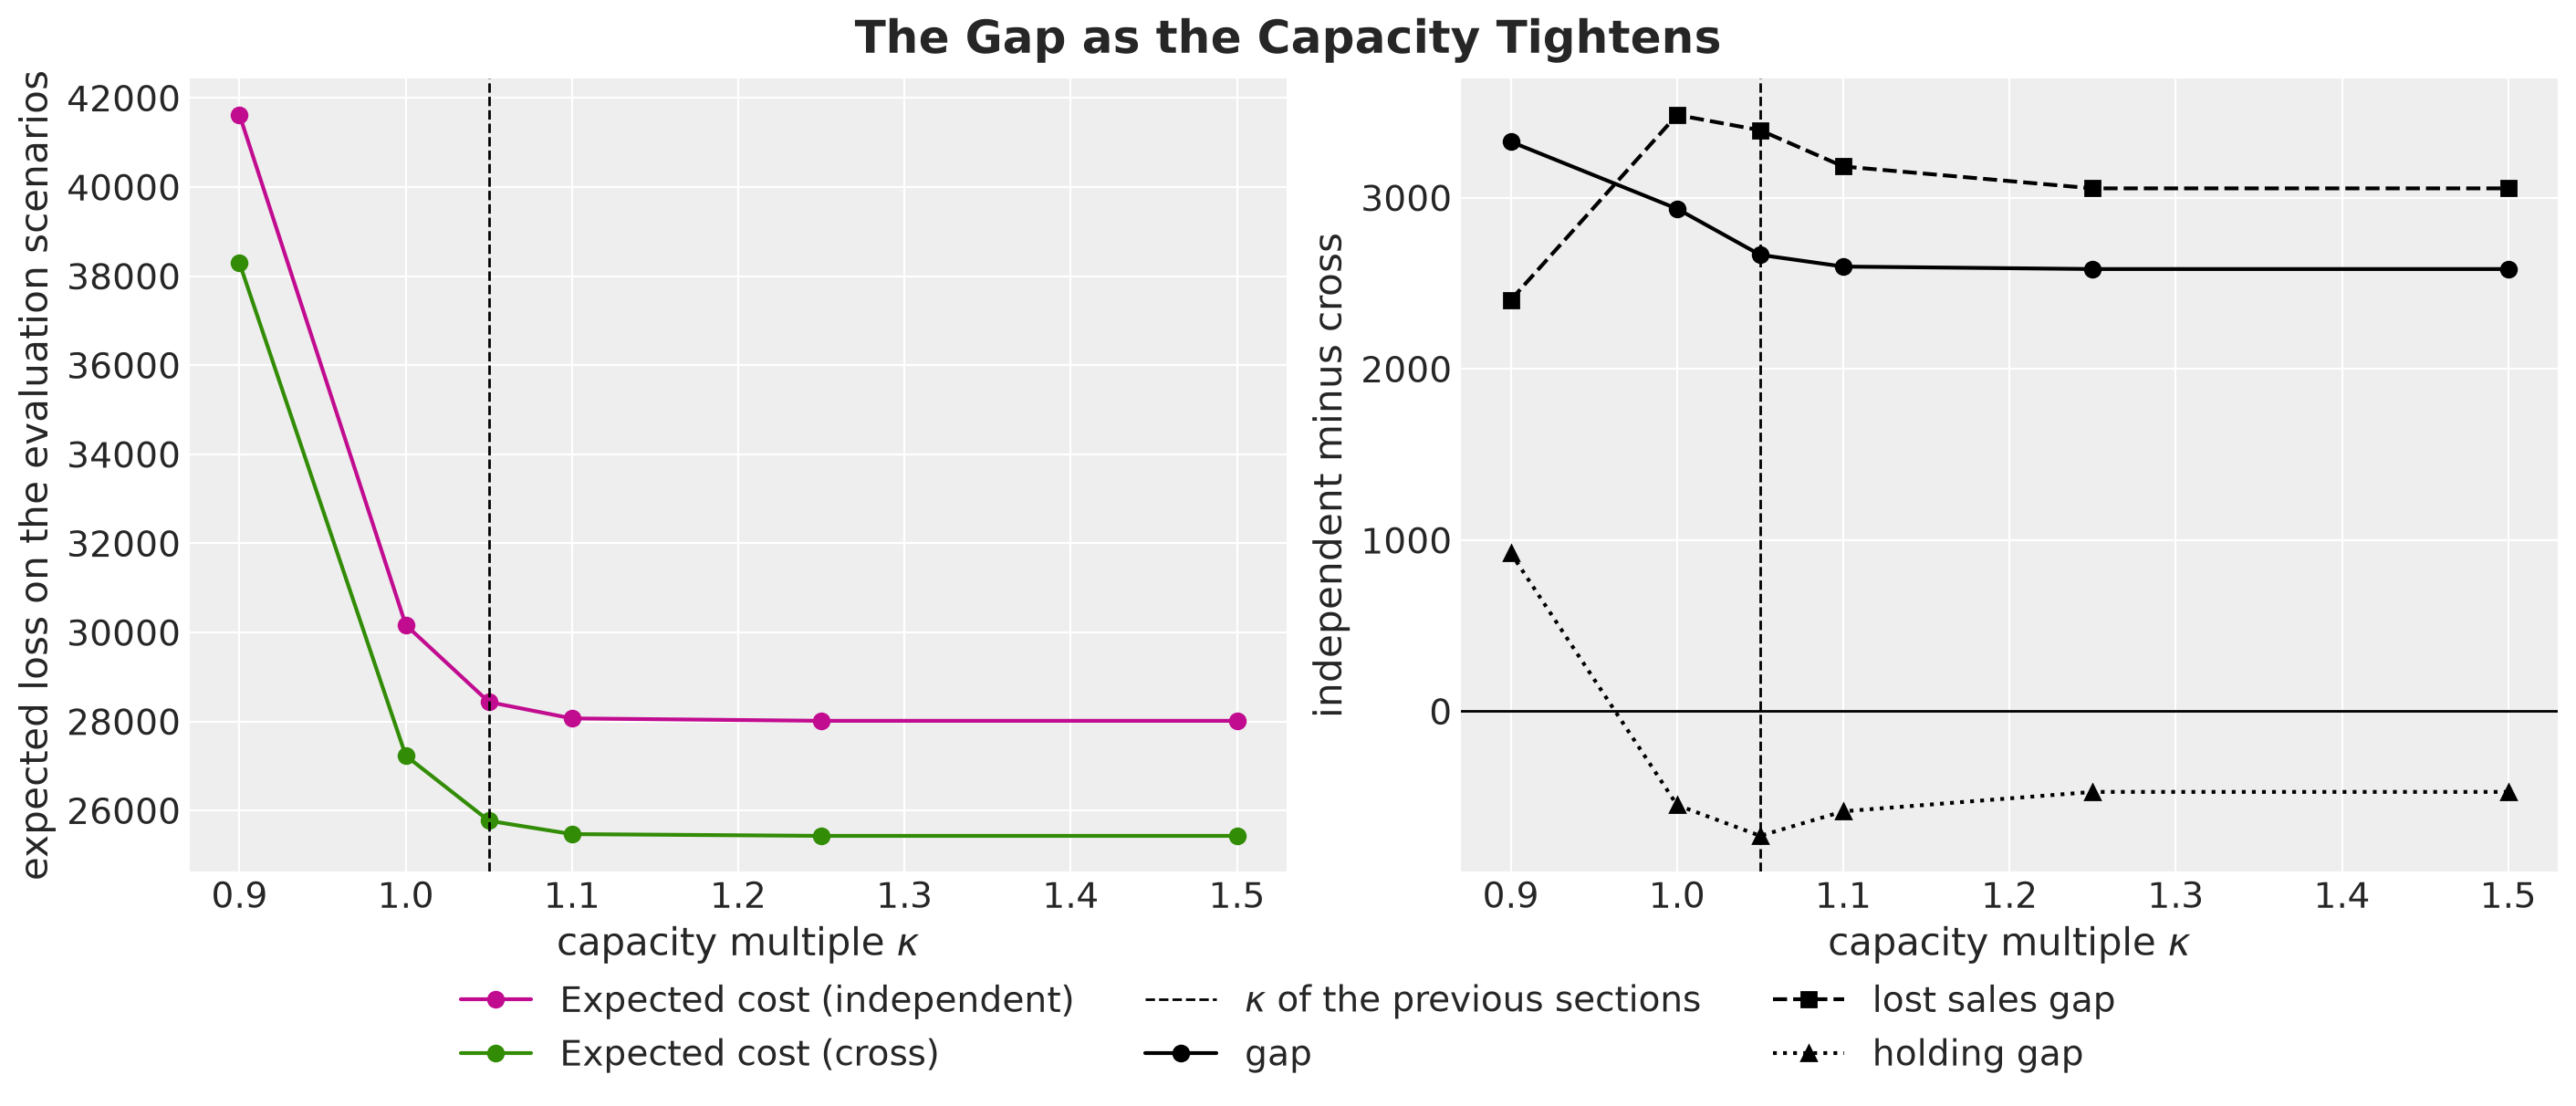

In [60]:
finite = sweep.filter(pl.col("kappa").is_finite())

fig, axes = plt.subplots(ncols=2, figsize=(14, 6), layout="constrained")
ax = axes[0]
for model in models:
    ax.plot(
        finite["kappa"],
        finite[f"expected loss ({model})"],
        "o-",
        color=MODEL_COLORS[model],
        label=plans[Rule.EXPECTED_COST, model].name,
    )
ax.axvline(
    setup.capacity_multiple,
    color="black",
    linestyle="--",
    linewidth=1,
    label=r"$\kappa$ of the previous sections",
)
ax.set(ylabel="expected loss on the evaluation scenarios")
ax = axes[1]
for column, style in [("gap", "o-"), ("lost sales gap", "s--"), ("holding gap", "^:")]:
    ax.plot(finite["kappa"], finite[column], style, color="black", label=column)
ax.axhline(0.0, color="black", linewidth=1)
ax.axvline(setup.capacity_multiple, color="black", linestyle="--", linewidth=1)
ax.set(ylabel="independent minus cross")
for ax in axes:
    ax.set(xlabel=r"capacity multiple $\kappa$")
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("The Gap as the Capacity Tightens", fontsize=18, fontweight="bold");

The gap is there at every capacity.

- **Without a capacity.** The gap is $2{,}583$, or $10.2\%$ of the cross plan's loss, with $3{,}054$ more in lost sales under the independent plan and $471$ less in holding.
- **At $\kappa = 1.05$.** The gap is $2{,}666$, or $10.3\%$, with $3{,}394$ more in lost sales and $728$ less in holding.
- **At $\kappa = 0.9$.** Both plans lose sales on a regular day and both losses rise by almost half. The gap is $3{,}327$, or $8.7\%$ of the cross plan's loss.

To separate the low start from the capacity in the promotion week, the next table compares the lost sales part of the gap in that week, by role, at $\kappa = 1.05$ and without a capacity.

In [61]:
capacity_labels = {
    setup.capacity_multiple: f"at kappa = {setup.capacity_multiple:g}",
    float("inf"): "without a capacity",
}
round_losses(
    sweep_gap.filter(
        (pl.col("period") == Period.PROMOTION_WEEK.value)
        & (pl.col("part") == Cost.LOST_SALES.value)
        & pl.col("kappa").is_in(list(capacity_labels))
    )
    .with_columns(
        capacity=pl.col("kappa").replace_strict(capacity_labels, return_dtype=pl.String)
    )
    .sort("kappa")
    .pivot(on="capacity", index="role", values="gap")
    .sort(pl.col("role").cast(pl.Enum([role.value for role in Role]))),
    list(capacity_labels.values()),
)

role,at kappa = 1.05,without a capacity
str,i64,i64
"""promoted""",1070,596
"""sibling""",-293,-424
"""control (cross)""",703,432
"""control (no cross)""",98,20


Without a capacity the promoted products still have $596$ of the $1{,}070$ in extra lost sales, and `control (cross)` has $432$ of the $703$. The larger part of the lost sales gap of these two roles comes from the forecast, and the capacity adds the rest.

On `control (no cross)` the gap falls from $98$ to $20$. The two models agree on this group, so its gap at $\kappa = 1.05$ comes from the shared capacity.

So on this panel the capacity changes the composition of the gap more than its size. Most of the gap is there without a capacity, and the capacity moves part of it between products.

## Conclusion

### Key Findings

These findings come from one panel and one seed.

- **Cost of ignoring cannibalization.** On the evaluation scenarios the independent plan costs $10\%$ more than the cross plan. The cross plan is cheaper in every scenario of this history.
- **Decision rule.** The mean forecast plans cost $21\%$ and $14\%$ more than the expected cost plans of the same model, so the decision rule matters about as much as the model.
- **Groups.** Group $1$, with the largest cross elasticity and a sibling promotion in the last week of the history, accounts for $70\%$ of the gap. The two groups with a cross elasticity of $0.3$ account for $6\%$ and $20\%$, and the two groups without cannibalization for about $2\%$ each.
- **Start of the forecast.** The level of the independent model is lower on the products whose siblings were on promotion in the last weeks of the history, more so where the cross elasticity is larger. On the other products the two models start at the same level. Three products with a low start account for most of the gap of the first week.
- **Promotion week.** The independent plan overstocks the siblings, whose demand dips by $10\%$ to $19\%$, and the promoted products lose more sales. Among the siblings the gap is the largest on the one whose forecast started at the right level, and the two errors cancel on the siblings that started low.
- **Capacity.** The gap is $10.2\%$ without a capacity and $10.3\%$ at $\kappa = 1.05$. The capacity moves part of the gap between products more than it changes its size.
- **Calibration metrics.** The CRPS of the two models differ by $4\%$ and both cover the realized future at about $94\%$, while their plans differ by $10\%$ in cost.
- **Groups without cannibalization.** Their gap is $62$ and $44$ of a total of $2{,}666$. It arises in the promotion week, where these groups share the capacity with the others.
- **Variational inference.** The DCT basis recovers the drift scale and the concentration, and the plain basis recovers neither. The mean-field guide is overconfident about the level of every series by a factor of two or more, and the expected cost plans cost $11\%$ to $15\%$ more on the evaluation scenarios than on their own scenarios.

### Model Limitations

- **Mean-field posterior.** The guide understates the uncertainty about the level at the end of the history by a factor of two or more, and its intervals cover the drift scale for about half of the series. The plans keep their order, but they cost more on the evaluation scenarios than on their own scenarios. On real data we would compare the guide with NUTS on a subset of the series, or use a guide with a full covariance over the global parameters.
- **Independent series.** The levels and the noise of the series are independent in the generator, with no shock common to a store or to the chain. The tail of the total loss is thin for that reason. A tail weight lowers the tail by about $2\%$ on the scenarios of the model and not at all on the evaluation scenarios. Real demand has common shocks, such as weather and holidays.
- **No cross-period effects.** A promotion in the generator lifts the demand of its own week and leaves the following weeks untouched. [van Heerde, Leeflang and Wittink (2004)](https://doi.org/10.1287/mksc.1040.0061) attribute about a third of the promotion bump to demand borrowed from other periods. A dip after a promotion would matter for a plan that starts right after a promotion week.
- **Synthetic truth.** The checks against the true parameters, the true level and the evaluation scenarios exist only because we simulated the data. On real data we would rely on backtests that start the forecast on several days.
- **One promotion pattern.** The promotions are chain-wide (a product is on promotion in every store at once), and the cross elasticities are constant within a group and over time. Store-specific promotions and elasticities that change with the depth of the cut or the display support would need their own terms.
- **No recourse, no lead time.** All orders are fixed today and arrive on the day we planned them for. A rolling horizon that re-forecasts and re-solves every day would see the low start and the dip of the siblings after a few days of sales. A lead time would move the decision to the stock projected at the delivery date.
- **Unconstrained demand history.** The models see the demand itself. In a real lost-sales setting the history is sales, which are censored on the days the shelf was empty, and the dips of a sibling promotion would mix with the dips of an empty shelf.
- **Cost assumptions.** A lost sale costs the same margin on every product and day, and leftovers keep their value.
- **One panel.** The numbers come from one panel, one promotion calendar and one seed. The size of the gap depends on where the last promotions of the history fall, and how tight $\kappa = 1.05$ is depends on which products are promoted.

### Recommendations

1. **Model the siblings when you plan a promotion.** The cross-price term is one matrix of shrunk coefficients, and the data identify it from the weeks in which a sibling was on promotion. Without it the plan loses sales before the promotion, on the products whose siblings were just promoted. During the promotion it overstocks the siblings.
2. **Look at the promotion calendar of the last weeks.** If a sibling of a product was on promotion just before the last day of the history, a model without cross effects can start that product low. A backtest that starts right after a sibling promotion shows whether it does.
3. **Keep a control group.** A group that the model change should not affect is a check of the comparison. Compare its forecasts under the two models, and compare its plans without the shared capacity, since the capacity links it to the other groups.
4. **Report how tight the capacity is.** The same forecast error costs holding when the capacity is slack and lost sales on other products when it binds. Report the mean demand as a share of the capacity in the promotion week.

## Next Steps

1. **Promotion choice.** Make the discount, the week and the products of the promotion decisions, with the cannibalization in the objective. The [promotion pricing example](https://github.com/juanitorduz/numpyro_forecast/pull/121) of `numpyro_forecast` does this on real data, with a six-product substitution group and a break-even analysis of the promotion.
2. **Store-specific elasticities.** Let the own and cross elasticities vary by store around a product-level mean, with partial pooling, so that stores with a different mix of customers get their own promotion response.
3. **Lead time and rolling horizon.** Add a pipeline of in-transit orders to the carry of the simulator and wrap the solve in `numpyro_forecast.backtest`, so that each window re-forecasts, re-solves and commits one order. Several starting days would also average over the promotion calendar of the last weeks.
4. **Censored sales.** Replace the demand history by a sales history with a censored likelihood on the days with an empty shelf, as in the [censored demand example](https://juanitorduz.github.io/numpyro_forecast/docs/examples/censored_demand.html) of `numpyro_forecast`.
5. **A full-rank guide on the global parameters.** Keep the mean-field guide on the $72{,}800$ increments and put a multivariate Normal on the product-level parameters and the level of every series at the end of the history. Then measure how much of the difference between the loss on the own scenarios and the loss on the evaluation scenarios goes away.
6. **Common shocks.** Add a shock common to the series of a store to the generator and to the model, and check whether the tail weight and the joint draws across series start to matter.

## References

- Orduz, J. (2026). [From Forecasts to Decisions: Inventory Planning with Probabilistic Programming](https://juanitorduz.github.io/forecast_to_decision/). Personal blog.
- Szabłowski, B. (2026). [One Global Model, Many Behaviors: Stockout-Aware Feature Engineering and Dynamic Scaling for Multi-Horizon Retail Demand Forecasting with a Cost-Aware Ordering Policy (VN2 Winner Report)](https://arxiv.org/abs/2601.18919). arXiv:2601.18919.
- van Heerde, H. J., Leeflang, P. S. H. and Wittink, D. R. (2004). [Decomposing the Sales Promotion Bump with Store Data](https://doi.org/10.1287/mksc.1040.0061). *Marketing Science*, 23(3), 317-334.
- Duchi, J., Shalev-Shwartz, S., Singer, Y. and Chandra, T. (2008). [Efficient Projections onto the $\ell_1$-Ball for Learning in High Dimensions](https://doi.org/10.1145/1390156.1390191). *Proceedings of the 25th International Conference on Machine Learning*, 272-279.
- Blei, D. M., Kucukelbir, A. and McAuliffe, J. D. (2017). [Variational Inference: A Review for Statisticians](https://doi.org/10.1080/01621459.2017.1285773). *Journal of the American Statistical Association*, 112(518), 859-877.
- Shapiro, A., Dentcheva, D. and Ruszczyński, A. (2021). [Lectures on Stochastic Programming: Modeling and Theory](https://doi.org/10.1137/1.9781611976595), third edition. SIAM.
- Pyro developers. [Forecasting with `pyro.contrib.forecast`](https://docs.pyro.ai/en/stable/contrib.forecast.html), the module whose `time_reparam` option `numpyro_forecast` ports.
- NumPyro developers. [Example: Hilbert space approximation for Gaussian processes](https://num.pyro.ai/en/stable/examples/hsgp.html).
- Orduz, J. [NumPyro Forecast documentation](https://juanitorduz.github.io/numpyro_forecast/).
- Orduz, J. [Promotion pricing decisions on the Breakfast at the Frat panel](https://github.com/juanitorduz/numpyro_forecast/pull/121). `numpyro_forecast` pull request.
- PreliZ developers. [PreliZ documentation](https://preliz.readthedocs.io/).
- DeepMind. [Optax documentation](https://optax.readthedocs.io/).